# Clearview Properties — Residential Price Analysis

Technical notebook for the Clearview Properties brief: the whole analysis end to end, with the evidence behind every decision.

## Executive summary
- **Q1 – Listing range.** A model trained on past sales gives every home a reference price, an 80% listing range and a 50% negotiation band. On sales it had never seen, the ranges contained the stated share of sales in every price tier. → [Section 3](#s3)
- **Q2 – What drives price.** The building's size and age matter most, then its overall quality and condition. Owner-modifiable features add comparatively little that is unique. Location matters, but far less than raw neighborhood prices suggest. → [Section 4](#s4)
- **Q3 – Profitable improvements.** Few improvements pay for themselves at resale. Low-cost fixes of clear deficiencies come closest, and each improvement's break-even cost is the figure to use with owners. → [Section 5](#s5)
- **Q4 – Market segments.** The market splits into two halves, older and smaller vs newer and larger homes, located in largely different neighborhoods. Quality is worth more in the newer half, and one price model serves both. → [Section 6](#s6)

## Contents
- [0. Setup and reproducibility](#s0)
  - [Raw data, loaded as delivered](#s0-raw)
  - [0.1 Toolbox](#s0-1)
- [1. Data quality audit and cleaning](#s1)
  - [1.1 Data dictionary: variable meanings and valid codes](#s1-1)
  - [1.2 Audit of the raw file](#s1-2)
  - [1.3 Repair pipeline](#s1-3)
  - [1.4 Verification: re-run the audit on the cleaned data](#s1-4)
  - [1.5 Analysis sample: which sales the price models learn from](#s1-5)
  - [1.6 Lot Frontage: dropped (team decision)](#s1-6)
  - [1.7 Remaining missing values: investigation](#s1-7)
  - [1.8 Key results and data quality log](#s1-8)
- [2. Exploratory data analysis and feature engineering](#s2)
  - [2.1 New variables computed from the data](#s2-1)
  - [2.2 Train/test split (before any analysis)](#s2-2)
  - [2.3 Target: model the price or its logarithm?](#s2-3)
  - [2.4 Time: did prices move between 2006 and 2010?](#s2-4)
  - [2.5 Location and age](#s2-5)
  - [2.6 Shared modeling tools](#s2-6)
  - [2.7 Variable selection](#s2-7)
  - [2.8 Lot Frontage: cross-validation check (Section 1.6)](#s2-8)
  - [2.9 Key results](#s2-9)
- [3. Q1 — Price range model](#s3)
  - [3.1 Candidate models and their tuning](#s3-1)
  - [3.2 A single model or a blend?](#s3-2)
  - [3.3 Final check on the test set, and over time](#s3-3)
  - [3.4 Listing range and negotiation band](#s3-4)
  - [3.5 Valuation card for brokers](#s3-5)
  - [3.6 Key results](#s3-6)
- [4. Q2 — Price drivers](#s4)
  - [4.1 Groups of characteristics](#s4-1)
  - [4.2 How much does each group matter?](#s4-2)
  - [4.3 Which individual characteristics matter most?](#s4-3)
  - [4.4 How much is location worth?](#s4-4)
  - [4.5 Key results](#s4-5)
- [5. Q3 — Improvement return on investment](#s5)
  - [5.1 Key results](#s5-1)
- [6. Q4 — Market segmentation](#s6)
  - [6.1 How many segments?](#s6-1)
  - [6.2 Who is in each segment?](#s6-2)
  - [6.3 Do the segments behave differently?](#s6-3)
  - [6.4 Does one price model serve both segments?](#s6-4)
  - [6.5 Key results](#s6-5)
- [7. Conclusions, limitations and next steps](#s7)
  - [Answers to the client's questions](#s7-answers)
  - [Limitations](#s7-limitations)
  - [Next steps](#s7-next)

## Use of AI tools
As the brief requires, we declare the AI tools used. Claude (Anthropic, through Claude Code) helped set up the reproducible environment and write the data quality audit and cleaning (Sections 0–1). Google Antigravity (Gemini) helped extend the audit and write a first version of Sections 2–7 and of the client presentation. Claude was then used to review the notebook section by section against the original analysis plan. In every case the tools proposed code and alternatives, and the team made the decisions. Each reviewed section ends with a **"Decisions and rationale"** box that records what was decided, the alternatives considered and the evidence. Results were checked by rerunning the whole notebook in the pinned environment.

<a id="how-to-read"></a>

## How to read this notebook

- **Section template.** Each section opens with **In brief** (the answer in words), then shows the method and the evidence, prints its **Key results** from the code, and closes with **Decisions and rationale**: what was decided, the alternatives considered, and why.
- **Code is collapsed.** Click a cell's placeholder to expand it. Shared helper functions are in [0.1 Toolbox](#s0-1).
- **Numbers come from code.** Results are printed by the code cells, never typed by hand, so the text and the results cannot disagree.

**Terms in plain words**

| Term | Meaning |
|---|---|
| Typical % error (MAPE) | Average size of the pricing error, as a percentage of the sale price. |
| Average $ error (MAE) | Average size of the pricing error, in dollars. |
| Median error | Half of the homes are priced closer than this. |
| RMSE of log price | The error measure used to fit and compare models. For small values it reads roughly as a typical percentage error (0.10 ≈ 10%). |
| Training set / test set | Sales the models learn from (80%) / sales kept aside and used only once, at the end, to measure accuracy on unseen homes (20%). |
| Cross-validation | Repeatedly holding out one fifth of the training sales, fitting on the rest and measuring the error on the held-out part. Models are compared and tuned without touching the test set. |
| 95% interval | The range that, given the data, very likely contains the true value. |
| Bootstrap | Re-sampling the data many times to see how much a result moves. It produces the intervals. |
| Calibrated range | A price range sized from past errors so that it contains a stated share of sales (for example 80%). |
| Permutation importance | How much worse the model gets when one input, or a group of inputs, is scrambled. |
| Silhouette / stability (ARI) | How distinct the market segments are / how reliably the same segments reappear when the data is re-sampled. |
| Robust standard errors (HC1) | A way of computing intervals that does not assume all homes are equally predictable. |
| Association | A relationship observed in past sales. It does not prove that changing one thing would change the price. |

<a id="s0"></a>

## 0. Setup and reproducibility

> **In brief.** *Purpose:* anyone can rerun this notebook and get the same results. *How:* pinned software versions, one random seed, deterministic models, and a setup check that stops if the environment is wrong. *Decisions:* [end of section](#s0-decisions).

All randomness in this notebook comes from one constant, `SEED`. It is passed as `random_state` to every split, cross-validation splitter, model and clustering algorithm. Our own random steps (bootstraps, permutations) each get a separate generator from `rng_for(task)`, derived from `SEED` and the task's name. As a result, a task's result does not depend on which cells ran before it. The environment is pinned with `uv.lock`; see the README for setup instructions.

In [1]:
import os
import random
import re
import sys
import zlib
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import lightgbm
import statsmodels.api as sm

# --- Reproducibility -------------------------------------------------------
# Results are only guaranteed inside the project's uv environment (Python 3.12 + uv.lock).
assert sys.version_info[:2] == (3, 12), (
    f"Python {sys.version.split()[0]} detected: run this notebook with the project's uv environment "
    "(`uv sync`, then select the .venv kernel or use `uv run jupyter ...`). See README.")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)              # legacy global state, for libraries that still use it


def rng_for(task):
    """Independent, reproducible random generator for one named task (bootstrap, permutation...).

    Seeded from SEED and the task name, so the result does not depend on which cells ran before.
    Calling it twice with the same name gives the same random draws (used to compare models on
    identical bootstrap samples).
    """
    return np.random.default_rng([SEED, zlib.crc32(task.encode())])

# Inherited by any worker subprocesses (e.g. joblib). It cannot change hashing in the
# already-running kernel, and none of our results depend on that.
os.environ["PYTHONHASHSEED"] = str(SEED)

# --- Paths (resolved from the project root, so it runs from any working directory) ---
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA_DIR = ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
FIG_DIR = ROOT / "main" / "figures"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# --- Display and chart defaults ----------------------------------------------
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
# Colorblind-safe categorical slots (validated reference palette; max 3 hues per chart),
# plus a neutral gray for context marks and recessive text/grid tones.
COLORS = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "gray": "#9a9993",
          "text": "#0b0b0b", "text2": "#52514e", "grid": "#e4e3df", "surface": "#fcfcfb"}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.facecolor": COLORS["surface"], "axes.facecolor": COLORS["surface"],
    "savefig.facecolor": COLORS["surface"], "axes.edgecolor": COLORS["grid"],
    "axes.labelcolor": COLORS["text2"], "axes.titlecolor": COLORS["text"],
    "xtick.color": COLORS["text2"], "ytick.color": COLORS["text2"],
    "grid.color": COLORS["grid"], "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
USD = mticker.FuncFormatter(lambda v, _: f"${v / 1000:,.0f}k")


def save_fig(fig, name):
    """Export a figure to main/figures/ (used later for the client deck)."""
    fig.savefig(FIG_DIR / f"{name}.png")


print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | lightgbm {lightgbm.__version__} | matplotlib {matplotlib.__version__}")
print(f"Project root: {ROOT}")

Python 3.12.14 | pandas 3.1.1 | numpy 2.5.5 | scikit-learn 1.9.1 | lightgbm 4.7.0 | matplotlib 3.11.2
Project root: C:\Users\danio\Documents\EAFIT_Maestria_CienciasIng\Clases 2026-02\Aprendizaje Automático\proyecto-final-ml


<a id="s0-raw"></a>

### Raw data, loaded as delivered

The raw file is never modified. Every cleaning step in Section 1 is applied in code to a copy.

`keep_default_na=False` makes pandas read the text exactly as written: only empty cells count as missing. Without it, pandas would silently turn codes such as `"NA"` or `"N/A"` into missing values, hiding part of the quality problem we need to measure.

In [2]:
raw = pd.read_csv(DATA_DIR / "Data.csv", keep_default_na=False, na_values=[""])
print(f"Raw shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Raw shape: 2,963 rows x 82 columns


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,2693,903454020.0,30.0,RM,50.0,9000,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,IDOTRR,Norm,Norm,1Fam,1Story,5.0,4.0,1919.0,1950.0,Gable,CompShg,Wd Sdng,Wd Sdng,NaN,0.0,TA,TA,BrkTil,TA,TA,No,Unf,0.0,Unf,0.0,610.0,610.0,GasA,Ex,N,FuseA,819.0,0.0,0.0,819.0,0.0,0.0,1.0,0.0,2.0,1.0,Gd,4.0,Typ,0.0,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,N,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,9.0,2006.0,WD,Abnorml,72000
1,252,906385010.0,20.0,RL,94.0,10402,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,CollgCr,Norm,Norm,1Fam,1Story,7.0,5.0,2009.0,2009.0,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,Unf,0.0,Unf,0.0,1226.0,1226.0,GasA,Ex,Y,SBrkr,1226.0,0.0,0.0,1226.0,0.0,0.0,2.0,0.0,3.0,1.0,Gd,6.0,Typ,0.0,NaN,Attchd,2009.0,RFn,3.0,740.0,TA,TA,Y,0.0,36.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,5.0,2010.0,WD,Normal,198900
2,2146,907252020.0,60.0,RL,NaN,9375,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,8.0,5.0,2002.0,2002.0,Gable,CompShg,VinylSd,VinylSd,BrkFace,149.0,Gd,TA,PConc,Gd,TA,No,Unf,0.0,Unf,0.0,1284.0,1284.0,GasA,Ex,Y,SBrkr,1284.0,885.0,0.0,2169.0,0.0,0.0,2.0,1.0,3.0,1.0,Gd,7.0,Typ,1.0,Gd,Attchd,2002.0,RFn,2.0,647.0,TA,TA,Y,192.0,87.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,8.0,2007.0,WD,Normal,228500
3,2480,531451290.0,60.0,RL,70.0,9370,Pave,NaN,IR2,Lvl,AllPub,Inside,Gtl,SawyerW,Norm,Norm,1Fam,2Story,6.0,5.0,1992.0,1993.0,Gable,CompShg,HdBoard,HdBoard,NaN,0.0,Gd,TA,PConc,Gd,TA,No,ALQ,758.0,Unf,0.0,78.0,836.0,GasA,Ex,Y,SBrkr,844.0,887.0,0.0,1731.0,1.0,0.0,2.0,1.0,3.0,1.0,Gd,7.0,Typ,0.0,NaN,Attchd,1992.0,RFn,2.0,462.0,TA,TA,Y,307.0,85.0,0.0,0.0,224.0,0.0,NaN,NaN,Othr,3000.0,10.0,2006.0,WD,Family,248500
4,316,916386010.0,20.0,RL,88.0,11896,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Timber,Norm,Norm,1Fam,1Story,7.0,5.0,2008.0,2008.0,Gable,CompShg,VinylSd,VinylSd,Stone,60.0,Gd,TA,PConc,Gd,TA,No,GLQ,78.0,Unf,0.0,1258.0,1336.0,GasA,Ex,Y,SBrkr,1346.0,0.0,0.0,NaN,1.0,0.0,2.0,0.0,3.0,1.0,Gd,6.0,Typ,1.0,TA,Attchd,2008.0,Fin,3.0,660.0,TA,TA,Y,100.0,48.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,5.0,2010.0,WD,Normal,220000


<a id="s0-1"></a>

### 0.1 Toolbox

The shared helper functions, gathered in one place: documentation of variables, bootstrap intervals and model building. These cells only **define** functions. When the functions are called, they use objects created in later sections, such as the training data, the cross-validation folds and the model settings. Step-specific functions stay next to the step they explain.

In [3]:
from itertools import product

import lightgbm as lgb
from scipy.optimize import nnls
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet, Ridge
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score, root_mean_squared_error
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler

In [4]:
# --- Documentation: the data dictionary and computed variables ---

def parse_dictionary(path, columns):
    """Read the client's data dictionary.

    Returns three dicts:
      descriptions: {column: meaning}, including notes such as "NaN = no alley access";
      codes:        {column: {code: meaning}} for coded columns (neighborhoods are listed without meanings);
      absent_notes: {column: note} from the final "NOTES ON MISSING VALUES" section: columns where an empty
                    value means the feature does not exist ("the rest of Garage * columns" is expanded).
    """
    descriptions, codes, absent_notes, current, in_notes = {}, {}, {}, None, False
    for line in path.read_text(encoding="utf-8").splitlines():
        if line.startswith("NOTES ON MISSING"):                 # final section: missing-value notes
            in_notes = True
            continue
        if in_notes:                                            # "  Garage Type    NaN = no garage  (and the rest of Garage * columns)"
            note = re.match(r"^\s+(\S.*?)\s{2,}(NaN = .*?)\s*(?:\(and the rest of (\w+) \* columns\))?$", line)
            if note and note.group(1) in columns:
                group = note.group(3)
                for col in ([c for c in columns if group in c] if group else [note.group(1)]):
                    absent_notes[col] = note.group(2).strip()
            continue
        header = re.match(r"^(\S.*?)\s{2,}(\S.*)$", line)          # "Column Name   meaning"
        if header and header.group(1) in columns:
            current = header.group(1)
            descriptions[current] = header.group(2).rstrip(":")
            continue
        if current is None or not line.startswith(" "):
            continue
        entry = re.match(r"^\s{10,}(\S.*?)\s{2,}(\S.*)$", line)    # "      CODE   meaning"
        if entry:
            codes.setdefault(current, {})[entry.group(1)] = entry.group(2)
        elif current == "Neighborhood" and "," in line:           # neighborhoods are listed inline
            codes[current] = {c.strip(): "" for c in line.split(",")}
        elif not line.strip().endswith(":"):                      # note such as "NaN = no alley access"
            descriptions[current] += "; " + line.strip()
    for col, note in absent_notes.items():                      # show the note next to the meaning
        if note not in descriptions[col]:
            descriptions[col] += f"; dictionary note: {note}"
    return descriptions, codes, absent_notes


# Variables we compute ourselves: meaning, formula and why they exist (shown next to dictionary variables).
ENGINEERED = {}


def define_variable(name, meaning, formula, why):
    """Register a computed variable so that every 'Variables used here' table can explain it."""
    ENGINEERED[name] = {"meaning": meaning, "formula": formula, "why": why}


def codes_text(col, max_codes=8):
    """Readable list of a column's codes, e.g. 'N = No; Y = Yes' (long lists are shortened)."""
    items = [f"{c} = {m}" if m else c for c, m in VAR_CODES.get(col, {}).items()]
    if len(items) > max_codes:
        return "; ".join(items[:max_codes]) + f"; ... ({len(items)} codes)"
    return "; ".join(items)


def variables_table(roles):
    """Show the variables behind a section. `roles` maps each variable to its role in the section.

    Meanings and codes come from the data dictionary; computed variables come from ENGINEERED
    (pass None as the role to show why the variable was created)."""
    rows = []
    for name, role in roles.items():
        if name in VAR_DESCRIPTIONS:
            rows.append({"Variable": name, "Source": "Data dictionary", "Meaning": VAR_DESCRIPTIONS[name],
                         "Codes / formula": codes_text(name) or "numeric", "Role in this section": role})
        elif name in ENGINEERED:
            e = ENGINEERED[name]
            rows.append({"Variable": name, "Source": "Computed", "Meaning": e["meaning"],
                         "Codes / formula": e["formula"], "Role in this section": role or e["why"]})
        else:
            raise KeyError(f"{name!r} is neither in the data dictionary nor registered with define_variable()")
    with pd.option_context("display.max_colwidth", None):
        display(pd.DataFrame(rows).set_index("Variable"))

In [5]:
# --- Statistics ---

def bootstrap_ci(statistic, *arrays, task, n_boot=2000):
    """Statistic with a 95% bootstrap interval, returned as (estimate, low, high).

    The rows are resampled with replacement n_boot times. The same task name always gives the same resampled rows,
    so several models scored with one task name are compared on identical samples."""
    arrays = [np.asarray(a) for a in arrays]
    rng = rng_for(task)
    idx = rng.integers(0, len(arrays[0]), size=(n_boot, len(arrays[0])))
    values = np.array([statistic(*(a[i] for a in arrays)) for i in idx])
    return statistic(*arrays), *np.percentile(values, [2.5, 97.5])

In [6]:
# --- Model building (preprocessing settings are explained in Section 2.6) ---

def split_by_kind(cols):
    """Split variables into numeric, ordered-category and unordered-category lists."""
    ordinal = [c for c in cols if c in ORDINAL_MAP]
    nominal = [c for c in cols if c not in ORDINAL_MAP and not pd.api.types.is_numeric_dtype(train_df[c])]
    numeric = [c for c in cols if c not in ordinal and c not in nominal]
    return numeric, ordinal, nominal


def build_preprocessor(num_cols, ord_cols, nom_cols, scale=True, add_missing_ind=False, log_skewed=True):
    """Imputation + encoding, fitted inside each training fold.

    scale=True is used for linear models: skewed amounts are log-transformed and every input is standardized."""
    skewed = [c for c in num_cols if scale and log_skewed and c in SKEWED_COLS]
    num_cols = [c for c in num_cols if c not in skewed]
    num_steps = [("imp", SimpleImputer(strategy="median", add_indicator=add_missing_ind))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    log_steps = [("imp", SimpleImputer(strategy="median")),
                 ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                 ("scaler", StandardScaler())]
    ord_steps = [
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("enc", OrdinalEncoder(categories=[ORDINAL_MAP[c] for c in ord_cols],
                               handle_unknown="use_encoded_value", unknown_value=-1)),
    ]
    if scale:
        ord_steps.append(("scaler", StandardScaler()))
    nom_pipe = Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=5, sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("log", Pipeline(log_steps), skewed),
        ("ord", Pipeline(ord_steps), ord_cols),
        ("nom", nom_pipe, nom_cols),
    ])


def make_model(kind, cols, log_skewed=True):
    """Ridge (linear, scaled inputs) or LightGBM (trees) on the given variables."""
    num, ordi, nom = split_by_kind(cols)
    if kind == "Ridge":
        return Pipeline([("prep", build_preprocessor(num, ordi, nom, scale=True, log_skewed=log_skewed)),
                         ("reg", Ridge(alpha=RIDGE_ALPHA))])
    return Pipeline([("prep", build_preprocessor(num, ordi, nom, scale=False)), ("reg", lgb.LGBMRegressor(**LGB_PARAMS))])


def linear_pipe(reg, cols=None):
    """Linear model with log of skewed amounts and standardized inputs (2.6)."""
    num, ordi, nom = split_by_kind(FEATURE_COLS if cols is None else cols)
    return Pipeline([("prep", build_preprocessor(num, ordi, nom, scale=True)), ("reg", reg)])


def tree_pipe(reg, cols=None):
    """Tree model with imputed, encoded but unscaled inputs (2.6)."""
    num, ordi, nom = split_by_kind(FEATURE_COLS if cols is None else cols)
    return Pipeline([("prep", build_preprocessor(num, ordi, nom, scale=False)), ("reg", reg)])


def oof_log_predictions(pipe, cols=None):
    """Out-of-fold predictions of log price on the training set (the same 5 folds for every model)."""
    cols = FEATURE_COLS if cols is None else cols
    X, oof = train_df[cols], np.zeros(len(train_df))
    for tr, va in kf.split(X):
        oof[va] = pipe.fit(X.iloc[tr], y_train_log[tr]).predict(X.iloc[va])
    return oof


def fold_rmse(pred_log):
    """RMSE of log price in each cross-validation fold."""
    return np.array([root_mean_squared_error(y_train_log[va], pred_log[va]) for _, va in kf.split(train_df)])


def cv_oof_log_model(pipe, X, y_log, p_usd, kf):
    """Return out-of-fold predictions (log and USD = typical price) and summary metrics."""
    oof_log = np.zeros(len(X))
    for tr, va in kf.split(X):
        oof_log[va] = pipe.fit(X.iloc[tr], y_log[tr]).predict(X.iloc[va])
    oof_usd = np.exp(oof_log)
    return oof_log, oof_usd, {
        "RMSE ($)": root_mean_squared_error(p_usd, oof_usd),
        "MAE ($)": mean_absolute_error(p_usd, oof_usd),
        "MedAE ($)": float(np.median(np.abs(p_usd - oof_usd))),
        "MAPE (%)": 100.0 * mean_absolute_percentage_error(p_usd, oof_usd),
        "R2": r2_score(p_usd, oof_usd),
    }

<a id="s0-decisions"></a>

### Decisions and rationale — Section 0

| Decision | Alternatives considered | Why |
|---|---|---|
| Pinned environment: uv with `uv.lock` and Python 3.12. The setup cell stops if the kernel runs another Python version. | `requirements.txt`; no check | An earlier full run happened under Python 3.14, outside the lock file. The check prevents that from happening silently. |
| One seed (`SEED = 42`). Each random task gets its own generator through `rng_for(task)`. | One generator shared by the whole notebook | A task's result no longer depends on which cells ran before it, so a section can be changed and rerun without shifting other sections' numbers. Tasks that compare models reuse one task name, so every model is scored on the same bootstrap samples. |
| LightGBM runs in deterministic mode (`deterministic=True`, `force_row_wise=True`). | Default multithreaded mode | Repeatable results whatever the number of CPU threads. Verified by two consecutive full runs that give identical outputs. |
| Model timings are reported apart from accuracy results and labeled as machine-dependent (applied in Section 3). | Keep them in the results table; remove them | They are the only outputs that cannot reproduce on another computer. |
| The contents list shows section names only. | Section names with method descriptions | Methods are described inside each section, so the contents list cannot go out of date. |
| The AI-use statement says which tool did what and how its output was checked. | Statement without roles | The brief asks for the declaration and evaluates the reasoning, so roles have to be explicit. |


<a id="s1"></a>

## 1. Data quality audit and cleaning

> **In brief.** *Question:* can the client's data be trusted as delivered? *Answer:* no. The audit found duplicates, corrupted prices, wrong units, impossible years, inconsistent labels and unexplained gaps. Each problem was repaired with evidence from the same record, or the record was removed, and non-market sales were set aside. A re-check confirms that no problem remains. *Numbers:* [Key results](#s1-8). *Decisions:* [end of section](#s1-decisions).

The brief warns that the data comes "as the client handed it over". The approach:

1. **Audit:** run a fixed set of checks against the data dictionary and basic logic, and count the rows affected.
2. **Repair** in a fixed order. Each step records what it changed in a **data quality log**.
3. **Re-audit:** run the same checks on the cleaned data to verify that the problems are gone.
4. Define the **analysis sample**: which sales the price models learn from.

Agreed principles:
- **Never invent a sale price.** Rows with an invalid target are removed, not repaired.
- **Repair a corrupted value only when the same row holds direct evidence** for the correct value. Otherwise mark it as missing.
- **Leave real gaps for the imputer**, which is fitted inside the model pipeline on training data only, so no information leaks from the test set.

<a id="s1-1"></a>

### 1.1 Data dictionary: variable meanings and valid codes

The client's dictionary (`Data_Dictionary.txt`) is the reference for what each variable means and which codes are valid. We parse it once. The valid codes used by the audit and the meanings shown in every "Variables used here" table therefore come from the client's own documentation, not from hand-typed lists. The parser also reads the dictionary's final note on missing values. That note lists the columns where an empty value means *the feature does not exist* (no pool, no garage...), and states that empty values in any other column may be a data quality issue. Variables we compute ourselves are registered in one place (`ENGINEERED`) with their meaning, formula and the reason they exist.

In [7]:
VAR_DESCRIPTIONS, VAR_CODES, ABSENT_NOTES = parse_dictionary(DATA_DIR / "Data_Dictionary.txt", raw.columns)
VALID_CODES = {col: set(codes) for col, codes in VAR_CODES.items()}
CODED_TEXT_COLS = [c for c in VALID_CODES if c != "MS SubClass"]   # MS SubClass is a numeric code
undocumented = [c for c in raw.columns if c not in VAR_DESCRIPTIONS]
print(f"Columns described in the dictionary: {len(VAR_DESCRIPTIONS)} of {raw.shape[1]} | "
      f"coded columns: {len(VALID_CODES)}" + (f" | not documented: {undocumented}" if undocumented else ""))
print(f"Columns where an empty value means 'feature absent' (dictionary note): {len(ABSENT_NOTES)}")

Columns described in the dictionary: 82 of 82 | coded columns: 44
Columns where an empty value means 'feature absent' (dictionary note): 24


#### Variables used in this section

The table lists the variables behind this section's decisions, with their meaning from the data dictionary and their role here.

**New variables computed in this section.** One variable is added to the data and kept as a model input: `is_new_home`. Two more quantities are computed only to support decisions and are not kept: `price_per_sqft` (step 6) and `gap_vs_normal_sale` (1.5). The table gives each one's meaning, formula and the reason it was computed.

In [8]:
define_variable(
    "price_per_sqft", "Sale price per square foot of above-ground living area (USD/sqft)",
    "SalePrice / Gr Liv Area",
    "Step 6: flags placeholder prices, since a price per sqft far above the typical one cannot be a real sale. "
    "Used for checking only; not a model input.")
define_variable(
    "gap_vs_normal_sale",
    "Difference between a sale's price and the price expected for a comparable Normal sale, in log points "
    "(exp(gap) - 1 = percentage difference)",
    "log(SalePrice) - reference prediction; reference model: log(SalePrice) ~ log(Gr Liv Area) + Overall Qual "
    "+ Year Built, fitted on Normal sales",
    "Section 1.5: measures how far non-market sales (foreclosures, family sales...) sit from market prices, "
    "to justify excluding them. Not a model input.")
define_variable(
    "is_new_home", "1 if the home was not completed when last assessed (new construction), otherwise 0",
    "Sale Condition == 'Partial'",
    "Section 1.5: new homes stay in the models with their own price premium, so that premium is not credited "
    "to features such as a new kitchen (important for Q3). Kept as a model input.")

variables_table({
    "PID": "Finds repeated records of the same sale; recovers unknown neighborhoods (step 8)",
    "Order": "Row id only; checked for duplicates",
    "SalePrice": "Target: invalid values removed (step 6)",
    "Lot Area": "Units text, square meters and zeros repaired (step 2)",
    "Gr Liv Area": "Rebuilt from its parts (step 5); scope limit of the analysis sample (1.5)",
    "1st Flr SF": "Part of Gr Liv Area (step 5)",
    "2nd Flr SF": "Part of Gr Liv Area (step 5)",
    "Low Qual Fin SF": "Part of Gr Liv Area (step 5)",
    "Year Built": "Impossible values repaired; missing values filled (step 7)",
    "Year Remod/Add": "Evidence for the build year; cannot be earlier than it (step 7)",
    "Garage Yr Blt": "Evidence for the build year; impossible values repaired (step 7)",
    "Yr Sold": "Sales outside the documented period removed (step 7)",
    "Garage Cars": "Placeholder value 99 repaired (step 7b)",
    "Garage Area": "Evidence for the real garage capacity (step 7b)",
    "Neighborhood": "Unknown codes recovered (step 8)",
    "MS Zoning": "Missing codes recovered from the nearest parcel (step 8)",
    "Mas Vnr Type": "Empty type = no veneer (dictionary note); contradictions flagged (step 9)",
    "Mas Vnr Area": "Shows whether a veneer exists when the type is empty (step 9)",
    "Sale Condition": "Defines the analysis sample (1.5)",
    "Overall Qual": "Control variable in the reference model of 1.5",
    "Lot Frontage": "Dropped (1.6)",
    "Lot Config": "Shows where Lot Frontage is missing (1.6)",
    "price_per_sqft": None,
    "gap_vs_normal_sale": None,
    "is_new_home": None,
})

,Source,Meaning,Codes / formula,Role in this section
Variable,,,,
PID,Data dictionary,Parcel Identification Number from the city tax records.; Uniquely identifies a property.,numeric,Finds repeated records of the same sale; recovers unknown neighborhoods (step 8)
Order,Data dictionary,Sequential identifier of the row (not a property ID).,numeric,Row id only; checked for duplicates
SalePrice,Data dictionary,Sale price of the property in US dollars (numeric).,numeric,Target: invalid values removed (step 6)
Lot Area,Data dictionary,Lot size in square feet (numeric).,numeric,"Units text, square meters and zeros repaired (step 2)"
Gr Liv Area,Data dictionary,Above-grade (ground) living area square feet (numeric).,numeric,Rebuilt from its parts (step 5); scope limit of the analysis sample (1.5)
1st Flr SF,Data dictionary,First floor square feet (numeric).,numeric,Part of Gr Liv Area (step 5)
2nd Flr SF,Data dictionary,Second floor square feet (numeric).,numeric,Part of Gr Liv Area (step 5)
Low Qual Fin SF,Data dictionary,"Low quality finished square feet, all floors (numeric).",numeric,Part of Gr Liv Area (step 5)
Year Built,Data dictionary,Original construction year.,numeric,Impossible values repaired; missing values filled (step 7)


<a id="s1-2"></a>

### 1.2 Audit of the raw file

One function holds every check. It runs on the raw data now and on the cleaned data at the end of this section, so the same code shows both the problem and its fix.

In [9]:
ABSENT = "Absent"   # label used later for "this feature does not exist" (no pool, no garage...)
UNKNOWN = "Unknown" # label for a feature that exists but whose type was not recorded


def unexplained_missing(df):
    """Missing cells that the dictionary's missing-value note does not explain.

    Per the note, an empty value means 'feature absent' only for the listed columns. For Garage and
    Basement columns this holds only when the whole feature is absent (Garage Type / Bsmt Qual empty):
    a missing garage finish on a house that has a garage is a data quality issue."""
    is_absent = lambda col: df[col].isna() | df[col].eq(ABSENT)
    garage_absent, basement_absent = is_absent("Garage Type"), is_absent("Bsmt Qual")
    explained = pd.DataFrame(False, index=df.index, columns=df.columns)
    for col in df.columns.intersection(list(ABSENT_NOTES)):
        explained[col] = garage_absent if "Garage" in col else basement_absent if "Bsmt" in col else True
    return df.isna() & ~explained



def as_code(s):
    """Text view of a coded column (numeric codes such as MS SubClass become '30', '120')."""
    if pd.api.types.is_numeric_dtype(s):
        return s.astype("Int64").astype("string")
    return s.astype("string")


def audit(df):
    """Count the rows affected by each known class of data problem."""
    price = pd.to_numeric(df["SalePrice"], errors="coerce")
    lot_txt = df["Lot Area"].astype("string")
    if pd.api.types.is_numeric_dtype(df["Lot Area"]):
        lot, lot_units, lot_decimal = df["Lot Area"], pd.Series(False, index=df.index), (df["Lot Area"] % 1).fillna(0) != 0
    else:
        lot = pd.to_numeric(lot_txt.str.replace(r"[^\d.]", "", regex=True), errors="coerce")
        lot_units, lot_decimal = lot_txt.str.contains(r"[A-Za-z]", na=False), lot_txt.str.contains(r"\.", na=False)
    ppsf = price / df["Gr Liv Area"]

    label_space = pd.Series(False, index=df.index)   # fixed by removing surrounding spaces
    label_other = pd.Series(False, index=df.index)   # wrong case, synonym or placeholder
    for col, valid in VALID_CODES.items():
        s, ok = as_code(df[col]), list(valid | {ABSENT} | ({UNKNOWN} if col == "Mas Vnr Type" else set()))
        bad = s.notna() & ~s.isin(ok)
        spaces = bad & s.str.strip().isin(ok)
        label_space |= spaces.fillna(False)
        label_other |= (bad & ~spaces).fillna(False)

    years = df[["Year Built", "Year Remod/Add", "Garage Yr Blt"]]
    components = df["1st Flr SF"] + df["2nd Flr SF"] + df["Low Qual Fin SF"]
    checks = {
        "Empty rows (>90% of fields missing)": df.isna().mean(axis=1) > 0.9,
        "Exact duplicate rows (ignoring Order)": df.drop(columns="Order").duplicated(),
        "Extra rows for an already-seen PID": df["PID"].notna() & df["PID"].duplicated(),
        "Duplicated Order id": df["Order"].duplicated(),
        "SalePrice stored as text ($, commas)": df["SalePrice"].notna() & price.isna(),
        "SalePrice missing": df["SalePrice"].isna(),
        "SalePrice zero or negative": price <= 0,
        "SalePrice implausible (>10x median $/sqft)": ppsf > 10 * ppsf.median(),
        "Lot Area stored with units text": lot_units,
        "Lot Area with decimals (square meters)": lot_decimal,
        "Lot Area equal to zero": lot == 0,
        "Year later than 2010 (after study period)": (years > 2010).any(axis=1),
        "Remodel year earlier than build year": df["Year Remod/Add"] < df["Year Built"],
        "Sale year outside 2006-2010": ~df["Yr Sold"].between(2006, 2010) & df["Yr Sold"].notna(),
        "Category label with extra spaces": label_space,
        "Category label not in dictionary (case/synonym/placeholder)": label_other,
        "Gr Liv Area missing": df["Gr Liv Area"].isna(),
        "Gr Liv Area != 1st + 2nd + low-quality floor area": (components - df["Gr Liv Area"]).abs() > 1,
        "Garage Cars above 5 (placeholder 99)": df["Garage Cars"] > 5,
        "Missing value not explained by the dictionary note": unexplained_missing(df).any(axis=1),
        "Feature label says absent but its size or count says present": (
            (df["Mas Vnr Type"].isna() & df["Mas Vnr Area"].gt(0))
            | (df["Pool QC"].isna() & df["Pool Area"].gt(0))
            | (df["Fireplace Qu"].isna() & df["Fireplaces"].gt(0))
            | (df["Misc Feature"].isna() & df["Misc Val"].gt(0))
            | (df["Garage Type"].isna() & df["Garage Area"].gt(0))
            | (df["Bsmt Qual"].isna() & df["Total Bsmt SF"].gt(0))),
        "Masonry veneer type recorded but area is 0": (
            df["Mas Vnr Type"].notna() & ~df["Mas Vnr Type"].isin([ABSENT, UNKNOWN]) & df["Mas Vnr Area"].eq(0)),
    }
    return pd.Series({name: int(mask.sum()) for name, mask in checks.items()}, name="rows")


audit_raw = audit(raw)
audit_raw.to_frame("rows affected (raw)")

,rows affected (raw)
Empty rows (>90% of fields missing),3
Exact duplicate rows (ignoring Order),18
Extra rows for an already-seen PID,30
Duplicated Order id,20
"SalePrice stored as text ($, commas)",30
SalePrice missing,23
SalePrice zero or negative,5
SalePrice implausible (>10x median $/sqft),2
Lot Area stored with units text,20
Lot Area with decimals (square meters),30


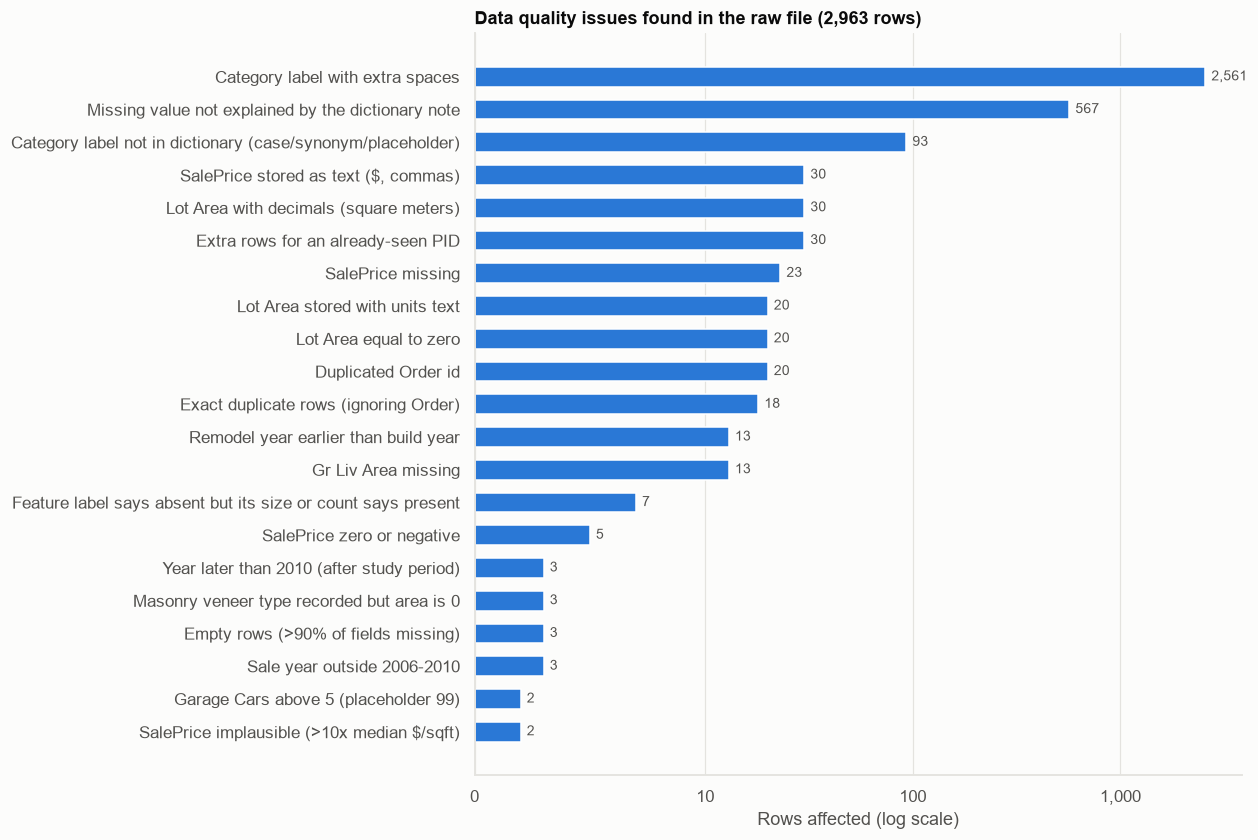

In [10]:
issues = audit_raw[audit_raw > 0].sort_values()
fig, ax = plt.subplots(figsize=(9, 0.36 * len(issues) + 1.2))
ax.barh(issues.index, issues.values, color=COLORS["blue"], height=0.6)
for y, v in enumerate(issues.values):
    ax.annotate(f"{v:,}", (v, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=COLORS["text2"])
ax.set_xscale("symlog", linthresh=10)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("Rows affected (log scale)")
ax.set_title(f"Data quality issues found in the raw file ({len(raw):,} rows)")
ax.grid(axis="y", visible=False)
save_fig(fig, "01_raw_data_quality_issues")
plt.show()

The structural missing values (no pool, no garage, and so on) are **not** counted as issues. The dictionary defines them as "the feature does not exist", and step 9 encodes them explicitly.

<a id="s1-3"></a>

### 1.3 Repair pipeline

Each step works on a copy of the raw data and appends one or more entries to `QUALITY_LOG`: the issue, the rows affected, the action taken and the rationale.

In [11]:
QUALITY_LOG = []


def log(step, issue, rows, action, rationale):
    QUALITY_LOG.append({"step": step, "issue": issue, "rows_affected": int(rows),
                        "action": action, "rationale": rationale})


df = raw.copy()

**Step 1: Empty rows.** A few rows (count printed below) have no PID, no price and almost every field blank. They carry no information.

In [12]:
empty = df.isna().mean(axis=1) > 0.9
log(1, "Empty rows", empty.sum(), "Dropped", "No PID, no price, >90% of fields blank")
df = df.loc[~empty].copy()
print(f"Dropped {empty.sum()} empty rows -> {len(df):,} rows")

Dropped 3 empty rows -> 2,960 rows


**Step 2: Numbers stored as text, and wrong units.**
- `SalePrice` sometimes appears as `"$215,000"`. We strip the symbols; the value itself is correct.
- `Lot Area` sometimes appears as `"5362 sqft"`. We strip the units text.
- Some `Lot Area` values are written with a decimal point (e.g. `713.2`) while every other lot area is a whole number. These values are about ten times smaller than typical lots in their neighborhood, and the same sale sometimes appears a second time with its lot area in square feet. Both checks are printed below. The values were recorded in **square meters**, so we convert them (1 m² = 10.764 sqft).
- `Lot Area = 0` is physically impossible. We set it to missing for the imputer.

In [13]:
SQM_TO_SQFT = 10.7639

# SalePrice: remove "$" and thousands separators
price_txt = df["SalePrice"].astype("string")
has_symbols = price_txt.str.contains(r"[$,]", na=False)
df["SalePrice"] = pd.to_numeric(price_txt.str.replace(r"[$,\s]", "", regex=True), errors="coerce")
log(2, "SalePrice stored as text", has_symbols.sum(), "Removed '$' and ',' and converted to number",
    "Formatting problem only; the amount is valid")

# Lot Area: units text, square meters, zeros
lot_txt = df["Lot Area"].astype("string").str.strip()
has_units = lot_txt.str.contains(r"[A-Za-z]", na=False)
in_sqm = lot_txt.str.contains(r"\.", na=False)
lot = pd.to_numeric(lot_txt.str.replace(r"[^\d.]", "", regex=True), errors="coerce")
lot_before_conversion = lot.copy()
lot = lot.where(~in_sqm, (lot * SQM_TO_SQFT).round())
zero_lot = lot == 0
df["Lot Area"] = lot.mask(zero_lot)
log(2, "Lot Area with units text ('sqft')", has_units.sum(), "Removed text, kept the number",
    "Formatting problem only")
log(2, "Lot Area recorded in square meters", in_sqm.sum(), "Multiplied by 10.764 and rounded",
    "Only decimal values in a whole-number column, ~10x below typical lots, confirmed by a duplicate record")
log(2, "Lot Area equal to zero", zero_lot.sum(), "Set to missing (imputed later in the pipeline)",
    "A lot cannot have zero area")

# Identifier-like numeric codes read as floats -> integers
df["PID"] = df["PID"].astype("Int64")
df["MS SubClass"] = df["MS SubClass"].astype("Int64")

In [14]:
# Evidence for the square-meter conversion: corrupted values vs. their neighborhood's typical lot
nbhd_median_lot = lot.where(~in_sqm).groupby(df["Neighborhood"]).median()
sqm_evidence = pd.DataFrame({
    "PID": df.loc[in_sqm, "PID"],
    "Neighborhood": df.loc[in_sqm, "Neighborhood"],
    "value as recorded": lot_before_conversion[in_sqm],
    "converted to sqft": lot[in_sqm],
    "neighborhood median (sqft)": df.loc[in_sqm, "Neighborhood"].map(nbhd_median_lot),
})
sqm_evidence["recorded / median"] = (sqm_evidence["value as recorded"] / sqm_evidence["neighborhood median (sqft)"]).round(2)
sqm_evidence["converted / median"] = (sqm_evidence["converted to sqft"] / sqm_evidence["neighborhood median (sqft)"]).round(2)
print("Median ratio to the neighborhood's typical lot -> as recorded: "
      f"{sqm_evidence['recorded / median'].median():.2f} | after conversion: {sqm_evidence['converted / median'].median():.2f}")
# The same sale recorded a second time in square feet confirms the unit
raw_lot_txt = raw["Lot Area"].astype("string")
twins = raw.loc[raw["PID"].isin(df.loc[in_sqm, "PID"].astype(float)) & ~raw_lot_txt.str.contains(r"\.", na=False),
                ["PID", "Lot Area"]]
for pid, sqft_text in twins.itertuples(index=False):
    sqm = lot_before_conversion[in_sqm & df["PID"].eq(int(pid))].iloc[0]
    print(f"PID {int(pid)}: {sqm} in one record, {sqft_text} in its duplicate -> "
          f"{sqm} x {SQM_TO_SQFT} = {sqm * SQM_TO_SQFT:,.0f} sqft")
sqm_evidence.head(10)

Median ratio to the neighborhood's typical lot -> as recorded: 0.10 | after conversion: 1.02
PID 535305160: 713.2 in one record, 7677 in its duplicate -> 713.2 x 10.7639 = 7,677 sqft


,PID,Neighborhood,value as recorded,converted to sqft,neighborhood median (sqft),recorded / median,converted / median
27,533350120,Veenker,1512.4,16279.0,13165.0,0.11,1.24
45,907192030,CollgCr,830.1,8935.0,9675.0,0.09,0.92
82,905107240,Sawyer,960.1,10334.0,9402.0,0.1,1.1
246,905300020,Sawyer,947.6,10200.0,9402.0,0.1,1.08
427,527402380,NAmes,868.9,9353.0,9486.0,0.09,0.99
460,528427020,Somerst,893.0,9612.0,8125.0,0.11,1.18
483,923277030,Mitchel,613.1,6599.0,10172.0,0.06,0.65
639,902406020,OldTown,905.8,9750.0,7830.0,0.12,1.25
664,535305160,NAmes,713.2,7677.0,9486.0,0.08,0.81
747,534251320,NWAmes,909.5,9790.0,10944.0,0.08,0.89


**Step 3: Category labels.** Labels are matched to the dictionary codes after removing surrounding spaces and ignoring case (`rl`, `Rl`, ` RL` → `RL`). Two synonyms not in the dictionary are mapped explicitly: `paved` → `Pave` and `yes` → `Y`. Placeholders that mean "unknown" (`NA`, `N/A`, `??`, `unknown`) become missing; step 8 recovers them. The cell **asserts** that nothing else is left unmatched, so no label is dropped silently.

In [15]:
SYNONYMS = {"Street": {"paved": "Pave"}, "Central Air": {"yes": "Y"}}
PLACEHOLDERS = {"na", "n/a", "??", "unknown"}

changes = []
for col in CODED_TEXT_COLS:
    original = df[col].astype("string")
    lookup = {code.lower(): code for code in VALID_CODES[col]} | SYNONYMS.get(col, {})
    key = original.str.strip().str.lower()
    mapped = key.map(lookup)
    unmatched = original.notna() & mapped.isna()
    assert key[unmatched].isin(PLACEHOLDERS).all(), f"{col}: unexpected labels {set(original[unmatched])}"
    changed = original.notna() & (original != mapped).fillna(True)
    if changed.any():
        changes.append(pd.DataFrame({"column": col, "original": original[changed],
                                     "cleaned": mapped[changed].fillna("<missing>")}))
    df[col] = mapped.astype(object).where(mapped.notna(), np.nan)

label_changes = pd.concat(changes)
summary = (label_changes.assign(original=label_changes["original"].map(repr))
           .groupby(["column", "original", "cleaned"]).size().rename("rows").reset_index())
log(3, "Category labels with extra spaces / wrong case / synonyms", label_changes.index.nunique(),
    "Mapped to the dictionary code", "Same category written differently; would otherwise split one category into several")
summary

,column,original,cleaned,rows
0,Central Air,'YES',Y,8
1,Central Air,'Yes',Y,8
2,Central Air,'y',Y,7
3,Central Air,'yes',Y,8
4,MS Zoning,' RL',RL,10
5,MS Zoning,'RL ',RL,10
6,MS Zoning,'Rl',RL,10
7,MS Zoning,'rl',RL,10
8,Neighborhood,'??',<missing>,4
9,Neighborhood,'N/A',<missing>,4


**Step 4: Duplicates.** Once formats are normalized (step 2), more rows become exact copies: `"$330,000"` and `330000` now match. Exact copies are dropped first. Then we look at PIDs that still appear more than once. A PID identifies a property, and a property could legitimately sell twice, so we check whether the repeated rows describe the **same sale** (same month and year).

In [16]:
exact_dup = df.drop(columns="Order").duplicated()
log(4, "Exact duplicate rows", exact_dup.sum(), "Dropped (kept first)", "Same sale recorded twice")
df = df.loc[~exact_dup].copy()

repeated = df[df["PID"].duplicated(keep=False)].sort_values(["PID", "Order"])
same_sale = repeated.groupby("PID")[["Yr Sold", "Mo Sold"]].nunique().max(axis=1).eq(1)
print(f"PIDs still repeated: {repeated['PID'].nunique()} | all repeats share the same sale month: {same_sale.all()}")


def describe_differences(group):
    cols = [c for c in group.columns.drop("Order") if group[c].astype("string").nunique(dropna=False) > 1]
    return "; ".join(f"{c}: " + " vs ".join(group[c].astype("string").fillna("NaN")) for c in cols)


near_dup_table = repeated.groupby("PID").apply(describe_differences, include_groups=False).rename("differences").to_frame()
spread = repeated.groupby("PID").agg(price=("SalePrice", lambda s: (s.max() - s.min()) / s.max()),
                                     lot=("Lot Area", lambda s: s.max() - s.min()))
print(f"Largest difference between copies of the same sale: price {spread['price'].max():.2%}, "
      f"lot area {spread['lot'].max():.0f} sqft")
near_dup_table

PIDs still repeated: 11 | all repeats share the same sale month: True


Largest difference between copies of the same sale: price 0.22%, lot area 1 sqft


,differences
PID,
531367010,Lot Area: 11024.0 vs 11023.0; SalePrice: 18680...
533208020,Garage Yr Blt: 2006.0 vs 1987.0
533213120,Lot Area: 2281.0 vs 2280.0; SalePrice: 173000 ...
533221040,Lot Area: 2999.0 vs 2998.0; SalePrice: 180100 ...
535353060,Lot Area: 9532.0 vs 9533.0; SalePrice: 102800 ...
902205010,Lot Area: 5926.0 vs 5925.0; SalePrice: 45100 v...
903231090,Lot Area: 6240.0 vs 6239.0; SalePrice: 126000 ...
903454100,Lot Area: 6875.0 vs 6876.0; SalePrice: 140900 ...
907202160,Lot Area: 10971.0 vs 10970.0; SalePrice: NaN v...


Every repeated PID is the same sale recorded twice (same sale month). The copies differ only slightly, or by a missing value in one copy: the largest differences are printed above, far too small to change any conclusion. We keep **one record per sale**: the copy with a valid price and the fewest missing values, and on a tie the lowest `Order` (the first recorded).

In [17]:
ranked = (df.assign(_price_ok=df["SalePrice"].gt(0), _n_missing=df.isna().sum(axis=1))
            .sort_values(["PID", "_price_ok", "_n_missing", "Order"], ascending=[True, False, True, True]))
keep = ranked.drop_duplicates("PID").index
n_near = len(df) - len(keep)
log(4, "Same sale recorded twice with small differences (same PID & sale month)", n_near,
    "Kept one record: valid price, fewest missing values, then first Order",
    "Differences <0.1% (about $100 / 1 sqft), so the choice does not affect results")
df = df.loc[df.index.isin(keep)].copy()
assert df["PID"].is_unique and df["Order"].is_unique
print(f"Removed {exact_dup.sum()} exact + {n_near} near duplicates -> {len(df):,} rows; PID and Order are now unique")

Removed 19 exact + 11 near duplicates -> 2,930 rows; PID and Order are now unique


**Step 5: Rebuild missing `Gr Liv Area`.** Above-ground living area is, by definition, 1st floor + 2nd floor + low-quality finished area. The cell below confirms the identity holds in every row where all four values are present, so the missing values can be computed rather than guessed.

In [18]:
components = df["1st Flr SF"] + df["2nd Flr SF"] + df["Low Qual Fin SF"]
mismatch = ((components - df["Gr Liv Area"]).abs() > 1).sum()
rebuild = df["Gr Liv Area"].isna() & components.notna()
df.loc[rebuild, "Gr Liv Area"] = components[rebuild]
log(5, "Gr Liv Area missing", rebuild.sum(), "Computed as 1st + 2nd + low-quality floor area",
    "Exact identity, verified with 0 mismatches in complete rows")
print(f"Rows where Gr Liv Area differs from the sum of its parts: {mismatch} | "
      f"rebuilt {rebuild.sum()} values; still missing: {df['Gr Liv Area'].isna().sum()}")

Rows where Gr Liv Area differs from the sum of its parts: 0 | rebuilt 10 values; still missing: 0


**Step 6: Invalid sale prices (agreed: drop).** The sale price is what the models learn from, so we do not invent it. There are three kinds of invalid price:
- **missing**;
- **zero or negative**: plausible amounts with a flipped sign, but we cannot verify that;
- **implausible**: price per sqft (`price_per_sqft`) above 10× the median. The table below shows these are placeholder-looking values on ordinary houses.

In [19]:
price_per_sqft = df["SalePrice"] / df["Gr Liv Area"]
target_issue = pd.Series(pd.NA, index=df.index, dtype="string")
target_issue[df["SalePrice"].isna()] = "missing"
target_issue[df["SalePrice"] <= 0] = "zero or negative"
target_issue[price_per_sqft > 10 * price_per_sqft.median()] = "implausible (>10x median $/sqft)"
bad_target = target_issue.notna()

display(df.loc[bad_target & target_issue.ne("missing"),
               ["PID", "Neighborhood", "Gr Liv Area", "Overall Qual", "SalePrice"]]
        .assign(price_per_sqft=price_per_sqft.round(0), issue=target_issue))
print(f"Median $/sqft of valid sales: {price_per_sqft[~bad_target].median():.0f}")
for kind, n in target_issue.value_counts().items():
    log(6, f"SalePrice {kind}", n, "Dropped", "The target is never invented; see the agreed decision")
df = df.loc[~bad_target].copy()
print(f"Dropped {bad_target.sum()} rows with an invalid price -> {len(df):,} rows")

,PID,Neighborhood,Gr Liv Area,Overall Qual,SalePrice,price_per_sqft,issue
300,914476520,Mitchel,1560.0,7.0,12500000,8013.0,implausible (>10x median $/sqft)
660,907135180,CollgCr,990.0,4.0,-129000,-130.0,zero or negative
1360,911204100,IDOTRR,952.0,4.0,9999999,10504.0,implausible (>10x median $/sqft)
1629,903427090,OldTown,1666.0,8.0,-62500,-38.0,zero or negative
1710,910200080,IDOTRR,919.0,6.0,-105000,-114.0,zero or negative
2289,527450460,BrDale,1030.0,6.0,-167900,-163.0,zero or negative
2361,908128100,Edwards,1724.0,7.0,-138400,-80.0,zero or negative


Median $/sqft of valid sales: 120
Dropped 26 rows with an invalid price -> 2,904 rows


**Step 7: Impossible years (agreed: rule-based repair using evidence in the same row).**
- **Sale year outside 2006–2010.** The rows dated before 2006 (table below) are new homes built after their recorded sale year, so they would be "sold before being built", and they fall outside the period the dictionary describes. The true year cannot be recovered, so the rows are dropped.
- **Build year after 2010.** Replaced with the garage year when that is plausible, otherwise the remodel year.
- **Garage year after 2010.** Replaced with the house's build year.
- **Build year missing.** Filled with the earlier of the garage year and the remodel year: a house cannot be remodeled before it is built, and it is usually built no later than its garage. The cell tests this rule on houses where all three years are known, and compares it with a median imputer.
- **Remodel year earlier than build year.** The dictionary says *remodel = build year when there was no remodel*, so remodel is set to the build year ("not remodeled").

New homes whose build or remodel year is one year *after* the sale year are **kept**: these are sales of homes still under construction (`Sale Condition = Partial`).

In [20]:
year_cols = ["Year Built", "Year Remod/Add", "Garage Yr Blt", "Yr Sold", "Sale Condition"]

bad_sale_year = ~df["Yr Sold"].between(2006, 2010)
display(df.loc[bad_sale_year, year_cols])
log(7, "Sale year outside 2006-2010", bad_sale_year.sum(), "Dropped",
    "New homes 'sold before being built' and outside the documented period; true year unrecoverable")
df = df.loc[~bad_sale_year].copy()

bad_built = df["Year Built"] > 2010
before = df.loc[bad_built, year_cols].copy()
garage_ok = df["Garage Yr Blt"].between(1800, 2010)
df.loc[bad_built, "Year Built"] = np.where(garage_ok[bad_built], df.loc[bad_built, "Garage Yr Blt"],
                                           df.loc[bad_built, "Year Remod/Add"])
log(7, "Build year after 2010", bad_built.sum(), "Replaced with garage year (or remodel year)",
    "Same-row evidence: garage and remodel years agree with each other")

bad_garage = df["Garage Yr Blt"] > 2010
before = pd.concat([before, df.loc[bad_garage, year_cols]])
df.loc[bad_garage, "Garage Yr Blt"] = df.loc[bad_garage, "Year Built"]
log(7, "Garage year after 2010", bad_garage.sum(), "Replaced with build year",
    "Garage built with the house (new home); 2207 is a typo")

remod_before_built = df["Year Remod/Add"] < df["Year Built"]
df.loc[remod_before_built, "Year Remod/Add"] = df.loc[remod_before_built, "Year Built"]
log(7, "Remodel year earlier than build year", remod_before_built.sum(), "Set remodel year = build year",
    "Dictionary rule: equal to build year when there was no remodel")

# Missing build year: earlier of garage year and remodel year, tested where all three years are known
known_years = df[["Year Built", "Garage Yr Blt", "Year Remod/Add"]].dropna()
rule_estimate = known_years[["Garage Yr Blt", "Year Remod/Add"]].min(axis=1)
rule_exact = (rule_estimate == known_years["Year Built"]).mean()
rule_mae = (rule_estimate - known_years["Year Built"]).abs().mean()
median_mae = (known_years["Year Built"].median() - known_years["Year Built"]).abs().mean()
missing_built = df["Year Built"].isna() & df[["Garage Yr Blt", "Year Remod/Add"]].notna().any(axis=1)
df.loc[missing_built, "Year Built"] = df.loc[missing_built, ["Garage Yr Blt", "Year Remod/Add"]].min(axis=1)
log(7, "Build year missing", missing_built.sum(), "Filled with the earlier of garage year and remodel year",
    "Same-row evidence; tested on houses where all three years are known (see Key results)")

print("Rows with an impossible build/garage year - before and after:")
display(before.join(df[["Year Built", "Garage Yr Blt"]].add_suffix(" (repaired)")))
built_after_sale = df["Year Built"] > df["Yr Sold"]
assert df.loc[built_after_sale, "Sale Condition"].eq("Partial").all()   # all are sales of homes under construction
print(f"Remodel years corrected: {remod_before_built.sum()} | "
      f"homes built after the sale year (kept, all 'Partial' = under construction): {built_after_sale.sum()}")
print(f"Build year filled for {missing_built.sum()} houses. Rule check on {len(known_years):,} houses with all three "
      f"years: exact for {rule_exact:.1%}, mean error {rule_mae:.1f} years (median imputer: {median_mae:.1f} years)")


,Year Built,Year Remod/Add,Garage Yr Blt,Yr Sold,Sale Condition
629,2006.0,2006.0,2006.0,2005.0,Partial
1800,2006.0,2007.0,2006.0,2005.0,Partial
2181,2007.0,2008.0,2008.0,2005.0,Partial


Rows with an impossible build/garage year - before and after:


,Year Built,Year Remod/Add,Garage Yr Blt,Yr Sold,Sale Condition,Year Built (repaired),Garage Yr Blt (repaired)
510,2099.0,2006.0,2006.0,2007.0,Partial,2006.0,2006.0
1697,2050.0,1968.0,1968.0,2007.0,Normal,1968.0,1968.0
2864,2006.0,2007.0,2207.0,2007.0,Partial,2006.0,2006.0


Remodel years corrected: 11 | homes built after the sale year (kept, all 'Partial' = under construction): 3
Build year filled for 10 houses. Rule check on 2,733 houses with all three years: exact for 84.7%, mean error 3.8 years (median imputer: 24.5 years)


**Step 7b: Placeholder garage capacity.** `Garage Cars` (garage size in car capacity) holds the value 99 in a few rows. That is a placeholder, not a garage. The same row's `Garage Area` (garage size in sqft) shows the real size, so we replace 99 with the capacity whose typical (median) garage area is closest to it.

In [21]:
MAX_REAL_CAPACITY = 5   # the largest real garage in the data holds 5 cars; anything above is a placeholder
bad_capacity = df["Garage Cars"] > MAX_REAL_CAPACITY
valid_garage = df["Garage Cars"].between(1, MAX_REAL_CAPACITY) & df["Garage Area"].gt(0)
median_area = df.loc[valid_garage].groupby("Garage Cars")["Garage Area"].median()
repaired = df.loc[bad_capacity, "Garage Area"].apply(lambda area: (median_area - area).abs().idxmin())

print("Median garage area by capacity (sqft):", median_area.round(0).astype(int).to_dict())
display(pd.DataFrame({"Garage Area (sqft)": df.loc[bad_capacity, "Garage Area"],
                      "Garage Cars as recorded": df.loc[bad_capacity, "Garage Cars"],
                      "Garage Cars repaired": repaired}))
df.loc[bad_capacity, "Garage Cars"] = repaired
log("7b", "Garage Cars placeholder (99)", bad_capacity.sum(),
    "Replaced with the capacity whose median Garage Area is closest", "Same-row evidence: the garage's area shows its real size")

Median garage area by capacity (sqft): {1.0: 288, 2.0: 505, 3.0: 806, 4.0: 892, 5.0: 1184}


,Garage Area (sqft),Garage Cars as recorded,Garage Cars repaired
313,264.0,99.0,1.0
2349,336.0,99.0,1.0


**Step 8: Unknown location codes (agreed: nearest parcel ID).** A PID is a tax-map parcel number, so parcels with close numbers sit close together. Before using this, we **test it**: for every property with a known code, we hide the code and predict it from the nearest other PID (leave-one-out validation). A code is recovered this way only if that accuracy is at least `MIN_LOCATION_ACCURACY` (95%).
- `Neighborhood` (physical location within city limits): placeholders such as `NA` or `??`, set to missing in step 3.
- `MS Zoning` (general zoning classification): empty values. The dictionary note does not list this column, so its gaps are data quality issues. Zoning is tied to location, so the same method applies.

In [22]:
def nearest_pid_label(query, ref_pids, ref_labels):
    """Label of the reference parcel whose PID is numerically closest to each query PID."""
    order = np.argsort(ref_pids)
    p, lab = ref_pids[order], ref_labels[order]
    pos = np.searchsorted(p, query)
    left, right = np.clip(pos - 1, 0, len(p) - 1), np.clip(pos, 0, len(p) - 1)
    use_left = np.abs(query - p[left]) <= np.abs(p[right] - query)
    return np.where(use_left, lab[left], lab[right])


def nearest_pid_loo_accuracy(pids, labels):
    """Leave-one-out: predict each known label from its nearest *other* parcel."""
    order = np.argsort(pids)
    p, lab = pids[order], labels[order]
    d_prev, d_next = np.r_[np.inf, np.diff(p)], np.r_[np.diff(p), np.inf]
    prev_lab, next_lab = np.r_[lab[:1], lab[:-1]], np.r_[lab[1:], lab[-1:]]
    return (np.where(d_prev <= d_next, prev_lab, next_lab) == lab).mean()


MIN_LOCATION_ACCURACY = 0.95   # recover a code from the nearest parcel only if leave-one-out accuracy reaches this

known = df["Neighborhood"].notna()
ref_pids = df.loc[known, "PID"].to_numpy(dtype="int64")
ref_labels = df.loc[known, "Neighborhood"].to_numpy(dtype=object)
loo_acc = nearest_pid_loo_accuracy(ref_pids, ref_labels)
majority_acc = df.loc[known, "Neighborhood"].value_counts(normalize=True).iloc[0]
print(f"Leave-one-out accuracy, nearest PID: {loo_acc:.1%}  (baseline 'most common neighborhood': {majority_acc:.1%})")

assert loo_acc >= MIN_LOCATION_ACCURACY, "nearest-parcel recovery not accurate enough for Neighborhood"
unknown = ~known
df.loc[unknown, "Neighborhood"] = nearest_pid_label(df.loc[unknown, "PID"].to_numpy(dtype="int64"), ref_pids, ref_labels)
log(8, "Neighborhood unknown (NA, N/A, ??, unknown)", unknown.sum(), "Assigned the neighborhood of the nearest parcel ID",
    f"PIDs are spatial; validated at {loo_acc:.1%} leave-one-out accuracy")
display(df.loc[unknown, ["PID", "Neighborhood"]].value_counts("Neighborhood").rename("rows recovered").to_frame().T)

# MS Zoning: same method, same test
known_zone = df["MS Zoning"].notna()
zone_pids = df.loc[known_zone, "PID"].to_numpy(dtype="int64")
zone_labels = df.loc[known_zone, "MS Zoning"].to_numpy(dtype=object)
zone_acc = nearest_pid_loo_accuracy(zone_pids, zone_labels)
zone_majority = df.loc[known_zone, "MS Zoning"].value_counts(normalize=True).iloc[0]
print(f"MS Zoning, leave-one-out accuracy, nearest PID: {zone_acc:.1%}  (baseline 'most common zone': {zone_majority:.1%})")
missing_zone = ~known_zone
if zone_acc >= MIN_LOCATION_ACCURACY:
    df.loc[missing_zone, "MS Zoning"] = nearest_pid_label(df.loc[missing_zone, "PID"].to_numpy(dtype="int64"),
                                                          zone_pids, zone_labels)
    log(8, "MS Zoning missing", missing_zone.sum(), "Assigned the zoning of the nearest parcel ID",
        f"Zoning is tied to location; validated at {zone_acc:.1%} leave-one-out accuracy")
else:
    print("Accuracy below the threshold: MS Zoning gaps are left for the imputer")

Leave-one-out accuracy, nearest PID: 98.8%  (baseline 'most common neighborhood': 15.2%)


Neighborhood,NAmes,BrkSide,Sawyer,Edwards,Gilbert,Timber,IDOTRR,Blmngtn,OldTown,SawyerW,Crawfor
rows recovered,4,2,2,2,2,2,1,1,1,1,1


MS Zoning, leave-one-out accuracy, nearest PID: 98.9%  (baseline 'most common zone': 77.8%)


**Step 9: Features that do not exist.** The dictionary's note says that for pools, miscellaneous features, alleys, fences, fireplaces, masonry veneer, garages and basements, an empty value means "the house does not have it". We encode that explicitly as `"Absent"`, and set the matching areas and counts to 0, so these values are never mistaken for real gaps.
- **Garage and basement fields:** the note applies when the whole feature is absent (`Garage Type` or `Bsmt Qual` empty). A missing garage *finish* on a house that *has* a garage is a real gap, left for the imputer. `Garage Yr Blt` stays empty when there is no garage, because no year applies.
- **Masonry veneer:** an empty `Mas Vnr Type` (masonry veneer type) means no veneer, so an empty or zero `Mas Vnr Area` (veneer area, sqft) becomes 0. When the type is empty but the area is above 0, the row contradicts the note: the area shows a veneer exists. The type is set to `"Unknown"` and the area is kept. When a type is recorded but the area is 0, the data does not show which field is wrong, so the row is kept as recorded and reported by the audit.

In [23]:
STRUCTURAL = {
    # group: (rows where the feature is absent, text columns -> "Absent", numeric columns -> 0)
    "basement": (df["Bsmt Qual"].isna() & df["Total Bsmt SF"].fillna(0).eq(0),
                 ["Bsmt Qual", "Bsmt Cond", "Bsmt Exposure", "BsmtFin Type 1", "BsmtFin Type 2"],
                 ["BsmtFin SF 1", "BsmtFin SF 2", "Bsmt Unf SF", "Total Bsmt SF", "Bsmt Full Bath", "Bsmt Half Bath"]),
    "garage": (df["Garage Type"].isna() & df["Garage Area"].fillna(0).eq(0),
               ["Garage Type", "Garage Finish", "Garage Qual", "Garage Cond"], ["Garage Cars", "Garage Area"]),
    "fireplace": (df["Fireplace Qu"].isna() & df["Fireplaces"].eq(0), ["Fireplace Qu"], []),
    "pool": (df["Pool QC"].isna() & df["Pool Area"].eq(0), ["Pool QC"], []),
    "masonry veneer": (df["Mas Vnr Type"].isna() & ~df["Mas Vnr Area"].gt(0), ["Mas Vnr Type"], ["Mas Vnr Area"]),
    "alley": (df["Alley"].isna(), ["Alley"], []),
    "fence": (df["Fence"].isna(), ["Fence"], []),
    "misc feature": (df["Misc Feature"].isna() & df["Misc Val"].eq(0), ["Misc Feature"], []),
}
for group, (absent, text_cols, num_cols) in STRUCTURAL.items():
    for c in text_cols:
        df.loc[absent & df[c].isna(), c] = ABSENT
    for c in num_cols:
        df.loc[absent & df[c].isna(), c] = 0
    log(9, f"No {group} (NaN by design)", absent.sum(), f"Encoded as '{ABSENT}' (areas/counts = 0)",
        "Dictionary: NaN means the feature does not exist")
print({g: int(m.sum()) for g, (m, _, _) in STRUCTURAL.items()})

# Masonry veneer contradictions (dictionary note: an empty type means no veneer)
veneer_type_unknown = df["Mas Vnr Type"].isna() & df["Mas Vnr Area"].gt(0)
df.loc[veneer_type_unknown, "Mas Vnr Type"] = UNKNOWN
log(9, "Masonry veneer: type empty but area above 0", veneer_type_unknown.sum(),
    f"Type set to '{UNKNOWN}', area kept", "Contradicts the dictionary note; the area shows a veneer exists")
type_without_area = df["Mas Vnr Type"].notna() & ~df["Mas Vnr Type"].isin([ABSENT, UNKNOWN]) & df["Mas Vnr Area"].eq(0)
log(9, "Masonry veneer: type recorded but area is 0", type_without_area.sum(), "Kept as recorded",
    "The data does not show which of the two fields is wrong")
print(f"Masonry veneer: type set to '{UNKNOWN}' for {veneer_type_unknown.sum()} rows; "
      f"type recorded with zero area (kept as recorded): {type_without_area.sum()} rows")

{'basement': 79, 'garage': 156, 'fireplace': 1407, 'pool': 2888, 'masonry veneer': 1754, 'alley': 2706, 'fence': 2333, 'misc feature': 2796}
Masonry veneer: type set to 'Unknown' for 7 rows; type recorded with zero area (kept as recorded): 3 rows


<a id="s1-4"></a>

### 1.4 Verification: re-run the audit on the cleaned data

Every check must reach zero after cleaning, except two that remain **by design**: real gaps that are investigated in 1.7 and filled by the imputer inside the model pipeline, and a masonry inconsistency kept as recorded (step 9). The table states the reason next to each.

In [24]:
audit_clean = audit(df)
REMAIN_BY_DESIGN = {
    "Missing value not explained by the dictionary note":
        "real gaps: Lot Frontage (dropped in 1.6) and the gaps investigated in 1.7, filled by the imputer",
    "Masonry veneer type recorded but area is 0": "kept as recorded: the data does not show which field is wrong",
}
must_be_zero = audit_clean.drop(list(REMAIN_BY_DESIGN))
assert must_be_zero.eq(0).all(), must_be_zero[must_be_zero > 0]

audit_compare = pd.DataFrame({"raw": audit_raw, "cleaned": audit_clean})
audit_compare["after cleaning"] = [
    "remains by design: " + REMAIN_BY_DESIGN[check] if check in REMAIN_BY_DESIGN else "none left"
    for check in audit_compare.index]
print(f"Rows: {len(raw):,} raw -> {len(df):,} cleaned ({len(raw) - len(df)} removed). "
      f"All {len(must_be_zero)} checks that must reach zero do; {len(REMAIN_BY_DESIGN)} remain by design.")
unexplained_rows = unexplained_missing(df)
print(f"Sales with a gap the dictionary note does not explain: {unexplained_rows.any(axis=1).sum():,}; "
      f"excluding Lot Frontage (dropped in 1.6): {unexplained_rows.drop(columns='Lot Frontage').any(axis=1).sum():,}")
with pd.option_context("display.max_colwidth", None):
    display(audit_compare)

Rows: 2,963 raw -> 2,901 cleaned (62 removed). All 20 checks that must reach zero do; 2 remain by design.


Sales with a gap the dictionary note does not explain: 524; excluding Lot Frontage (dropped in 1.6): 42


,raw,cleaned,after cleaning
Empty rows (>90% of fields missing),3,0,none left
Exact duplicate rows (ignoring Order),18,0,none left
Extra rows for an already-seen PID,30,0,none left
Duplicated Order id,20,0,none left
"SalePrice stored as text ($, commas)",30,0,none left
SalePrice missing,23,0,none left
SalePrice zero or negative,5,0,none left
SalePrice implausible (>10x median $/sqft),2,0,none left
Lot Area stored with units text,20,0,none left
Lot Area with decimals (square meters),30,0,none left


In [25]:
df.to_csv(PROCESSED_DIR / "clean_all_sales.csv", index=False)
print(f"Saved {len(df):,} valid sales to {(PROCESSED_DIR / 'clean_all_sales.csv').relative_to(ROOT)}")

Saved 2,901 valid sales to data\processed\clean_all_sales.csv

<a id="s1-5"></a>

### 1.5 Analysis sample: which sales the price models learn from

**Agreed decision:** model **Normal** and **Partial** (new home) sales, with an `is_new_home` flag, and exclude houses above 4,000 sqft. Q3 will be re-checked on Normal sales only. The evidence follows.

**a) Non-market sales sell at a discount.** We fit a simple reference model on Normal sales only (log price ~ log living area + overall quality + build year). We then compare each sale type with the price that model expects for a comparable house. The 95% intervals come from a bootstrap of the median gap (using `rng_for`, so they are reproducible).

In [26]:
ref = df.dropna(subset=["Gr Liv Area", "Overall Qual", "Year Built"]).copy()
X_ref = sm.add_constant(np.column_stack([np.log(ref["Gr Liv Area"]), ref["Overall Qual"], ref["Year Built"]]))
y_ref = np.log(ref["SalePrice"].to_numpy())
is_normal = ref["Sale Condition"].eq("Normal").to_numpy()
ref_fit = sm.OLS(y_ref[is_normal], X_ref[is_normal]).fit()
ref["gap_vs_normal_sale"] = y_ref - ref_fit.predict(X_ref)


rows = []
for cond, g in ref.groupby("Sale Condition"):
    _, lo, hi = bootstrap_ci(np.median, g["gap_vs_normal_sale"], task=f"1.5 sale condition bootstrap: {cond}")
    rows.append({"Sale Condition": cond, "n": len(g), "median price": g["SalePrice"].median(),
                 "median $/sqft": (g["SalePrice"] / g["Gr Liv Area"]).median(),
                 "% vs comparable Normal sale": 100 * np.expm1(g["gap_vs_normal_sale"].median()),
                 "95% CI low": 100 * np.expm1(lo), "95% CI high": 100 * np.expm1(hi)})
cond_effect = pd.DataFrame(rows).set_index("Sale Condition").sort_values("% vs comparable Normal sale")
print(f"Reference model on Normal sales: R² = {ref_fit.rsquared:.3f}")
cond_effect.round(1)

Reference model on Normal sales: R² = 0.815


,n,median price,median $/sqft,% vs comparable Normal sale,95% CI low,95% CI high
Sale Condition,,,,,,
AdjLand,12,110000.0,83.8,-11.1,-26.6,-1.6
Abnorml,189,129000.0,100.7,-8.2,-11.2,-5.0
Family,44,144900.0,109.9,-4.6,-11.1,2.1
Normal,2392,158750.0,119.3,0.5,-0.1,1.2
Partial,241,250000.0,149.0,4.2,1.2,6.9
Alloca,23,150909.0,86.6,4.7,-21.8,7.3


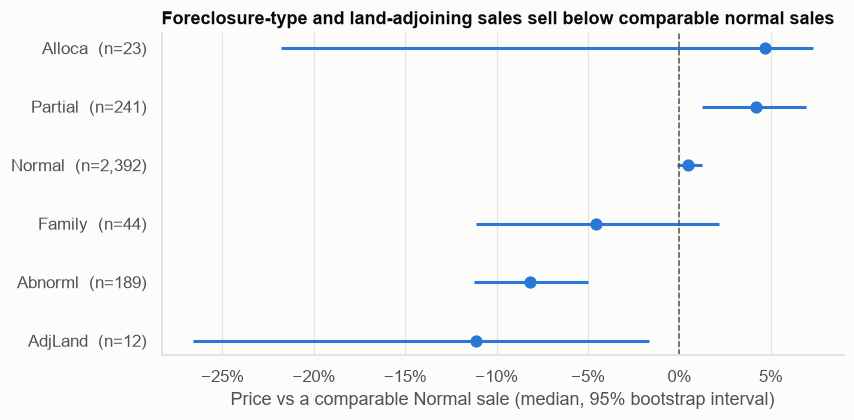

In [27]:
t = cond_effect.sort_values("% vs comparable Normal sale")
fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(t))
ax.errorbar(t["% vs comparable Normal sale"], y,
            xerr=[t["% vs comparable Normal sale"] - t["95% CI low"], t["95% CI high"] - t["% vs comparable Normal sale"]],
            fmt="o", color=COLORS["blue"], ecolor=COLORS["blue"], elinewidth=2, markersize=7, capsize=0)
ax.axvline(0, color=COLORS["text2"], lw=1, ls="--")
ax.set_yticks(y, labels=[f"{c}  (n={n:,})" for c, n in zip(t.index, t["n"])])
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel("Price vs a comparable Normal sale (median, 95% bootstrap interval)")
ax.set_title("Foreclosure-type and land-adjoining sales sell below comparable normal sales")
ax.grid(axis="y", visible=False)
save_fig(fig, "01_sale_condition_discount")
plt.show()

**b) Houses above 4,000 sqft.** These are rare (counts printed below). The dataset's author recommends removing all houses above 4,000 sqft. The table compares each market sale above that size with a reference model fitted *without* them. The new homes in Edwards sold for a fraction of what their size and quality imply, which points to incomplete transactions. The NoRidge sale is a genuine luxury home with no comparable houses to learn from.

In [28]:
market = df["Sale Condition"].isin(["Normal", "Partial"])
large = df["Gr Liv Area"] > 4000
fit_data = ref.loc[ref.index.isin(df.index[market & ~large])]
X_fit = sm.add_constant(np.column_stack([np.log(fit_data["Gr Liv Area"]), fit_data["Overall Qual"], fit_data["Year Built"]]))
fit_no_large = sm.OLS(np.log(fit_data["SalePrice"]), X_fit).fit()

big = df.loc[large & market]
X_big = sm.add_constant(np.column_stack([np.log(big["Gr Liv Area"]), big["Overall Qual"], big["Year Built"]]), has_constant="add")
outlier_table = big[["Neighborhood", "Gr Liv Area", "Overall Qual", "Sale Condition", "SalePrice"]].assign(
    expected_price=np.exp(fit_no_large.predict(X_big)).round(-3))
outlier_table["actual vs expected"] = (outlier_table["SalePrice"] / outlier_table["expected_price"] - 1).map("{:+.0%}".format)
print(f"Houses above 4,000 sqft: {large.sum()} among valid sales, {(large & market).sum()} of them market sales (listed below) | "
      f"houses above 3,000 sqft: {(df['Gr Liv Area'] > 3000).sum()}")
outlier_table

Houses above 4,000 sqft: 5 among valid sales, 4 of them market sales (listed below) | houses above 3,000 sqft: 25


,Neighborhood,Gr Liv Area,Overall Qual,Sale Condition,SalePrice,expected_price,actual vs expected
499,Edwards,5642.0,10.0,Partial,160000,621000.0,-74%
618,Edwards,4676.0,10.0,Partial,184750,562000.0,-67%
2276,Edwards,5095.0,10.0,Partial,183850,589000.0,-69%
2319,NoRidge,4316.0,10.0,Normal,755000,518000.0,+46%


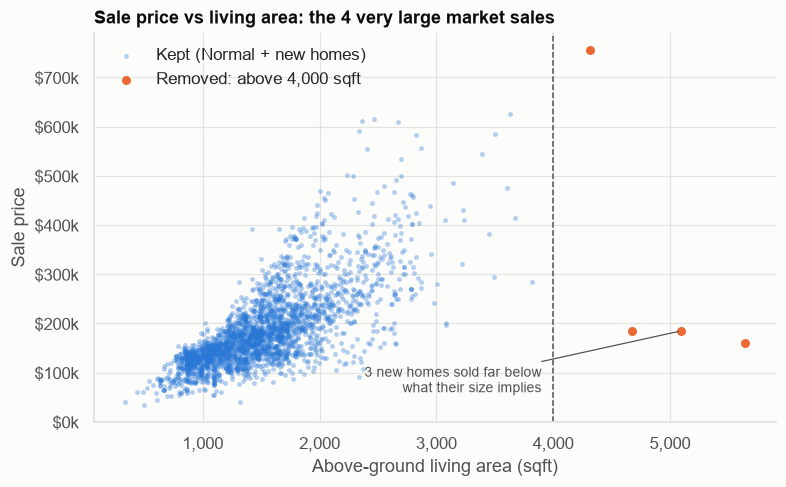

In [29]:
plot_df = df.loc[market]
fig, ax = plt.subplots(figsize=(8, 4.6))
kept = plot_df["Gr Liv Area"] <= 4000
ax.scatter(plot_df.loc[kept, "Gr Liv Area"], plot_df.loc[kept, "SalePrice"], s=10, alpha=0.35,
           color=COLORS["blue"], linewidths=0, label="Kept (Normal + new homes)")
ax.scatter(plot_df.loc[~kept, "Gr Liv Area"], plot_df.loc[~kept, "SalePrice"], s=55,
           color=COLORS["orange"], edgecolor=COLORS["surface"], linewidth=1.5, label="Removed: above 4,000 sqft")
ax.axvline(4000, color=COLORS["text2"], lw=1, ls="--")
ax.annotate("3 new homes sold far below\nwhat their size implies", xy=(5100, 185000), xytext=(3900, 60000),
            fontsize=9, color=COLORS["text2"], ha="right", arrowprops=dict(arrowstyle="-", color=COLORS["text2"], lw=0.8))
ax.yaxis.set_major_formatter(USD)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlabel("Above-ground living area (sqft)")
ax.set_ylabel("Sale price")
ax.set_title("Sale price vs living area: the 4 very large market sales")
ax.legend(frameon=False, loc="upper left")
save_fig(fig, "01_large_house_outliers")
plt.show()

In [30]:
sample = df.loc[market & ~large].copy()
# New variable (see "Variables used in this section"): flags new construction so its premium is modeled separately
sample["is_new_home"] = sample["Sale Condition"].eq("Partial").astype(int)
log("1.5", "Non-market sales (Abnorml, Family, Alloca, AdjLand)", (~market).sum(), "Excluded from the analysis sample",
    "Not open-market prices (e.g. foreclosure-type sales ~8% below comparable Normal sales)")
log("1.5", "Houses above 4,000 sqft", (market & large).sum(), "Excluded from the analysis sample",
    "3 incomplete-looking new-home sales, 1 luxury home with no comparables; model valid up to 4,000 sqft")
print(f"Analysis sample: {len(sample):,} sales ({sample['is_new_home'].sum()} new homes, "
      f"{(1 - sample['is_new_home']).sum():,} normal resales)")

Analysis sample: 2,629 sales (238 new homes, 2,391 normal resales)


<a id="s1-6"></a>

### 1.6 Lot Frontage: dropped (team decision)

`Lot Frontage` is the linear feet of street connected to the property. The team decided to drop it after reviewing the evidence below and the cross-validation check in Section 2.4 (model error with and without it).
- **What we give up:** the analysis says nothing about street frontage itself. The lot is still described by `Lot Area` (lot size) and `Lot Config` (inside, corner, cul-de-sac...).
- **Alternative considered:** fill it with the neighborhood median plus a "was missing" flag.

Evidence on the analysis sample:

In [31]:
lf_data = sample.dropna(subset=["Lot Frontage", "Lot Area", "Year Built"])
X_lf = sm.add_constant(np.column_stack([np.log(lf_data["Gr Liv Area"]), lf_data["Overall Qual"],
                                        lf_data["Year Built"], np.log(lf_data["Lot Area"])]))
resid_lf = sm.OLS(np.log(lf_data["SalePrice"]), X_lf).fit().resid
lf_evidence = pd.Series({
    "share missing": sample["Lot Frontage"].isna().mean(),
    "Spearman: Lot Frontage vs price": sample["Lot Frontage"].corr(sample["SalePrice"], method="spearman"),
    "Spearman: Lot Area vs price": sample["Lot Area"].corr(sample["SalePrice"], method="spearman"),
    "Spearman: Lot Frontage vs Lot Area": sample["Lot Frontage"].corr(sample["Lot Area"], method="spearman"),
    "Spearman: Lot Frontage vs price left unexplained by size, quality, age and lot area":
        lf_data["Lot Frontage"].corr(resid_lf, method="spearman"),
}).round(3)
lf_evidence.to_frame("value")

,value
share missing,0.172
Spearman: Lot Frontage vs price,0.416
Spearman: Lot Area vs price,0.438
Spearman: Lot Frontage vs Lot Area,0.671
"Spearman: Lot Frontage vs price left unexplained by size, quality, age and lot area",0.025


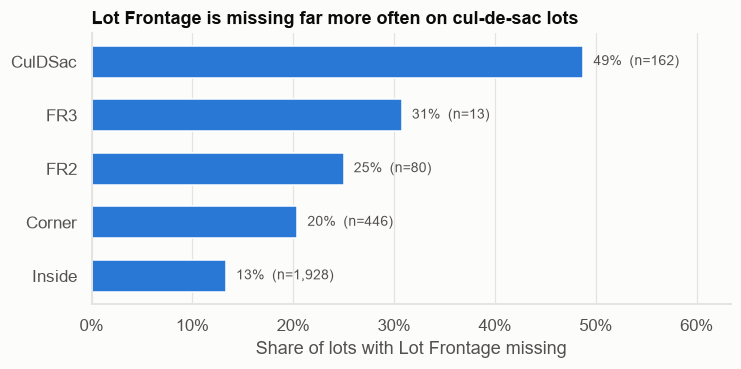

In [32]:
miss = sample.groupby("Lot Config")["Lot Frontage"].agg(share_missing=lambda s: s.isna().mean(), n="size").sort_values("share_missing")
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.barh(miss.index, miss["share_missing"], color=COLORS["blue"], height=0.6)
for y, (v, n) in enumerate(zip(miss["share_missing"], miss["n"])):
    ax.text(v + 0.01, y, f"{v:.0%}  (n={n:,})", va="center", fontsize=9, color=COLORS["text2"])
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax.set_xlim(0, miss["share_missing"].max() * 1.3)
ax.set_xlabel("Share of lots with Lot Frontage missing")
ax.set_title("Lot Frontage is missing far more often on cul-de-sac lots")
ax.grid(axis="y", visible=False)
plt.show()

**Reading.** Lot Frontage tracks Lot Area closely, and once size, quality, age and lot area are accounted for, almost no relationship with price remains. Its gaps are **not random**: they are concentrated on cul-de-sac lots, where frontage is curved and hard to measure. Imputing it would invent values exactly where the measurement makes least sense.

In [33]:
DROP_LOT_FRONTAGE = True   # Team decision (Section 1 review); cross-validation check in Section 2.4

if DROP_LOT_FRONTAGE:
    lf_missing = sample["Lot Frontage"].isna().mean()
    sample = sample.drop(columns="Lot Frontage")
    log("1.6", f"Lot Frontage ({lf_missing:.0%} missing, not at random)", len(sample),
        "Column dropped (team decision; cross-validation check in Section 2.4)",
        "No price information beyond Lot Area; gaps concentrated on cul-de-sac lots")

<a id="s1-7"></a>

### 1.7 Remaining missing values: investigation

The dictionary's note says that empty values outside the listed "feature absent" cases *may indicate a data quality issue worth investigating*. The table classifies every gap left in the analysis sample: how many the note explains, how many are data quality issues, what was found, and how each is handled. These gaps are filled inside the model pipeline (Section 3), which is fitted on training data only, so the test data never influences the filling.

In [34]:
# Investigation of each remaining gap (the assert forces every new gap to be documented here)
INVESTIGATION = {
    "Garage Yr Blt": ("Houses without a garage: no year applies (dictionary note). The rest: a house with a garage "
                      "but no year recorded", "Column dropped in Section 2 (largely duplicates Year Built)"),
    "Lot Area": ("Recorded as 0 (set to missing in step 2) or not recorded. No same-row evidence of lot size, and "
                 "lot sizes vary widely within a neighborhood", "Imputed in the model pipeline"),
    "Bsmt Exposure": ("House has a basement but its exposure was not recorded", "Imputed in the model pipeline"),
    "BsmtFin Type 2": ("House has a basement but its second finish type was not recorded", "Imputed in the model pipeline"),
    "Electrical": ("Electrical system not recorded; no same-row evidence", "Imputed in the model pipeline"),
    "Garage Finish": ("House has a garage but its finish was not recorded", "Imputed in the model pipeline"),
    "Garage Qual": ("House has a garage but its quality was not recorded", "Imputed in the model pipeline"),
    "Garage Cond": ("House has a garage but its condition was not recorded", "Imputed in the model pipeline"),
}
gaps = sample.isna().sum()
gaps = gaps[gaps > 0].sort_values(ascending=False)
assert set(gaps.index) <= set(INVESTIGATION), f"Undocumented gaps: {set(gaps.index) - set(INVESTIGATION)}"
not_explained = unexplained_missing(sample).sum()
investigation = pd.DataFrame({
    "missing": gaps,
    "% of sample": (100 * gaps / len(sample)).round(2),
    "explained by dictionary note": gaps - not_explained[gaps.index],
    "data quality issue": not_explained[gaps.index],
    "finding": [INVESTIGATION[c][0] for c in gaps.index],
    "handling": [INVESTIGATION[c][1] for c in gaps.index],
})
sample.to_csv(PROCESSED_DIR / "analysis_sample.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(investigation)

,missing,% of sample,explained by dictionary note,data quality issue,finding,handling
Garage Yr Blt,120,4.56,119,1,Houses without a garage: no year applies (dictionary note). The rest: a house with a garage but no year recorded,Column dropped in Section 2 (largely duplicates Year Built)
Lot Area,30,1.14,0,30,"Recorded as 0 (set to missing in step 2) or not recorded. No same-row evidence of lot size, and lot sizes vary widely within a neighborhood",Imputed in the model pipeline
Bsmt Exposure,3,0.11,0,3,House has a basement but its exposure was not recorded,Imputed in the model pipeline
BsmtFin Type 2,1,0.04,0,1,House has a basement but its second finish type was not recorded,Imputed in the model pipeline
Electrical,1,0.04,0,1,Electrical system not recorded; no same-row evidence,Imputed in the model pipeline
Garage Finish,1,0.04,0,1,House has a garage but its finish was not recorded,Imputed in the model pipeline
Garage Qual,1,0.04,0,1,House has a garage but its quality was not recorded,Imputed in the model pipeline
Garage Cond,1,0.04,0,1,House has a garage but its condition was not recorded,Imputed in the model pipeline


<a id="s1-8"></a>

### 1.8 Key results and data quality log

The summary below is printed by code, so it always matches the current data. The full log lists every issue, the rows affected, the action taken and the reason.

In [35]:
quality_log = pd.DataFrame(QUALITY_LOG)
quality_log.to_csv(PROCESSED_DIR / "data_quality_log.csv", index=False)

abnormal = cond_effect.loc["Abnorml"]
print("Key results - Section 1")
print(f"  Rows: {len(raw):,} in the raw file -> {len(df):,} valid sales after cleaning ({len(raw) - len(df)} removed) "
      f"-> {len(sample):,} in the analysis sample ({sample['is_new_home'].sum()} new homes)")
print(f"  Audit checks with problems: {int((audit_raw > 0).sum())} of {len(audit_raw)} in the raw file -> "
      f"{int((must_be_zero > 0).sum())} after cleaning, plus {len(REMAIN_BY_DESIGN)} that remain by design (1.4)")
print(f"  Gaps left for the model pipeline: {int(investigation['data quality issue'].sum())} values that are data "
      f"quality issues and {int(investigation['explained by dictionary note'].sum())} explained by the dictionary note (1.7)")
print(f"  Neighborhood from nearest parcel ID: {loo_acc:.1%} leave-one-out accuracy "
      f"(most common neighborhood: {majority_acc:.1%})")
print(f"  Zoning from nearest parcel ID: {zone_acc:.1%} leave-one-out accuracy (most common zone: {zone_majority:.1%})")
print(f"  Build year from earlier of garage/remodel year: exact for {rule_exact:.1%} of checkable houses "
      f"(mean error {rule_mae:.1f} years vs {median_mae:.1f} for a median imputer)")
print(f"  Foreclosure-type sales vs comparable Normal sales: {abnormal['% vs comparable Normal sale']:+.1f}% "
      f"(95% interval {abnormal['95% CI low']:+.1f}% to {abnormal['95% CI high']:+.1f}%)")
print(f"  Saved to {PROCESSED_DIR.relative_to(ROOT)}: clean_all_sales.csv, analysis_sample.csv, data_quality_log.csv")
quality_log

Key results - Section 1
  Rows: 2,963 in the raw file -> 2,901 valid sales after cleaning (62 removed) -> 2,629 in the analysis sample (238 new homes)
  Audit checks with problems: 21 of 22 in the raw file -> 0 after cleaning, plus 2 that remain by design (1.4)
  Gaps left for the model pipeline: 39 values that are data quality issues and 119 explained by the dictionary note (1.7)
  Neighborhood from nearest parcel ID: 98.8% leave-one-out accuracy (most common neighborhood: 15.2%)
  Zoning from nearest parcel ID: 98.9% leave-one-out accuracy (most common zone: 77.8%)
  Build year from earlier of garage/remodel year: exact for 84.7% of checkable houses (mean error 3.8 years vs 24.5 for a median imputer)
  Foreclosure-type sales vs comparable Normal sales: -8.2% (95% interval -11.2% to -5.0%)
  Saved to data\processed: clean_all_sales.csv, analysis_sample.csv, data_quality_log.csv


,step,issue,rows_affected,action,rationale
0,1,Empty rows,3,Dropped,"No PID, no price, >90% of fields blank"
1,2,SalePrice stored as text,30,"Removed '$' and ',' and converted to number",Formatting problem only; the amount is valid
2,2,Lot Area with units text ('sqft'),20,"Removed text, kept the number",Formatting problem only
3,2,Lot Area recorded in square meters,30,Multiplied by 10.764 and rounded,"Only decimal values in a whole-number column, ..."
4,2,Lot Area equal to zero,20,Set to missing (imputed later in the pipeline),A lot cannot have zero area
5,3,Category labels with extra spaces / wrong case...,2571,Mapped to the dictionary code,Same category written differently; would other...
6,4,Exact duplicate rows,19,Dropped (kept first),Same sale recorded twice
7,4,Same sale recorded twice with small difference...,11,"Kept one record: valid price, fewest missing v...","Differences <0.1% (about $100 / 1 sqft), so th..."
8,5,Gr Liv Area missing,10,Computed as 1st + 2nd + low-quality floor area,"Exact identity, verified with 0 mismatches in ..."
9,6,SalePrice missing,19,Dropped,The target is never invented; see the agreed d...


<a id="s1-decisions"></a>

### Decisions and rationale — Section 1

| Decision | Alternatives considered | Evidence and reason |
|---|---|---|
| Never invent a sale price: rows with a missing, zero or negative, or implausible price are removed (step 6). | Flip the sign of negative prices; keep these rows for the segmentation only | The target is what the models learn from, and these values cannot be verified. The rows removed are listed in the quality log. |
| Repair a value only with evidence from the same row: number formats, square meters, category labels, impossible years, living area from its parts, garage capacity from garage area. | Mark corrupted values as missing and impute them; drop the affected rows | Uses information already in the data instead of a generic guess. Every repair is listed in the quality log. |
| A missing build year is filled with the earlier of the garage year and the remodel year (step 7). | Median imputer inside the model pipeline | Tested on houses where all three years are known: far more accurate than the median (Key results). |
| `Garage Cars = 99` is replaced with the capacity whose median area is closest to the garage's area (step 7b). | Choose only between 1 and 2 cars; treat it as missing | Works for any capacity. A median imputer would give these small garages 2 cars. |
| Unknown neighborhoods and missing zoning codes take the code of the nearest parcel ID, but only if leave-one-out accuracy is at least 95% (step 8). | A separate "Unknown" category; the imputer; drop the rows | Both pass the threshold (Key results). Location is a main price driver, so losing it would hurt. |
| Duplicates: one record per sale (valid price, fewest gaps, then first recorded) (step 4). | Average the copies | The copies differ by amounts too small to matter (step 4). |
| Missing values follow the dictionary's note. An empty value means "feature absent" only for the listed features, and for garage and basement fields only when the whole feature is absent. Those are encoded as "Absent" (step 9). Every other gap is a data quality issue: counted by the audit and investigated in 1.7. | Treat all gaps alike and impute them | The client's dictionary defines what an empty value means, and asks for other gaps to be investigated. |
| Masonry veneer: an empty type means no veneer (area 0). An empty type with an area above 0 becomes "Unknown" and keeps its area. A recorded type with a zero area is kept as recorded and reported (step 9). | Follow the note literally (all empty types become "Absent"); leave everything to the imputer | Follows the note where the row agrees with it, and keeps the same-row evidence (the area) where it does not. |
| Analysis sample: Normal sales and new homes (`is_new_home` flag), with living area up to 4,000 sqft (1.5). | Normal sales only; all sales with a sale-type flag | Non-market sales sell below comparable Normal sales (1.5). The very large houses are incomplete or one-off sales. The models are valid only up to 4,000 sqft. |
| `Lot Frontage` is dropped (1.6). | Neighborhood median plus a "was missing" flag | It adds no price information beyond Lot Area (1.6) and does not improve cross-validated error (2.4). Its gaps are concentrated on cul-de-sac lots. |

<a id="s2"></a>

## 2. Exploratory data analysis and feature engineering

> **In brief.** *Question:* what do the data show before modeling, and which variables should the models use? *Answer:* prices are skewed, so the models predict log price. Compared like for like, prices were flat over 2006–2010, and they are strongly tied to location and age. After removing constant and duplicated variables, the models keep a set that is as accurate as using every variable. *Numbers:* [Key results](#s2-9). *Decisions:* [end of section](#s2-decisions).

This section prepares every modeling decision that Sections 3–6 rely on:
- **2.1** New variables computed from the data, and why.
- **2.2** The train/test split. It comes first: **from here on, every figure and statistic uses the training set only**, so no decision is influenced by the sales used to measure the models in Section 3.
- **2.3–2.5** Exploratory figures. Each one opens with the question it answers and the decision it informs.
- **2.6** Shared modeling tools (encodings, preprocessing, cross-validation).
- **2.7** Variable selection in five stages, ending in a glossary that gives every candidate variable's meaning and outcome.
- **2.8** The cross-validation check on `Lot Frontage` (Section 1.6).

Figures on *which* characteristics move price, and on raw vs like-for-like price gaps for owner-modifiable features, answer Q2 and Q3 directly and are shown in those sections.

<a id="s2-1"></a>

### 2.1 New variables computed from the data

Some quantities that buyers and brokers reason with are not columns in the data: the age of the house at sale, the total floor area including the basement, the number of bathrooms counted together. We compute them from each row's own values only, so no information passes between rows and nothing leaks from the test set. The table below gives each new variable's meaning, formula and the reason it is computed. Some of them carry the same information as an original column. The selection in 2.7 decides which version the models use.

`MS SubClass` (type of dwelling) is stored as a number, but it is a code: 60 is not "three times" 20. It is converted to text, so the models treat it as a category.

In [36]:
def engineer_features(df_in):
    """Row-level new variables (each uses only the row's own values, so there is no leakage)."""
    d = df_in.copy()
    d["house_age"] = d["Yr Sold"] - d["Year Built"]
    d["years_since_remod"] = (d["Yr Sold"] - d["Year Remod/Add"]).clip(lower=0)
    d["is_remodeled"] = (d["Year Remod/Add"] > d["Year Built"]).astype(int)
    d["total_sf"] = d["Gr Liv Area"] + d["Total Bsmt SF"]
    d["log_lot_area"] = np.log1p(d["Lot Area"])
    d["log_gr_liv_area"] = np.log1p(d["Gr Liv Area"])
    d["log_total_sf"] = np.log1p(d["total_sf"])
    d["total_baths"] = d["Full Bath"] + 0.5 * d["Half Bath"] + d["Bsmt Full Bath"] + 0.5 * d["Bsmt Half Bath"]
    d["porch_sf"] = d["Wood Deck SF"] + d["Open Porch SF"] + d["Enclosed Porch"] + d["3Ssn Porch"] + d["Screen Porch"]
    d["MS SubClass"] = d["MS SubClass"].astype(str)   # a dwelling-type code, not a quantity
    return d


data_fe = engineer_features(sample)

In [37]:
define_variable("house_age", "Age of the house when it was sold (years)", "Yr Sold - Year Built",
                "Buyers react to a house's age at the time of sale, not to its construction year as such.")
define_variable("years_since_remod", "Years since the last remodel or addition, or since construction if there was none",
                "Yr Sold - Year Remod/Add (minimum 0)",
                "How recently the house was updated; needed for the remodeling question (Q3).")
define_variable("is_remodeled", "1 if the house was remodeled or extended after it was built, otherwise 0",
                "Year Remod/Add > Year Built",
                "Separates updated houses from original-condition ones (Q3). Caveat: about half of the houses built "
                "before 1950 record a remodel year of exactly 1950, the earliest year in the records, so for them the "
                "flag may not reflect a real remodel (team decision: documented, not changed; see 2.5).")
define_variable("total_sf", "Total floor area: above-ground living area plus basement (sqft)", "Gr Liv Area + Total Bsmt SF",
                "Buyers compare houses on total usable space; Gr Liv Area alone leaves out the basement.")
define_variable("log_lot_area", "Lot size on a logarithmic scale", "log(1 + Lot Area)",
                "Very large lots would otherwise dominate a linear model; on a log scale, effects read as % per %.")
define_variable("log_gr_liv_area", "Above-ground living area on a logarithmic scale", "log(1 + Gr Liv Area)",
                "Same information as Gr Liv Area on a compressed scale (see log_lot_area).")
define_variable("log_total_sf", "Total floor area on a logarithmic scale", "log(1 + total_sf)",
                "Same information as total_sf on a compressed scale (see log_lot_area).")
define_variable("total_baths", "All bathrooms, half baths counted as one half",
                "Full Bath + 0.5 Half Bath + Bsmt Full Bath + 0.5 Bsmt Half Bath",
                "Buyers count bathrooms as one feature; four separate counts split that information.")
define_variable("porch_sf", "All outdoor living area: deck and porches (sqft)",
                "Wood Deck SF + Open Porch SF + Enclosed Porch + 3Ssn Porch + Screen Porch",
                "Each porch type alone is rare; together they describe outdoor living space.")


variables_table({
    "SalePrice": "Target (2.3); price per sqft (2.5)",
    "Yr Sold": "Time trend (2.4); house age",
    "Mo Sold": "Seasonality (2.4)",
    "Neighborhood": "Location effect (2.5)",
    "Gr Liv Area": "Size control in the like-for-like index (2.4); price per sqft (2.5)",
    "Overall Qual": "Quality control in the like-for-like index (2.4)",
    "Year Built": "Age control in the like-for-like index (2.4); house age",
    "Year Remod/Add": "Remodel status (2.5)",
    "MS SubClass": "Converted from number to category",
    "is_new_home": "New-home control in the like-for-like index (2.4)",
    "price_per_sqft": "Location and age figures (2.5)",
    "house_age": None, "years_since_remod": None, "is_remodeled": None, "total_sf": None,
    "log_lot_area": None, "log_gr_liv_area": None, "log_total_sf": None, "total_baths": None, "porch_sf": None,
})

,Source,Meaning,Codes / formula,Role in this section
Variable,,,,
SalePrice,Data dictionary,Sale price of the property in US dollars (numeric).,numeric,Target (2.3); price per sqft (2.5)
Yr Sold,Data dictionary,Year of sale (integer).,numeric,Time trend (2.4); house age
Mo Sold,Data dictionary,Month of sale (integer 1 to 12).,numeric,Seasonality (2.4)
Neighborhood,Data dictionary,Physical location within city limits.,Blmngtn; Blueste; BrDale; BrkSide; ClearCr; CollgCr; Crawfor; Edwards; ... (28 codes),Location effect (2.5)
Gr Liv Area,Data dictionary,Above-grade (ground) living area square feet (numeric).,numeric,Size control in the like-for-like index (2.4); price per sqft (2.5)
Overall Qual,Data dictionary,Rates the overall material and finish of the house.; Integer from 1 (Very Poor) to 10 (Very Excellent).,numeric,Quality control in the like-for-like index (2.4)
Year Built,Data dictionary,Original construction year.,numeric,Age control in the like-for-like index (2.4); house age
Year Remod/Add,Data dictionary,Remodel year (same as Year Built if no remodel or addition).,numeric,Remodel status (2.5)
MS SubClass,Data dictionary,Type of dwelling involved in the sale (integer code),120 = 1-STORY PUD 1946 & NEWER; 150 = 1-1/2 STORY PUD ALL AGES; 160 = 2-STORY PUD 1946 & NEWER; 180 = PUD MULTILEVEL - INCL SPLIT LEV/FOYER; 190 = 2 FAMILY CONVERSION ALL STYLES AND AGES; 20 = 1-STORY 1946 & NEWER ALL STYLES; 30 = 1-STORY 1945 & OLDER; 40 = 1-STORY W/FINISHED ATTIC ALL AGES; ... (16 codes),Converted from number to category


<a id="s2-2"></a>

### 2.2 Train/test split (before any analysis)

We hold out 20% of the analysis sample as a **test set**, used only to measure the final models in Section 3. The split is **stratified by price decile**, so both sets cover cheap and expensive homes in the same proportions. Everything below this cell uses `train_df` only.

In [38]:
from sklearn.model_selection import StratifiedShuffleSplit

TEST_SHARE = 0.20
price_deciles = pd.qcut(data_fe["SalePrice"], q=10, labels=False)
splitter = StratifiedShuffleSplit(n_splits=1, test_size=TEST_SHARE, random_state=SEED)
train_idx, test_idx = next(splitter.split(data_fe, price_deciles))
train_df = data_fe.iloc[train_idx].copy()
test_df = data_fe.iloc[test_idx].copy()

pd.DataFrame({
    "sales": [len(train_df), len(test_df)],
    "median price": [train_df["SalePrice"].median(), test_df["SalePrice"].median()],
    "share of new homes": [train_df["is_new_home"].mean().round(3), test_df["is_new_home"].mean().round(3)],
}, index=["train", "test"])

,sales,median price,share of new homes
train,2103,165000.0,0.095
test,526,165000.0,0.072


<a id="s2-3"></a>

### 2.3 Target: model the price or its logarithm?

**Question.** Is the sale price spread evenly enough to model directly? If a few very expensive homes form a long right tail, they dominate a model's squared errors, and a $20,000 error counts the same on a $90,000 house as on a $450,000 one.

**What to look at.** The skewness printed above each panel (0 = symmetric) and the length of the right tail.

**Decision it informs.** The target of every model.

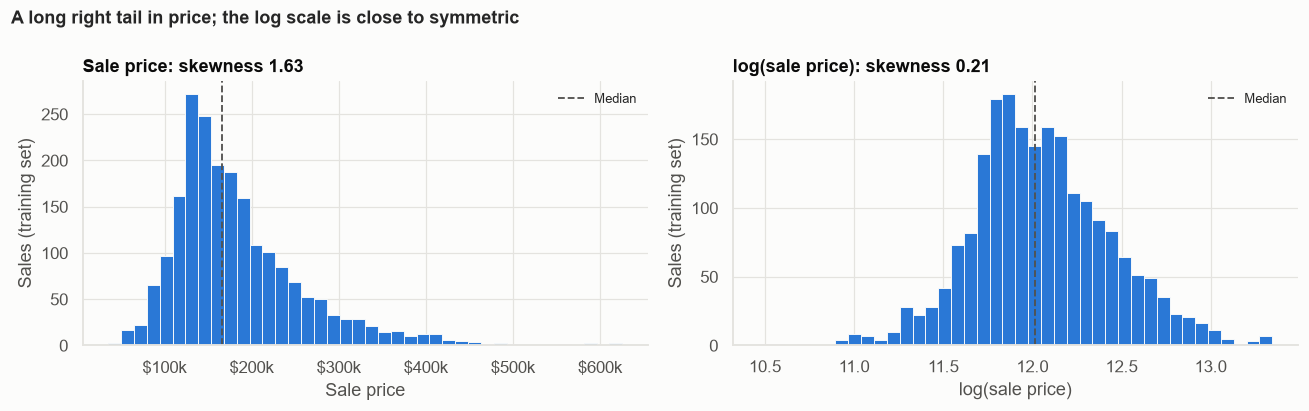

Skewness: price 1.63 -> log(price) 0.21
Price percentiles (training set): 5% $93,540 | 25% $132,000 | median $165,000 | 75% $216,250 | 95% $338,888


In [39]:
log_price_train = np.log(train_df["SalePrice"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, values, label, fmt in [(axes[0], train_df["SalePrice"], "Sale price", USD),
                               (axes[1], log_price_train, "log(sale price)", None)]:
    ax.hist(values, bins=40, color=COLORS["blue"], edgecolor=COLORS["surface"], linewidth=0.6)
    ax.axvline(values.median(), color=COLORS["text2"], lw=1.2, ls="--", label="Median")
    ax.set_title(f"{label}: skewness {values.skew():.2f}")
    ax.set_xlabel(label)
    ax.set_ylabel("Sales (training set)")
    ax.legend(frameon=False, fontsize=8.5)
    if fmt is not None:
        ax.xaxis.set_major_formatter(fmt)
fig.suptitle("A long right tail in price; the log scale is close to symmetric", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
plt.tight_layout()
save_fig(fig, "02_target_distribution")
plt.show()

q = train_df["SalePrice"].quantile([0.05, 0.25, 0.5, 0.75, 0.95])
print(f"Skewness: price {train_df['SalePrice'].skew():.2f} -> log(price) {log_price_train.skew():.2f}")
print(f"Price percentiles (training set): 5% ${q[0.05]:,.0f} | 25% ${q[0.25]:,.0f} | median ${q[0.5]:,.0f} | "
      f"75% ${q[0.75]:,.0f} | 95% ${q[0.95]:,.0f}")

**Reading.** Price is strongly right-skewed. On the log scale the distribution is close to symmetric (skewness printed above).

**Decision.** All models predict **log(price)**, and predictions are converted back to dollars. Errors then behave as percentages: a 10% error means the same on a starter home as on an executive home. That matches how brokers judge a valuation ("within 10%").

<a id="s2-4"></a>

### 2.4 Time: did prices move between 2006 and 2010?

**Question.** The data spans the 2008 financial crisis. If prices drifted, a model trained on older sales would misprice recent ones, and it would need time variables.

**Why two measures.** The raw median price per period can mislead, because the *mix* of homes sold changes over time: a year with more new or larger homes shows a higher median even if prices did not move. So we also compute a **like-for-like index**: for each sale, the gap between its price and the price expected for a comparable house (same size, overall quality, build year and new/resale status), from a reference regression fitted on the training set. A positive gap means "sold above a comparable house". We also check **seasonality**: whether volume and like-for-like prices vary by month of the year.

**Decision it informs.** Whether the models need time variables (sale year, month), and whether the time-based validation in Section 3 is needed.

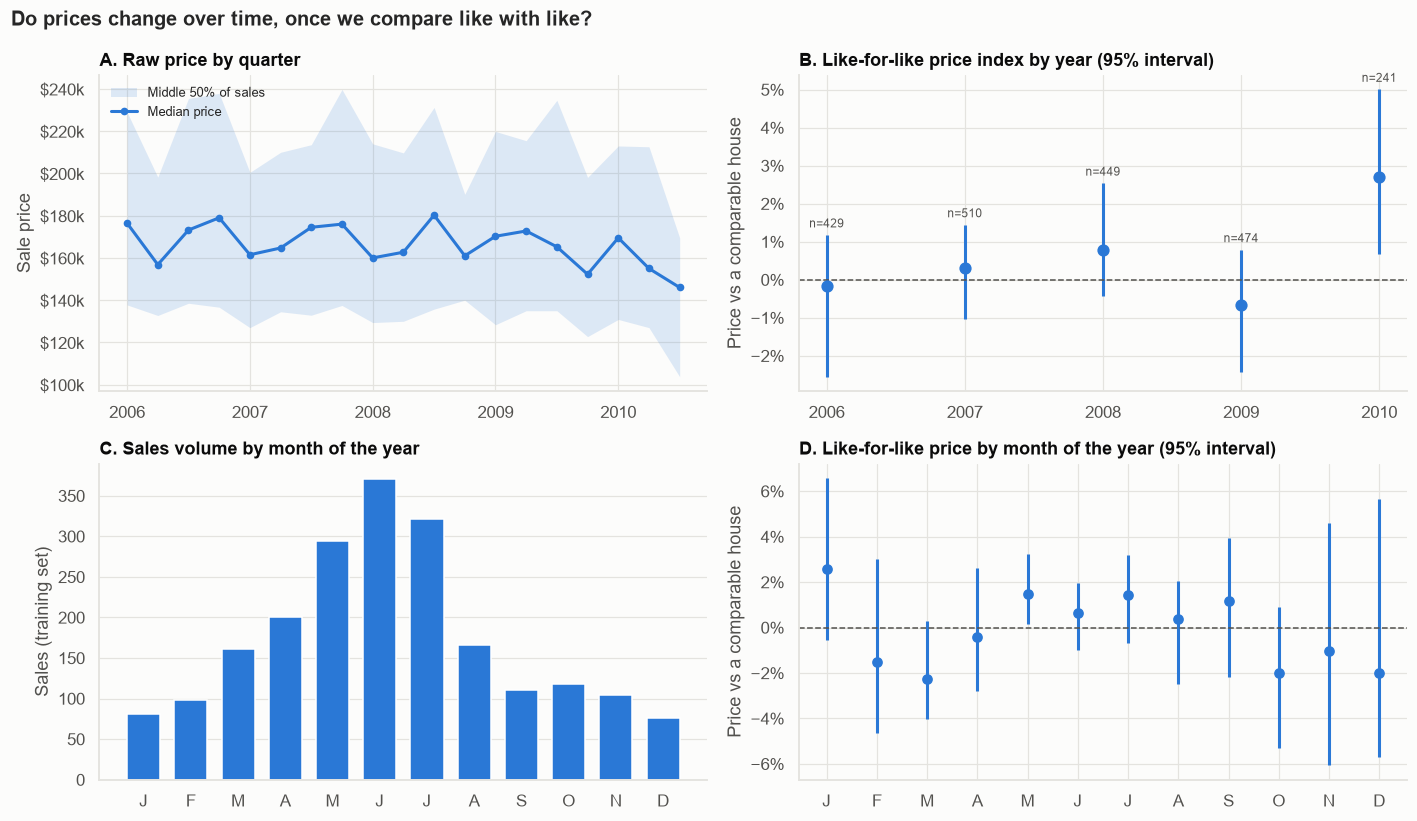

Reference regression for the like-for-like index: R² = 0.833 on 2,103 training sales


,sales,first month,last month,median price,like-for-like %,95% CI low,95% CI high
year,,,,,,,
2006,429,1,12,166000.0,-0.2,-2.6,1.2
2007,510,1,12,167150.0,0.3,-1.0,1.4
2008,449,1,12,165000.0,0.8,-0.4,2.5
2009,474,1,12,164750.0,-0.7,-2.4,0.8
2010,241,1,7,159900.0,2.7,0.7,5.0


In [40]:
define_variable(
    "like_for_like_gap",
    "Difference between a sale's log price and the log price expected for a comparable house sold in the same period "
    "(exp(gap) - 1 = % above or below)",
    "log(SalePrice) - reference prediction; reference: log(SalePrice) ~ log(Gr Liv Area) + Overall Qual + Year Built "
    "+ is_new_home, fitted on the training set",
    "Section 2.4: compares prices across periods without the effect of the changing mix of homes sold. Not a model input.")

time_df = train_df[["SalePrice", "Yr Sold", "Mo Sold", "Gr Liv Area", "Overall Qual", "Year Built", "is_new_home"]].copy()
X_time = sm.add_constant(np.column_stack([np.log(time_df["Gr Liv Area"]), time_df["Overall Qual"],
                                          time_df["Year Built"], time_df["is_new_home"]]))
time_ref = sm.OLS(np.log(time_df["SalePrice"]), X_time).fit()
time_df["like_for_like_gap"] = np.log(time_df["SalePrice"]) - time_ref.predict(X_time)
time_df["quarter"] = time_df["Yr Sold"].astype(int).astype(str) + "-Q" + ((time_df["Mo Sold"] - 1) // 3 + 1).astype(int).astype(str)


by_quarter = time_df.groupby("quarter")["SalePrice"].agg(
    median="median", q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75), n="size")
by_year = pd.DataFrame([(int(y), len(g), int(g["Mo Sold"].min()), int(g["Mo Sold"].max()), g["SalePrice"].median(),
                         *(100 * np.expm1(bootstrap_ci(np.median, g["like_for_like_gap"], task=f"2.4 like-for-like year {y}"))))
                        for y, g in time_df.groupby("Yr Sold")],
                       columns=["year", "sales", "first month", "last month", "median price",
                                "like-for-like %", "95% CI low", "95% CI high"]).set_index("year")
by_month = pd.DataFrame([(int(m), len(g), *(100 * np.expm1(bootstrap_ci(np.median, g["like_for_like_gap"], task=f"2.4 like-for-like month {m}"))))
                         for m, g in time_df.groupby("Mo Sold")],
                        columns=["month", "sales", "like-for-like %", "95% CI low", "95% CI high"]).set_index("month")

fig, axes = plt.subplots(2, 2, figsize=(13, 7.6))
# A: raw median price by quarter
ax = axes[0, 0]
x = np.arange(len(by_quarter))
ax.fill_between(x, by_quarter["q25"], by_quarter["q75"], color=COLORS["blue"], alpha=0.15, linewidth=0,
                label="Middle 50% of sales")
ax.plot(x, by_quarter["median"], marker="o", ms=4, lw=2, color=COLORS["blue"], label="Median price")
year_starts = [i for i, qtr in enumerate(by_quarter.index) if qtr.endswith("Q1")]
ax.set_xticks(year_starts, labels=[by_quarter.index[i][:4] for i in year_starts])
ax.yaxis.set_major_formatter(USD)
ax.set_ylabel("Sale price")
ax.set_title("A. Raw price by quarter")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
# B: like-for-like index by year
ax = axes[0, 1]
ax.errorbar(by_year.index, by_year["like-for-like %"],
            yerr=[by_year["like-for-like %"] - by_year["95% CI low"], by_year["95% CI high"] - by_year["like-for-like %"]],
            fmt="o", ms=7, color=COLORS["blue"], elinewidth=2, capsize=0)
ax.axhline(0, color=COLORS["text2"], lw=1, ls="--")
for yr, row in by_year.iterrows():
    ax.annotate(f"n={int(row['sales'])}", (yr, row["95% CI high"]), xytext=(0, 5), textcoords="offset points",
                ha="center", fontsize=8, color=COLORS["text2"])
ax.set_xticks(by_year.index)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylabel("Price vs a comparable house")
ax.set_title("B. Like-for-like price index by year (95% interval)")
# C: sales volume by calendar month
ax = axes[1, 0]
ax.bar(by_month.index, by_month["sales"], color=COLORS["blue"], width=0.7)
ax.set_xticks(range(1, 13), labels=["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set_ylabel("Sales (training set)")
ax.set_title("C. Sales volume by month of the year")
ax.grid(axis="x", visible=False)
# D: like-for-like gap by calendar month
ax = axes[1, 1]
ax.errorbar(by_month.index, by_month["like-for-like %"],
            yerr=[by_month["like-for-like %"] - by_month["95% CI low"], by_month["95% CI high"] - by_month["like-for-like %"]],
            fmt="o", ms=6, color=COLORS["blue"], elinewidth=2, capsize=0)
ax.axhline(0, color=COLORS["text2"], lw=1, ls="--")
ax.set_xticks(range(1, 13), labels=["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylabel("Price vs a comparable house")
ax.set_title("D. Like-for-like price by month of the year (95% interval)")
fig.suptitle("Do prices change over time, once we compare like with like?", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
save_fig(fig, "02_time_and_seasonality")
plt.show()

print(f"Reference regression for the like-for-like index: R² = {time_ref.rsquared:.3f} on {len(time_df):,} training sales")
by_year.round(1)

**Reading.**
- **No market-wide price trend.** Raw medians (panel A) wander from quarter to quarter, but part of that is the changing mix of homes sold. Compared like for like (panel B), the years 2006–2009 sit close together, with intervals that include zero, so the 2008 crisis left no visible mark on prices in this market.
- **2010 is the exception, and it runs the opposite way to its raw median.** Its like-for-like index is slightly above the other years, while its raw median is the lowest (table above). The raw 2010 dip therefore comes from the mix of homes sold, not from lower prices. Also, 2010 only covers January to July.
- **Volume is seasonal, prices are not.** Sales concentrate in late spring and early summer (panel C), but like-for-like prices show no consistent pattern by month, and most monthly intervals include zero (panel D).

**Decision.** The price level does not need to be modeled over time. Sale year and month remain candidate variables, and the selection in 2.7 decides on evidence whether they help. Because 2010 differs slightly, the time-based validation in Section 3 (train on 2006–2009, test on 2010) is kept as a robustness check.

<a id="s2-5"></a>

### 2.5 Location and age

**Questions.**
1. *Does location matter beyond size?* Bigger houses cost more everywhere, so comparing neighborhood prices directly mixes location with house size. **Price per square foot** (`price_per_sqft`) removes most of the size effect, so differences between neighborhoods point to location.
2. *How does age relate to value, and do remodeled houses hold their value better?* This bears on the remodeling question in Q3.

**What to look at.** In the first figure, how far apart the neighborhoods' medians sit compared with the spread inside each neighborhood (gray dots: fewer than 10 training sales, so less reliable). In the second, the two median lines: whether price per sqft falls with age, and whether remodeled houses sit above never-remodeled ones of the same age.

**Decisions they inform.** Neighborhood must be a model input (and a candidate driver for Q2). Age and remodel variables are candidates for Q2 and Q3.

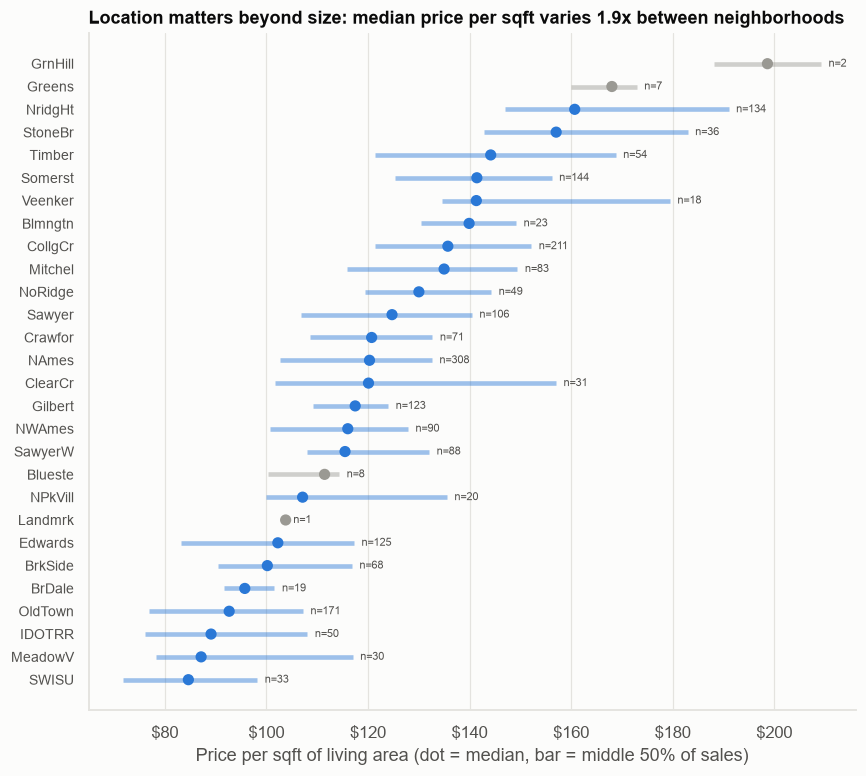

Neighborhoods with at least 10 training sales: 24 of 28 | highest / lowest median price per sqft: 1.90x | Kruskal-Wallis test of equal distributions: p = 4.3e-168


In [41]:
from scipy.stats import kruskal

MIN_SALES_RELIABLE = 10
ppsf_train = train_df["SalePrice"] / train_df["Gr Liv Area"]
nbhd = ppsf_train.groupby(train_df["Neighborhood"]).agg(
    median="median", q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75), n="size").sort_values("median")
reliable = nbhd["n"] >= MIN_SALES_RELIABLE
spread_ratio = nbhd.loc[reliable, "median"].max() / nbhd.loc[reliable, "median"].min()
kw_p = kruskal(*[g.to_numpy() for _, g in ppsf_train.groupby(train_df["Neighborhood"]) if len(g) >= MIN_SALES_RELIABLE]).pvalue

fig, ax = plt.subplots(figsize=(9, 8))
y = np.arange(len(nbhd))
colors = np.where(reliable, COLORS["blue"], COLORS["gray"])
ax.hlines(y, nbhd["q25"], nbhd["q75"], colors=colors, lw=3, alpha=0.45)
ax.scatter(nbhd["median"], y, c=colors, s=40, zorder=3)
for yi, (name, row) in zip(y, nbhd.iterrows()):
    ax.annotate(f"n={int(row['n'])}", (row["q75"], yi), xytext=(5, 0), textcoords="offset points",
                va="center", fontsize=7.5, color=COLORS["text2"])
ax.set_yticks(y, labels=nbhd.index, fontsize=9)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))
ax.set_xlabel("Price per sqft of living area (dot = median, bar = middle 50% of sales)")
ax.set_title(f"Location matters beyond size: median price per sqft varies {spread_ratio:.1f}x between neighborhoods")
ax.grid(axis="y", visible=False)
save_fig(fig, "02_neighborhood_price_per_sqft")
plt.show()
print(f"Neighborhoods with at least {MIN_SALES_RELIABLE} training sales: {reliable.sum()} of {len(nbhd)} | "
      f"highest / lowest median price per sqft: {spread_ratio:.2f}x | "
      f"Kruskal-Wallis test of equal distributions: p = {kw_p:.1e}")

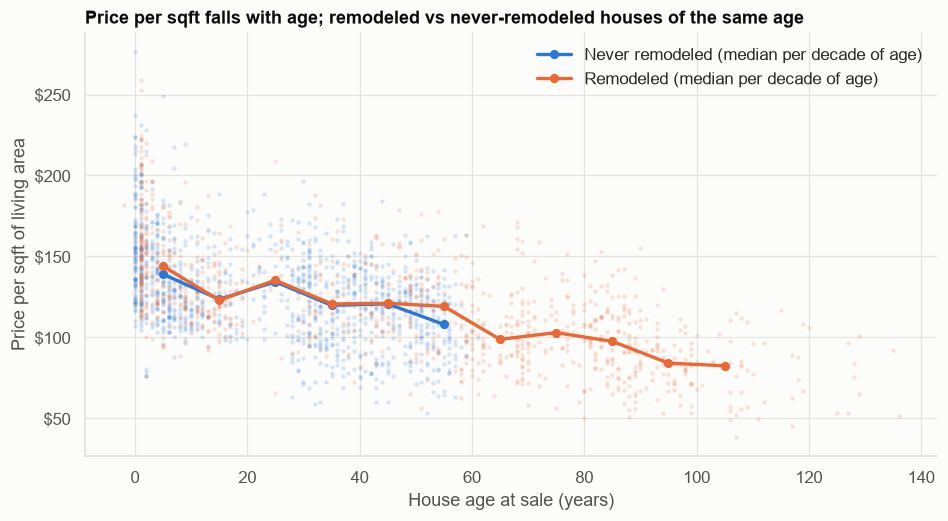

Spearman correlation, house age vs price per sqft: -0.59
Houses built before 1950 with a remodel year of exactly 1950 (earliest year in the records): 203 of 418 (49%); they count as 'remodeled' in this figure


group,Never remodeled,Remodeled
age_bin,,
5.0,139.0,144.0
15.0,124.0,123.0
25.0,134.0,135.0
35.0,120.0,121.0
45.0,121.0,121.0
55.0,108.0,119.0
65.0,<NA>,99.0
75.0,<NA>,103.0
85.0,<NA>,98.0


In [42]:
AGE_BIN_YEARS = 10
MIN_SALES_PER_BIN = 15
age_df = pd.DataFrame({"age": train_df["house_age"], "ppsf": ppsf_train,
                       "group": np.where(train_df["is_remodeled"].eq(1), "Remodeled", "Never remodeled")})
age_df["age_bin"] = (age_df["age"] // AGE_BIN_YEARS) * AGE_BIN_YEARS + AGE_BIN_YEARS / 2
binned = (age_df.groupby(["group", "age_bin"])["ppsf"].agg(median="median", n="size").reset_index()
          .query("n >= @MIN_SALES_PER_BIN"))

fig, ax = plt.subplots(figsize=(10, 5))
group_colors = {"Never remodeled": COLORS["blue"], "Remodeled": COLORS["orange"]}
for group, color in group_colors.items():
    pts = age_df[age_df["group"] == group]
    ax.scatter(pts["age"], pts["ppsf"], s=8, alpha=0.18, color=color, linewidths=0)
    line = binned[binned["group"] == group]
    ax.plot(line["age_bin"], line["median"], marker="o", ms=5, lw=2.2, color=color, label=f"{group} (median per decade of age)")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))
ax.set_xlabel("House age at sale (years)")
ax.set_ylabel("Price per sqft of living area")
ax.set_title("Price per sqft falls with age; remodeled vs never-remodeled houses of the same age")
ax.legend(frameon=False, loc="upper right")
save_fig(fig, "02_age_and_remodel")
plt.show()

age_rho = age_df["age"].corr(age_df["ppsf"], method="spearman")
built_pre1950 = train_df["Year Built"] < 1950
floor_1950 = built_pre1950 & train_df["Year Remod/Add"].eq(1950)
print(f"Spearman correlation, house age vs price per sqft: {age_rho:.2f}")
print(f"Houses built before 1950 with a remodel year of exactly 1950 (earliest year in the records): "
      f"{floor_1950.sum()} of {built_pre1950.sum()} ({floor_1950.sum() / built_pre1950.sum():.0%}); "
      f"they count as 'remodeled' in this figure")
binned.pivot(index="age_bin", columns="group", values="median").round(0)

**Reading.**
- **Location matters beyond size.** Median price per sqft differs strongly between neighborhoods, and the test above rejects that all neighborhoods share one distribution (ratio and test printed above the age figure).
- **Price per sqft falls with age** (correlation printed above).
- **Remodeled vs never remodeled.** Remodeled and never-remodeled houses of the same age sell at very similar prices per sqft in most age bands (table above). Recorded on its own, a remodel is not associated with a higher price per sqft. Two cautions:
  1. Among the oldest houses almost every house counts as "remodeled". About half of the houses built before 1950 record a remodel year of exactly 1950, the earliest year in the records (printed above), so the flag partly reflects how years were recorded. Team decision: documented, not changed.
  2. This is a raw comparison. What a remodel adds once quality and condition are taken into account is the subject of Q3.

**Decisions.** `Neighborhood` is a model input and a candidate location driver for Q2. Age and remodel variables stay candidates; the selection in 2.7 decides which version (e.g. `Year Built` or `house_age`) the models use.

<a id="s2-6"></a>

### 2.6 Shared modeling tools

These tools are used by the variable selection below and by every model in Sections 3–6. Every step that learns from data (imputation, encoding, scaling) sits inside a scikit-learn `Pipeline`, so in cross-validation it is fitted on the training folds only.

- **Ordered categories** (`ORDINAL_MAP`) are encoded as ranks in the order listed, e.g. `Po < Fa < TA < Gd < Ex` for quality scales (Poor, Fair, Typical, Good, Excellent). The orderings are kept as defined (team decision). Per the dictionary, `Bsmt Qual` rates the **height** of the basement, not its finish quality.
- **Unordered categories** are one-hot encoded. Categories with fewer than 5 training sales are grouped together, so rare labels cannot create unstable columns.
- **Missing values** are filled with the median (numbers) or the most frequent value (categories), learned from the training folds.
- **Linear models (Ridge, ElasticNet) see skewed amounts on a log scale.** Numeric variables whose training-set skewness is above 1 (`SKEWED_COLS`: lot area, porch and basement areas...) go through log(1 + x). The model then reads effects as "% of price per % of area", and a few very large values cannot dominate. Each variable keeps its dictionary name. Tree models are unaffected by this transformation and use the original values.
- **Numbers are standardized** for the linear models, so the penalty treats them equally. Tree models use them unscaled.
- **Back to dollars:** a model of log(price) predicts the *typical* (median) price: comparable homes sell above and below it equally often. We report that typical price (team decision). Section 3.3 shows that converting it to an *average* price with Duan's smearing factor would change almost nothing.

In [43]:
# Ordered categories, in increasing order (codes from the data dictionary)
ORDINAL_MAP = {
    "Lot Shape": ["IR3", "IR2", "IR1", "Reg"],
    "Land Slope": ["Sev", "Mod", "Gtl"],
    "Exter Qual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "Exter Cond": ["Po", "Fa", "TA", "Gd", "Ex"],
    "Bsmt Qual": ["Absent", "Po", "Fa", "TA", "Gd", "Ex"],
    "Bsmt Cond": ["Absent", "Po", "Fa", "TA", "Gd", "Ex"],
    "Bsmt Exposure": ["Absent", "No", "Mn", "Av", "Gd"],
    "BsmtFin Type 1": ["Absent", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "BsmtFin Type 2": ["Absent", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "Heating QC": ["Po", "Fa", "TA", "Gd", "Ex"],
    "Kitchen Qual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "Functional": ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
    "Fireplace Qu": ["Absent", "Po", "Fa", "TA", "Gd", "Ex"],
    "Garage Finish": ["Absent", "Unf", "RFn", "Fin"],
    "Garage Qual": ["Absent", "Po", "Fa", "TA", "Gd", "Ex"],
    "Garage Cond": ["Absent", "Po", "Fa", "TA", "Gd", "Ex"],
    "Paved Drive": ["N", "P", "Y"],
    "Pool QC": ["Absent", "Po", "Fa", "TA", "Gd", "Ex"],
    "Fence": ["Absent", "MnWw", "GdWo", "MnPrv", "GdPrv"],
    "Electrical": ["FuseP", "FuseF", "FuseA", "Mix", "SBrkr"],
}


# Skewed, non-negative amounts (decided on the training set): log scale for the linear models
SKEWED_COLS = [c for c in train_df.columns
               if c not in ("Order", "PID", "SalePrice") and pd.api.types.is_numeric_dtype(train_df[c])
               and train_df[c].min() >= 0 and train_df[c].skew() > 1]


kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
y_train_log = np.log(train_df["SalePrice"].to_numpy())
p_train_usd = train_df["SalePrice"].to_numpy()
y_test_log = np.log(test_df["SalePrice"].to_numpy())
p_test_usd = test_df["SalePrice"].to_numpy()

LGB_PARAMS = dict(
    n_estimators=500, learning_rate=0.03, num_leaves=24, colsample_bytree=0.7,
    subsample=0.8, subsample_freq=1, min_child_samples=15, reg_alpha=0.1, reg_lambda=1.0,
    random_state=SEED, verbose=-1, n_jobs=-1,
    deterministic=True, force_row_wise=True,  # bit-for-bit repeatable results regardless of thread count
)
RIDGE_ALPHA = 15.0

<a id="s2-7"></a>

### 2.7 Variable selection

**Why select variables at all?** About 85 candidate variables are available. Many are nearly constant, and several pairs carry the same information. Feeding all of them to the models has three costs:
- brokers would need to supply dozens of inputs to value a home;
- importance gets split between near-duplicates, which blurs the answer to Q2;
- the models become harder to explain.

The selection runs in five stages, **on the training set only**:

| Stage | Question | Rule |
|---|---|---|
| 1. Information | Does the variable vary at all? | Drop it if one value covers more than 95% of sales (`NEAR_CONSTANT`). |
| 2. Relevance | How strongly is it linked to price on its own? | Rank by \|Spearman correlation\| with log price for numbers and ordered categories, and by the correlation ratio η for unordered categories. Both run from 0 (no link) to 1. |
| 3. Redundancy | Does another variable already carry the same information? | For pairs above 0.90 (`REDUNDANT`; Spearman for numbers, Cramér's V for categories), keep the one more linked to price. On a tie, keep the original dictionary variable over a computed one. The threshold targets true duplicates (raw vs log copies, build year vs age). Related but different measures, such as living area vs total area, are both kept (team decision). |
| 4. How many | How many variables does a model need, and is it better to use all of them? | Add variables in order of relevance and measure the 5-fold cross-validated error. Compare every size with the **full candidate set**. Keep the smallest set whose error is within one standard error of the best option, the full set included (**one-standard-error rule**). If no smaller set qualifies, use all candidates. This is done for Ridge and for LightGBM, and the larger requirement wins. |
| 5. Business override | Does Q2 or Q3 need a variable that was dropped? | Re-add any variable that an improvement scenario in Q3 changes, unless a kept duplicate already represents it. |

The stage-5 list is provisional. The split between owner-modifiable and structural variables is decided when Sections 4 and 5 are reviewed.

In [44]:
from scipy.stats import chi2_contingency

NEAR_CONSTANT = 0.95
REDUNDANT = 0.90
EXCLUDE = {"Order": "row identifier", "PID": "parcel identifier", "SalePrice": "target",
           "Sale Condition": "defines the sample; its information is in is_new_home"}
CANDIDATES = [c for c in train_df.columns if c not in EXCLUDE]
log_price = np.log(train_df["SalePrice"])
outcome = {}   # variable -> (stage, outcome text)


def kind_of(col):
    if col in ORDINAL_MAP:
        return "ordered category"
    return "number" if pd.api.types.is_numeric_dtype(train_df[col]) else "category"


def as_ranked_number(col):
    """Numbers as they are; ordered categories as their rank in ORDINAL_MAP."""
    if col in ORDINAL_MAP:
        return train_df[col].map({level: i for i, level in enumerate(ORDINAL_MAP[col])})
    return train_df[col]


def link_to_price(col):
    """Strength of a variable's own link to log price, from 0 to 1."""
    if kind_of(col) == "category":
        groups = train_df[col].fillna("missing")
        group_mean = log_price.groupby(groups).transform("mean")
        return float(np.sqrt(((group_mean - log_price.mean()) ** 2).sum() / ((log_price - log_price.mean()) ** 2).sum()))
    return float(abs(as_ranked_number(col).corr(log_price, method="spearman")))


# Stage 1: information
top_share = {c: train_df[c].value_counts(normalize=True, dropna=False).iloc[0] for c in CANDIDATES}
for c, share in top_share.items():
    if share > NEAR_CONSTANT:
        outcome[c] = (1, f"Dropped: nearly constant ({share:.0%} of sales share one value)")
after_stage1 = [c for c in CANDIDATES if c not in outcome]

# Stage 2: relevance
LINK = {c: link_to_price(c) for c in CANDIDATES}
print(f"Stage 1: {len(CANDIDATES)} candidates -> {len(after_stage1)} after dropping nearly constant variables")
print("Stage 2: strongest links to log price:",
      ", ".join(f"{c} {LINK[c]:.2f}" for c in sorted(after_stage1, key=LINK.get, reverse=True)[:8]))

Stage 1: 87 candidates -> 74 after dropping nearly constant variables
Stage 2: strongest links to log price: total_sf 0.82, log_total_sf 0.82, Overall Qual 0.82, Neighborhood 0.77, Gr Liv Area 0.73, log_gr_liv_area 0.73, total_baths 0.71, Garage Cars 0.71


In [45]:
# Stage 3: redundancy
def cramers_v(a, b):
    table = pd.crosstab(a.fillna("missing"), b.fillna("missing"))
    if min(table.shape) < 2:
        return 0.0
    chi2 = chi2_contingency(table, correction=False)[0]
    return float(np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1))))


def simplicity(col):
    """Tie-break: prefer original dictionary variables, then computed ones, then log versions."""
    return 0 if col in VAR_DESCRIPTIONS else (2 if col.startswith("log_") else 1)


ranked_cols = [c for c in after_stage1 if kind_of(c) != "category"]
category_cols = [c for c in after_stage1 if kind_of(c) == "category"]
spearman = pd.DataFrame({c: as_ranked_number(c) for c in ranked_cols}).corr(method="spearman").abs()
pairs = [(spearman.loc[a, b], a, b, "Spearman") for i, a in enumerate(ranked_cols) for b in ranked_cols[i + 1:]]
pairs += [(cramers_v(train_df[a], train_df[b]), a, b, "Cramér's V")
          for i, a in enumerate(category_cols) for b in category_cols[i + 1:]]
redundant_pairs = sorted([p for p in pairs if p[0] > REDUNDANT], reverse=True)

alive = set(after_stage1)
for strength, a, b, measure in redundant_pairs:
    if a in alive and b in alive:
        keep, drop = sorted([a, b], key=lambda c: (-round(LINK[c], 6), simplicity(c)))
        alive.discard(drop)
        outcome[drop] = (3, f"Dropped: same information as {keep} ({measure} {strength:.2f}); weaker link to price")
after_stage3 = [c for c in after_stage1 if c in alive]
print(f"Stage 3: {len(redundant_pairs)} redundant pairs -> {len(after_stage1) - len(after_stage3)} variables dropped, "
      f"{len(after_stage3)} remain")
pd.DataFrame(redundant_pairs, columns=["similarity", "variable A", "variable B", "measure"]).round(3)

Stage 3: 8 redundant pairs -> 7 variables dropped, 67 remain


,similarity,variable A,variable B,measure
0,1.000,total_sf,log_total_sf,Spearman
1,1.000,Lot Area,log_lot_area,Spearman
2,1.000,Gr Liv Area,log_gr_liv_area,Spearman
3,0.996,Year Built,house_age,Spearman
4,0.990,Year Remod/Add,years_since_remod,Spearman
5,0.916,BsmtFin Type 2,BsmtFin SF 2,Spearman
6,0.908,Year Built,Garage Yr Blt,Spearman
7,0.903,Garage Yr Blt,house_age,Spearman


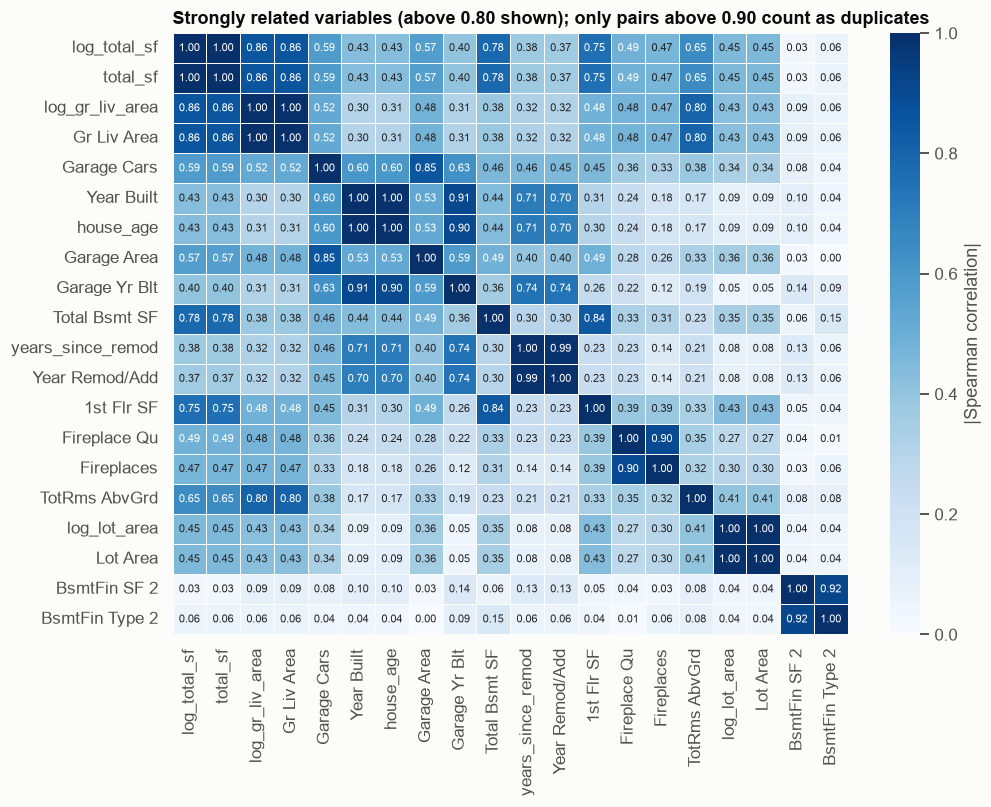

In [46]:
# Figure: the redundancy map for the numeric variables involved in a redundant pair
involved = sorted({v for s, a, b, m in pairs if m == "Spearman" and s > 0.8 for v in (a, b)},
                  key=lambda c: -LINK[c])
fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(spearman.loc[involved, involved], cmap="Blues", vmin=0, vmax=1, annot=True, fmt=".2f",
            annot_kws={"fontsize": 7.5}, linewidths=0.5, linecolor=COLORS["surface"],
            cbar_kws={"label": "|Spearman correlation|"}, ax=ax)
ax.set_title("Strongly related variables (above 0.80 shown); only pairs above 0.90 count as duplicates")
plt.tight_layout()
save_fig(fig, "02_redundancy_map")
plt.show()

**Stage 4: how many variables, and is it better to use all of them?** Variables are added in order of their link to price, and the cross-validated error is measured at each step. The error is the RMSE of log price, which reads roughly as a typical percentage error (0.10 ≈ 10%). The dashed lines show the error when **every candidate** is used. The rule is fixed in advance: keep the smallest set whose error is within one standard error of the best option, the full set included. Extra variables beyond that point add complexity without a gain we can distinguish from noise.

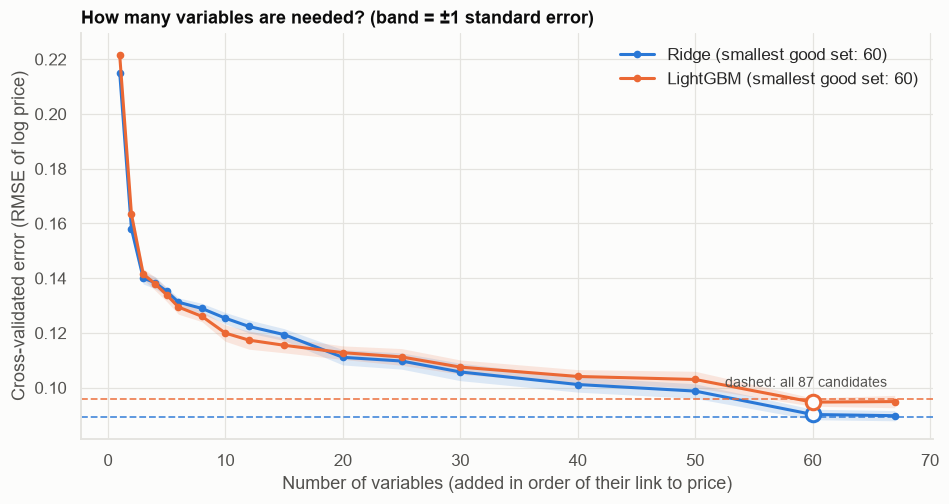

Smallest set within one standard error of the best option: {'LightGBM': 60, 'Ridge': 60} | selected: 60


In [47]:
def cv_log_rmse(model_kind, cols):
    """5-fold cross-validated RMSE of log price on the training set (one value per fold)."""
    X = train_df[cols]
    scores = []
    for tr, va in kf.split(X):
        model = make_model(model_kind, cols).fit(X.iloc[tr], y_train_log[tr])
        scores.append(root_mean_squared_error(y_train_log[va], model.predict(X.iloc[va])))
    return np.array(scores)


relevance_order = sorted(after_stage3, key=lambda c: (-LINK[c], simplicity(c)))
K_GRID = sorted({k for k in [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 40, 50, 60] if k < len(relevance_order)}
                | {len(relevance_order)})
MODELS_FOR_SELECTION = ["Ridge", "LightGBM"]
curve, all_ref = [], {}
for model_kind in MODELS_FOR_SELECTION:
    for k in K_GRID:
        s = cv_log_rmse(model_kind, relevance_order[:k])
        curve.append({"model": model_kind, "k": k, "mean": s.mean(), "se": s.std(ddof=1) / np.sqrt(len(s))})
    s = cv_log_rmse(model_kind, CANDIDATES)
    all_ref[model_kind] = {"mean": s.mean(), "se": s.std(ddof=1) / np.sqrt(len(s))}
curve = pd.DataFrame(curve)

# One-standard-error rule against the best option, the full candidate set included
chosen_k = {}
for model_kind, g in curve.groupby("model"):
    options = [(r["mean"], r["se"]) for _, r in g.iterrows()] + [(all_ref[model_kind]["mean"], all_ref[model_kind]["se"])]
    best_mean, best_se = min(options)
    good = g[g["mean"] <= best_mean + best_se]
    chosen_k[model_kind] = int(good["k"].min()) if len(good) else None   # None: only the full set is good enough
USE_ALL_CANDIDATES = any(k is None for k in chosen_k.values())
K_SELECTED = len(relevance_order) if USE_ALL_CANDIDATES else max(chosen_k.values())

fig, ax = plt.subplots(figsize=(10, 4.8))
for model_kind, color in [("Ridge", COLORS["blue"]), ("LightGBM", COLORS["orange"])]:
    g = curve[curve["model"] == model_kind]
    ax.fill_between(g["k"], g["mean"] - g["se"], g["mean"] + g["se"], color=color, alpha=0.15, linewidth=0)
    pick_text = "only the full set" if chosen_k[model_kind] is None else f"smallest good set: {chosen_k[model_kind]}"
    ax.plot(g["k"], g["mean"], marker="o", ms=4, lw=2, color=color, label=f"{model_kind} ({pick_text})")
    ax.axhline(all_ref[model_kind]["mean"], color=color, lw=1.2, ls="--", alpha=0.8)
    if chosen_k[model_kind] is not None:
        pick = g[g["k"] == chosen_k[model_kind]]
        ax.scatter(pick["k"], pick["mean"], s=90, facecolor=COLORS["surface"], edgecolor=color, linewidth=2, zorder=4)
ax.annotate(f"dashed: all {len(CANDIDATES)} candidates", (K_GRID[-1], max(r["mean"] for r in all_ref.values())),
            xytext=(-5, 8), textcoords="offset points", ha="right", fontsize=9, color=COLORS["text2"])
ax.set_xlabel("Number of variables (added in order of their link to price)")
ax.set_ylabel("Cross-validated error (RMSE of log price)")
ax.set_title("How many variables are needed? (band = ±1 standard error)")
ax.legend(frameon=False)
save_fig(fig, "02_selection_curve")
plt.show()
print("Smallest set within one standard error of the best option:", chosen_k,
      "| use all candidates:" if USE_ALL_CANDIDATES else "| selected:", "yes" if USE_ALL_CANDIDATES else K_SELECTED)

In [48]:
# Stage 5: business override (provisional list, reviewed in Sections 4-5): variables changed by Q3 scenarios
KEEP_FOR_Q2_Q3 = ["Overall Qual", "Overall Cond", "Kitchen Qual", "Exter Qual", "Central Air", "Heating QC",
                  "BsmtFin Type 1", "BsmtFin SF 1", "Bsmt Unf SF", "Year Remod/Add", "Full Bath", "Half Bath",
                  "Fireplaces", "Fireplace Qu", "Wood Deck SF", "Paved Drive", "Garage Finish", "Fence"]
if USE_ALL_CANDIDATES:
    selected = list(CANDIDATES)
    for c in CANDIDATES:
        stage, text = outcome.get(c, (4, ""))
        outcome[c] = (4, "Kept: all candidates are used (stage 4)" + (f"; flagged at stage {stage}: {text}" if text else ""))
else:
    selected = relevance_order[:K_SELECTED]
    for c in relevance_order[K_SELECTED:]:
        outcome[c] = (4, f"Dropped: not needed (beyond the {K_SELECTED} most price-related variables)")
    for c in KEEP_FOR_Q2_Q3:
        if c in selected:
            continue
        stage, text = outcome.get(c, (None, ""))
        partner = text.split("same information as ")[1].split(" (")[0] if "same information as" in text else None
        if partner in selected:
            outcome[c] = (5, f"{text}; for Q3 it is represented by {partner}")
        else:
            selected.append(c)
            outcome[c] = (5, f"Kept by business override: changed by an improvement scenario in Q3 (was: {text})")
    for c in selected:
        outcome.setdefault(c, (4, "Kept: among the most price-related variables"))

FULL_FEATURE_COLS = CANDIDATES
FEATURE_COLS = selected
NUM_COLS, ORD_COLS, NOM_COLS = split_by_kind(FEATURE_COLS)
print(f"Selected variables: {len(FEATURE_COLS)} ({len(NUM_COLS)} numbers, {len(ORD_COLS)} ordered categories, "
      f"{len(NOM_COLS)} unordered categories) out of {len(CANDIDATES)} candidates")

# Trade-off table: what each set size costs or gains (cross-validated, training set)
SETS = {"top 15": relevance_order[:15], "top 25": relevance_order[:25], f"selected ({len(FEATURE_COLS)})": FEATURE_COLS,
        f"all after stages 1-3 ({len(after_stage3)})": after_stage3, f"all candidates ({len(CANDIDATES)})": CANDIDATES}
tradeoff = []
for label, cols in SETS.items():
    row = {"variable set": label, "variables": len(cols)}
    for model_kind in MODELS_FOR_SELECTION:
        _, _, m = cv_oof_log_model(make_model(model_kind, cols), train_df[cols], y_train_log, p_train_usd, kf)
        row[f"{model_kind} MAPE (%)"] = round(m["MAPE (%)"], 2)
        row[f"{model_kind} MAE ($)"] = round(m["MAE ($)"], 0)
    tradeoff.append(row)
tradeoff = pd.DataFrame(tradeoff).set_index("variable set")
_, _, m_ridge_nolog = cv_oof_log_model(make_model("Ridge", FEATURE_COLS, log_skewed=False), train_df[FEATURE_COLS],
                                       y_train_log, p_train_usd, kf)
print(f"Log-scale check (Ridge, selected variables): MAPE {tradeoff.iloc[2]['Ridge MAPE (%)']:.2f}% with skewed amounts "
      f"on a log scale vs {m_ridge_nolog['MAPE (%)']:.2f}% without")
tradeoff

Selected variables: 60 (27 numbers, 16 ordered categories, 17 unordered categories) out of 87 candidates


Log-scale check (Ridge, selected variables): MAPE 6.64% with skewed amounts on a log scale vs 6.76% without


,variables,Ridge MAPE (%),Ridge MAE ($),LightGBM MAPE (%),LightGBM MAE ($)
variable set,,,,,
top 15,15,8.93,15784.0,8.41,14958.0
top 25,25,8.15,14570.0,8.09,14479.0
selected (60),60,6.64,12023.0,6.88,12534.0
all after stages 1-3 (67),67,6.63,12000.0,6.93,12650.0
all candidates (87),87,6.56,11998.0,6.98,12681.0


**How many variables, and why.** The trade-off table answers the question directly:
1. **Removing variables with no information or duplicate information costs nothing.** Models on the variables left after stages 1–3 are as accurate as models on every candidate.
2. **Beyond that, each extra variable adds a little.** The curve keeps improving slowly up to the selected size, where the error is within one standard error of the best option for both models: slightly above the full set for Ridge, slightly below it for LightGBM.
3. **A compact set is noticeably less accurate.** With 15 or 25 variables, the typical error rises by more than a percentage point, and the average error in dollars rises accordingly (MAE columns).

**Conclusion.** The models use the selected set. Using every candidate would not be measurably more accurate, and it would bring back variables that are nearly constant or duplicated: they split importance between near-copies in Q2 and are harder to explain. A shorter input for brokers is possible, but only at the accuracy cost shown in the table. Whether to offer such a "quick valuation" version is discussed in Section 3.

The log-scale check printed above the table shows why the linear models apply log(1 + x) to skewed amounts: it lowers Ridge's error on the same variables.

**Glossary of candidate variables.** Every candidate variable appears below: its source, its meaning (word for word from the data dictionary, or the definition of a computed variable), its type, its link to price, and the outcome of the selection with the reason. Kept variables are listed first, in order of their link to price.

In [49]:
rows = []
for c in CANDIDATES:
    stage, text = outcome[c]
    if c in VAR_DESCRIPTIONS:
        source, meaning = "Data dictionary", VAR_DESCRIPTIONS[c]
    else:
        source, meaning = "Computed", f"{ENGINEERED[c]['meaning']} = {ENGINEERED[c]['formula']}"
    rows.append({"Variable": c, "Kept": "yes" if c in FEATURE_COLS else "no", "Source": source, "Meaning": meaning,
                 "Type": kind_of(c), "Link to price": round(LINK[c], 2), "Stage": stage, "Outcome": text})
glossary = (pd.DataFrame(rows).sort_values(["Kept", "Link to price"], ascending=[False, False]).set_index("Variable"))
glossary.to_csv(PROCESSED_DIR / "variable_glossary.csv")
print(glossary["Kept"].value_counts().rename({"yes": "kept", "no": "dropped"}).to_dict(),
      "| dropped by stage:", glossary.loc[glossary["Kept"] == "no", "Stage"].value_counts().sort_index().to_dict())
with pd.option_context("display.max_colwidth", None, "display.max_rows", 200):
    display(glossary)

{'kept': 60, 'dropped': 27} | dropped by stage: {1: 13, 3: 6, 4: 7, 5: 1}


,Kept,Source,Meaning,Type,Link to price,Stage,Outcome
Variable,,,,,,,
Overall Qual,yes,Data dictionary,Rates the overall material and finish of the house.; Integer from 1 (Very Poor) to 10 (Very Excellent).,number,0.82,4,Kept: among the most price-related variables
total_sf,yes,Computed,Total floor area: above-ground living area plus basement (sqft) = Gr Liv Area + Total Bsmt SF,number,0.82,4,Kept: among the most price-related variables
Neighborhood,yes,Data dictionary,Physical location within city limits.,category,0.77,4,Kept: among the most price-related variables
Gr Liv Area,yes,Data dictionary,Above-grade (ground) living area square feet (numeric).,number,0.73,4,Kept: among the most price-related variables
Garage Cars,yes,Data dictionary,Size of garage in car capacity (integer).; dictionary note: NaN = no garage,number,0.71,4,Kept: among the most price-related variables
total_baths,yes,Computed,"All bathrooms, half baths counted as one half = Full Bath + 0.5 Half Bath + Bsmt Full Bath + 0.5 Bsmt Half Bath",number,0.71,4,Kept: among the most price-related variables
Exter Qual,yes,Data dictionary,Quality of the material on the exterior,ordered category,0.69,4,Kept: among the most price-related variables
Bsmt Qual,yes,Data dictionary,Height of the basement; NaN = no basement,ordered category,0.69,4,Kept: among the most price-related variables
Year Built,yes,Data dictionary,Original construction year.,number,0.68,4,Kept: among the most price-related variables


<a id="s2-8"></a>

### 2.8 Lot Frontage: cross-validation check (Section 1.6)

The team dropped `Lot Frontage` (linear feet of street connected to the property) in Section 1.6. This check measures what it would add to the selected model: 5-fold cross-validated LightGBM on the training set, with and without it. When included, it is imputed with the median plus a "was missing" flag.

In [50]:
lf_map = df.set_index("PID")["Lot Frontage"]
train_with_lf = train_df[FEATURE_COLS].copy()
train_with_lf["Lot Frontage"] = train_df["PID"].map(lf_map)
_, _, m_no_lf = cv_oof_log_model(make_model("LightGBM", FEATURE_COLS), train_df[FEATURE_COLS], y_train_log, p_train_usd, kf)
_, _, m_with_lf = cv_oof_log_model(
    Pipeline([("prep", build_preprocessor(NUM_COLS + ["Lot Frontage"], ORD_COLS, NOM_COLS, scale=False, add_missing_ind=True)),
              ("reg", lgb.LGBMRegressor(**LGB_PARAMS))]),
    train_with_lf, y_train_log, p_train_usd, kf)
lf_check = pd.DataFrame({"Without Lot Frontage": m_no_lf, "With Lot Frontage (+ missing flag)": m_with_lf}).T
lf_check.round({"RMSE ($)": 0, "MAE ($)": 0, "MedAE ($)": 0, "MAPE (%)": 2, "R2": 4})

,RMSE ($),MAE ($),MedAE ($),MAPE (%),R2
Without Lot Frontage,19325.0,12534.0,8437.0,6.88,0.9401
With Lot Frontage (+ missing flag),19554.0,12601.0,8519.0,6.91,0.9387


<a id="s2-9"></a>

### 2.9 Key results

In [51]:
lfl = by_year["like-for-like %"]
print("Key results - Section 2")
print(f"  Split: {len(train_df):,} training and {len(test_df):,} test sales (stratified by price decile)")
print(f"  Target skewness: price {train_df['SalePrice'].skew():.2f} -> log(price) {log_price_train.skew():.2f}")
print(f"  Like-for-like price by year: from {lfl.min():+.1f}% to {lfl.max():+.1f}% vs a comparable house; "
      f"2010 covers months {by_year.loc[2010, 'first month']}-{by_year.loc[2010, 'last month']} only")
print(f"  Neighborhoods: median price per sqft varies {spread_ratio:.1f}x (neighborhoods with >= {MIN_SALES_RELIABLE} sales)")
print(f"  House age vs price per sqft: Spearman {age_rho:.2f}; houses built before 1950 with remodel year 1950: "
      f"{floor_1950.sum()} of {built_pre1950.sum()}")
print(f"  Variable selection: {len(CANDIDATES)} candidates -> {len(after_stage1)} (information) -> {len(after_stage3)} "
      f"(redundancy) -> {len(FEATURE_COLS)} used by the models (stage 4 rule: {chosen_k}"
      + ("; all candidates kept)" if USE_ALL_CANDIDATES else ")"))
sel_row, all_row = tradeoff.iloc[2], tradeoff.iloc[-1]
print("  Cross-validated MAPE, selected vs all candidates: " + "; ".join(
    f"{m} {sel_row[f'{m} MAPE (%)']:.2f}% vs {all_row[f'{m} MAPE (%)']:.2f}%" for m in MODELS_FOR_SELECTION))
print(f"  Log scale for linear models (Ridge MAPE, selected variables): {tradeoff.iloc[2]['Ridge MAPE (%)']:.2f}% with vs "
      f"{m_ridge_nolog['MAPE (%)']:.2f}% without")
print(f"  Lot Frontage check (LightGBM MAPE): without {m_no_lf['MAPE (%)']:.2f}% vs with {m_with_lf['MAPE (%)']:.2f}%")

Key results - Section 2
  Split: 2,103 training and 526 test sales (stratified by price decile)
  Target skewness: price 1.63 -> log(price) 0.21
  Like-for-like price by year: from -0.7% to +2.7% vs a comparable house; 2010 covers months 1-7 only
  Neighborhoods: median price per sqft varies 1.9x (neighborhoods with >= 10 sales)
  House age vs price per sqft: Spearman -0.59; houses built before 1950 with remodel year 1950: 203 of 418
  Variable selection: 87 candidates -> 74 (information) -> 67 (redundancy) -> 60 used by the models (stage 4 rule: {'LightGBM': 60, 'Ridge': 60})
  Cross-validated MAPE, selected vs all candidates: Ridge 6.64% vs 6.56%; LightGBM 6.88% vs 6.98%
  Log scale for linear models (Ridge MAPE, selected variables): 6.64% with vs 6.76% without
  Lot Frontage check (LightGBM MAPE): without 6.88% vs with 6.91%


<a id="s2-decisions"></a>

### Decisions and rationale — Section 2

| Decision | Alternatives considered | Evidence and reason |
|---|---|---|
| The train/test split comes first. All exploration and selection use the training set only. | Use the full sample for the descriptive figures | No decision is influenced by the test set, so the test scores in Section 3 stay honest. |
| Models predict log(price). | Model the price in dollars | Price is strongly right-skewed and its log is close to symmetric (2.3). Errors then behave as percentages. |
| No time variables for the price level; 2010 is checked separately in Section 3. | Add sale year and month as inputs | Like-for-like prices are flat across 2006–2009, and the seasonal pattern is in volume, not price (2.4). The selection also drops sale year and month (glossary). |
| New variables: `house_age`, `years_since_remod`, `is_remodeled`, `total_sf`, `total_baths`, `porch_sf`, plus log versions that the selection removes as duplicates (2.1). | Use only dictionary variables | They express quantities buyers reason with. The selection keeps only those that add information. |
| `is_remodeled` is kept as defined, despite the 1950 recording pattern. | Count only remodels after 1950; add a flag | Team decision. Documented in the glossary and in 2.5. The selection drops the variable anyway (weak link to price). |
| Category orderings are kept as defined. `Bsmt Qual` is documented as basement height, per the dictionary. | Make `Fence` and `Electrical` unordered | Team decision. Tree models are not affected by the order. |
| Linear models see skewed amounts on a log scale, inside their pipeline (2.6). | Separate `log_` variables | One variable per concept, with its dictionary name. Lowers the linear model's error (log-scale check, 2.7). |
| Variable selection (2.7): drop nearly constant variables (one value above 95%) and true duplicates (similarity above 0.90); keep the smallest set within one standard error of the best option, the full set included; re-add what Q3 needs. | Use every candidate; a fixed compact set; a 0.80 redundancy threshold | The selected set is as accurate as the full set, within noise, without the constant and duplicated variables. Compact sets cost noticeably more error (trade-off table). The 0.80 threshold dropped related but different variables, such as living area (team decision: 0.90). |
| Sections 3–6 use the selected variables, and Section 3 also reports the full set. | All variables everywhere | Team decision. Shorter model inputs and cleaner driver rankings for Q2. |
| `Lot Frontage` stays dropped. | Keep it with a median fill and a "was missing" flag | No gain in cross-validated error (2.8). |

<a id="s3"></a>

## 3. Q1 — Price range model

> **In brief.** *Question (Q1):* what is a reasonable listing range for a home? *Answer:* a blend of a linear model and tree models gives a reference price. Calibrated ranges around it, an 80% listing range and a 50% negotiation band, held their stated share of unseen sales in every price tier. A valuation card produces them for any home. *Numbers:* [Key results](#s3-6). *Decisions:* [end of section](#s3-decisions).

**Client question.** *Given a property with certain characteristics, what is a reasonable price range to list it at?* Brokers need a reference that is a starting point for the conversation with the owner, not a final verdict.

**Approach.**
- **3.1** Candidate models, each tuned by cross-validation on the training set.
- **3.2** A single model or a blend of several? The rule is fixed before seeing the result.
- **3.3** The final model is checked once on the test set, plus a time-based check.
- **3.4** The listing range and negotiation band, calibrated so they contain the stated share of sales in each price tier.
- **3.5** A valuation card for brokers.

**Inputs.** The 60 variables selected in Section 2.7 (see the glossary). The target is log(price) (2.3), and prices are reported back in dollars as the *typical* price (2.6).

In [52]:
define_variable(
    "predicted_price_tier", "Price tier of a home according to its predicted price: Starter, Mid-market or Upper",
    "Cut at the terciles (1/3 and 2/3 points) of the cross-validated predicted prices on the training set",
    "Section 3.4: the listing range is calibrated separately for each tier, so that each tier's range contains the "
    "stated share of sales. Uses the predicted price, which is known at listing time, not the sale price.")
variables_table({
    "SalePrice": "Target: the models predict log(SalePrice); results are reported in dollars",
    "predicted_price_tier": None,
})

,Source,Meaning,Codes / formula,Role in this section
Variable,,,,
SalePrice,Data dictionary,Sale price of the property in US dollars (numeric).,numeric,Target: the models predict log(SalePrice); results are reported in dollars
predicted_price_tier,Computed,"Price tier of a home according to its predicted price: Starter, Mid-market or Upper",Cut at the terciles (1/3 and 2/3 points) of the cross-validated predicted prices on the training set,"Section 3.4: the listing range is calibrated separately for each tier, so that each tier's range contains the stated share of sales. Uses the predicted price, which is known at listing time, not the sale price."


<a id="s3-1"></a>

### 3.1 Candidate models and their tuning

| Model | In plain words |
|---|---|
| Naive baseline | Predicts the median training price for every home: the error of knowing nothing. |
| Simple baseline | A linear model on living area, overall quality and build year: roughly a broker's rule of thumb. |
| Ridge | A linear model on log price using all selected variables, with a penalty (`alpha`) that shrinks weak effects. |
| ElasticNet | Like Ridge, but it can also set weak effects exactly to zero (`l1_ratio` controls how much). |
| Random Forest | The average of many decision trees, each grown on a random part of the data. |
| HistGradientBoosting, LightGBM | Many small decision trees built one after another, each correcting the errors of the previous ones. |

**Tuning.** Each model's key settings are chosen by 5-fold cross-validation on the training set. Every model uses the same folds, and the setting with the lowest error (RMSE of log price) wins. Limitation: settings are chosen and scored on the same folds, so the cross-validated errors are slightly optimistic. The test set in 3.3 gives the unbiased check.

In [53]:
CANDIDATE_MODELS = {   # name: (builder from a settings dict, settings grid explored by cross-validation)
    "Ridge": (lambda p: linear_pipe(Ridge(**p)), {"alpha": [1, 3, 10, 15, 30, 100]}),
    "ElasticNet": (lambda p: linear_pipe(ElasticNet(max_iter=20000, **p)),
                   {"alpha": [0.001, 0.003, 0.01], "l1_ratio": [0.2, 0.5, 0.8]}),
    "Random Forest": (lambda p: tree_pipe(RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1, **p)),
                      {"min_samples_leaf": [1, 3], "max_features": [0.33, 1.0]}),
    "HistGradientBoosting": (lambda p: tree_pipe(HistGradientBoostingRegressor(
                                 max_iter=400, learning_rate=0.04, l2_regularization=1.0, random_state=SEED, **p)),
                             {"max_leaf_nodes": [15, 31], "min_samples_leaf": [10, 20]}),
    "LightGBM": (lambda p: tree_pipe(lgb.LGBMRegressor(**{**LGB_PARAMS, **p})),
                 {"num_leaves": [8, 16, 32], "min_child_samples": [10, 20, 40]}),
}

tuning_rows, best_params, oof_logs, fold_scores = [], {}, {}, {}
for name, (make, grid) in CANDIDATE_MODELS.items():
    results = []
    for values in product(*grid.values()):
        params = dict(zip(grid.keys(), values))
        oof = oof_log_predictions(make(params))
        results.append((fold_rmse(oof), params, oof))
    scores, params, oof = min(results, key=lambda r: r[0].mean())
    best_params[name], oof_logs[name], fold_scores[name] = params, oof, scores
    tuning_rows.append({"model": name, "settings tried": len(results), "best setting": params,
                        "CV RMSE (log), best": scores.mean(), "SE": scores.std(ddof=1) / np.sqrt(len(scores)),
                        "CV RMSE (log), worst setting": max(r[0].mean() for r in results)})
tuning = pd.DataFrame(tuning_rows).set_index("model").sort_values("CV RMSE (log), best")

# Baselines (no tuning)
SIMPLE_COLS = ["Gr Liv Area", "Overall Qual", "Year Built"]
oof_logs["Simple baseline"] = oof_log_predictions(linear_pipe(Ridge(alpha=1.0), SIMPLE_COLS), SIMPLE_COLS)
oof_logs["Naive baseline"] = np.zeros(len(train_df))
for tr, va in kf.split(train_df):
    oof_logs["Naive baseline"][va] = np.median(y_train_log[tr])
with pd.option_context("display.max_colwidth", None):
    display(tuning.round(4))

,settings tried,best setting,"CV RMSE (log), best",SE,"CV RMSE (log), worst setting"
model,,,,,
Ridge,6,{'alpha': 10},0.0901,0.0019,0.0935
ElasticNet,9,"{'alpha': 0.001, 'l1_ratio': 0.2}",0.0904,0.0020,0.1036
LightGBM,9,"{'num_leaves': 16, 'min_child_samples': 10}",0.0938,0.0021,0.0968
HistGradientBoosting,4,"{'max_leaf_nodes': 15, 'min_samples_leaf': 20}",0.0966,0.0018,0.0994
Random Forest,4,"{'min_samples_leaf': 1, 'max_features': 0.33}",0.1086,0.0028,0.1153


<a id="s3-2"></a>

### 3.2 A single model or a blend?

**Why a blend could help.** A linear model and a tree model make different kinds of errors. The linear model extrapolates size and quality effects smoothly. Trees capture thresholds and interactions such as "this neighborhood with this quality". Averaging their predictions can cancel part of each one's errors, but only if the gain is real.

**Decision rule, fixed before seeing the result.** Use a blend only if its cross-validated error beats the best single model by more than one standard error of the difference. Otherwise use the single model, which is simpler to explain.

**How the blend is built and measured.**
1. **Weight exploration (figure, panel B).** For the strongest linear model and the strongest tree model, the cross-validated error of every mix from 0% to 100% shows how sensitive the result is to the weights.
2. **Learned weights.** Non-negative weights over all tuned models are fitted to their out-of-fold predictions (non-negative least squares) and rescaled to sum to 1. A model whose predictions add nothing gets weight 0.
3. **An honest error for the blend.** Weights are learned on 4 folds of out-of-fold predictions and scored on the 5th, so the blend is never scored on the data that set its weights.

In [54]:
MODEL_NAMES = list(CANDIDATE_MODELS)
oof_matrix = np.column_stack([oof_logs[n] for n in MODEL_NAMES])


def learn_weights(pred_matrix, y):
    """Non-negative weights that best combine the models' log predictions, rescaled to sum to 1."""
    w, _ = nnls(pred_matrix, y)
    return w / w.sum()


# Honest blend error: weights learned on 4 folds of out-of-fold predictions, scored on the 5th
blend_oof_log = np.zeros(len(train_df))
for tr, va in kf.split(train_df):
    blend_oof_log[va] = oof_matrix[va] @ learn_weights(oof_matrix[tr], y_train_log[tr])
fold_scores["Blend (learned weights)"] = fold_rmse(blend_oof_log)

best_single = tuning.index[0]
gain_by_fold = fold_scores[best_single] - fold_scores["Blend (learned weights)"]   # positive = blend is better
blend_gain, blend_gain_se = gain_by_fold.mean(), gain_by_fold.std(ddof=1) / np.sqrt(len(gain_by_fold))
USE_BLEND = blend_gain > blend_gain_se

learned = learn_weights(oof_matrix, y_train_log)
if USE_BLEND:
    kept = {n: w for n, w in zip(MODEL_NAMES, learned) if w > 1e-6}
    FINAL_WEIGHTS = {n: w / sum(kept.values()) for n, w in kept.items()}
else:
    FINAL_WEIGHTS = {best_single: 1.0}
final_oof_log = blend_oof_log if USE_BLEND else oof_logs[best_single]   # honest out-of-fold predictions of the final model

# Weight exploration: strongest linear vs strongest tree model
best_linear = min(["Ridge", "ElasticNet"], key=lambda n: fold_scores[n].mean())
best_tree = min(["LightGBM", "HistGradientBoosting", "Random Forest"], key=lambda n: fold_scores[n].mean())
shares = np.linspace(0, 1, 21)
mix = np.array([fold_rmse((1 - s) * oof_logs[best_linear] + s * oof_logs[best_tree]) for s in shares])

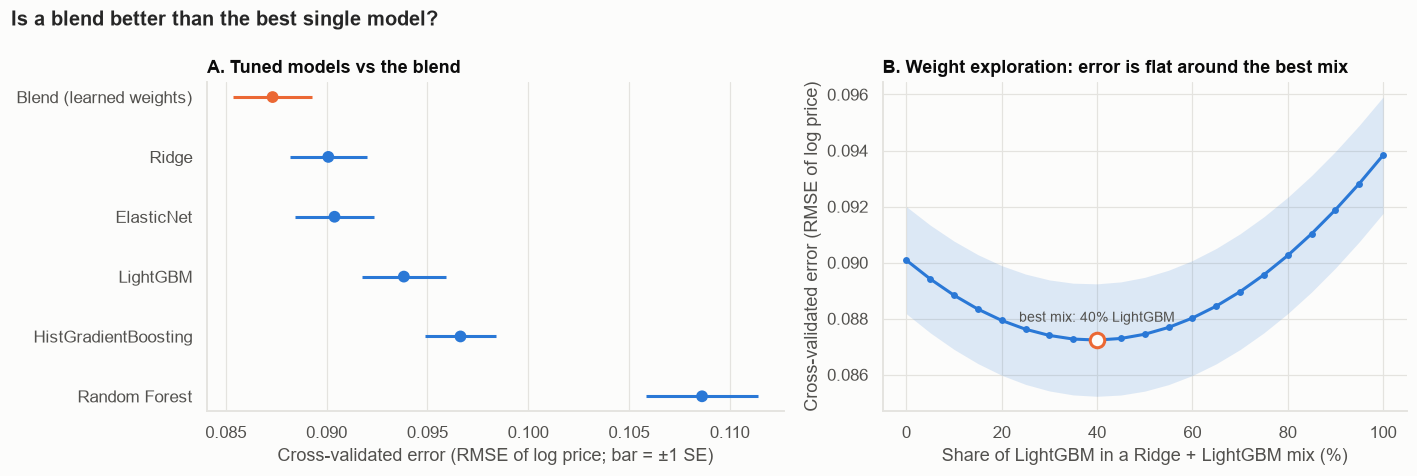

Best single model: Ridge | blend gain over it: 0.0028 RMSE(log) per fold (SE 0.0006) -> use the blend
Learned weights (all tuned models): {'Ridge': 0.607, 'ElasticNet': 0.0, 'Random Forest': 0.0, 'HistGradientBoosting': 0.096, 'LightGBM': 0.297}
Final model weights: {'Ridge': 0.607, 'HistGradientBoosting': 0.096, 'LightGBM': 0.297}


In [55]:
summary = pd.DataFrame({m: {"CV RMSE (log)": s.mean(), "SE": s.std(ddof=1) / np.sqrt(len(s))} for m, s in fold_scores.items()}).T
summary = summary.sort_values("CV RMSE (log)")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
y = np.arange(len(summary))
colors = [COLORS["orange"] if m.startswith("Blend") else COLORS["blue"] for m in summary.index]
ax.errorbar(summary["CV RMSE (log)"], y, xerr=summary["SE"], fmt="none", ecolor=colors, elinewidth=2, capsize=0)
ax.scatter(summary["CV RMSE (log)"], y, c=colors, s=45, zorder=3)
ax.set_yticks(y, labels=summary.index)
ax.invert_yaxis()
ax.set_xlabel("Cross-validated error (RMSE of log price; bar = ±1 SE)")
ax.set_title("A. Tuned models vs the blend")
ax.grid(axis="y", visible=False)
ax = axes[1]
ax.fill_between(100 * shares, mix.mean(1) - mix.std(1, ddof=1) / np.sqrt(mix.shape[1]),
                mix.mean(1) + mix.std(1, ddof=1) / np.sqrt(mix.shape[1]), color=COLORS["blue"], alpha=0.15, linewidth=0)
ax.plot(100 * shares, mix.mean(1), marker="o", ms=3.5, lw=2, color=COLORS["blue"])
best_share = shares[mix.mean(1).argmin()]
ax.scatter([100 * best_share], [mix.mean(1).min()], s=90, facecolor=COLORS["surface"], edgecolor=COLORS["orange"], linewidth=2, zorder=4)
ax.annotate(f"best mix: {100 * best_share:.0f}% {best_tree}", (100 * best_share, mix.mean(1).min()), xytext=(0, 12),
            textcoords="offset points", ha="center", fontsize=9, color=COLORS["text2"])
ax.set_xlabel(f"Share of {best_tree} in a {best_linear} + {best_tree} mix (%)")
ax.set_ylabel("Cross-validated error (RMSE of log price)")
ax.set_title("B. Weight exploration: error is flat around the best mix")
fig.suptitle("Is a blend better than the best single model?", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
save_fig(fig, "03_model_selection")
plt.show()

print(f"Best single model: {best_single} | blend gain over it: {blend_gain:.4f} RMSE(log) per fold "
      f"(SE {blend_gain_se:.4f}) -> {'use the blend' if USE_BLEND else 'use the single model'}")
print("Learned weights (all tuned models):", {n: round(float(w), 3) for n, w in zip(MODEL_NAMES, learned)})
print("Final model weights:", {n: round(float(w), 3) for n, w in FINAL_WEIGHTS.items()})

**Reading.**
- **Tuning matters.** For each model, the tuning table shows the gap between the best and the worst setting tried. The chosen settings are evidence-based, not defaults.
- **Single models.** Ridge and ElasticNet are the strongest, the boosted trees are close behind, and Random Forest is clearly weaker (panel A).
- **The blend passes the rule.** Its honest cross-validated error is lower than the best single model's by several standard errors (printed above), so the final model is the blend.
- **Learned weights.** They keep three models and give the others weight 0. ElasticNet adds nothing beyond Ridge, being almost the same model, and Random Forest adds nothing beyond the boosted trees. The linear model carries most of the weight, and the tree models add what it misses.
- **The exact weights barely matter.** In panel B the error is flat over a wide range of mixes around the best one, so the result does not hinge on fine-tuning the weights.

<a id="s3-3"></a>

### 3.3 Final check on the test set, and over time

The tuned models are refitted on the whole training set and scored **once** on the 526 test sales. The 95% intervals come from a bootstrap that uses the **same resampled sales for every model**, so models are compared on identical data. The paired comparison then tests whether the final model really beats the best single model on test sales. The time-based check trains on 2006–2009 sales and predicts 2010, the conditions of using the model on newer sales. Fit and prediction times are printed separately, labeled as machine-dependent (Section 0 decision).

In [56]:
import time

final_models, fit_seconds = {}, {}
for name in MODEL_NAMES:
    t0 = time.perf_counter()
    final_models[name] = CANDIDATE_MODELS[name][0](best_params[name]).fit(train_df[FEATURE_COLS], y_train_log)
    fit_seconds[name] = time.perf_counter() - t0
final_models["Simple baseline"] = linear_pipe(Ridge(alpha=1.0), SIMPLE_COLS).fit(train_df[SIMPLE_COLS], y_train_log)


def final_predict_log(X):
    """Log price predicted by the final model (Section 3.2) for rows that contain the model inputs."""
    return sum(w * final_models[n].predict(X[FEATURE_COLS]) for n, w in FINAL_WEIGHTS.items())


test_log = {n: final_models[n].predict(test_df[FEATURE_COLS]) for n in MODEL_NAMES}
test_log["Simple baseline"] = final_models["Simple baseline"].predict(test_df[SIMPLE_COLS])
test_log["Naive baseline"] = np.full(len(test_df), np.median(y_train_log))
t0 = time.perf_counter()
test_log["Final model"] = final_predict_log(test_df)
final_predict_ms = 1000 * (time.perf_counter() - t0)
test_usd = {n: np.exp(v) for n, v in test_log.items()}


mape = lambda a, b: 100 * mean_absolute_percentage_error(a, b)
rows = []
for name, pred in test_usd.items():
    mae, mae_lo, mae_hi = bootstrap_ci(mean_absolute_error, p_test_usd, pred, task="3.3 test bootstrap")
    mp, mp_lo, mp_hi = bootstrap_ci(mape, p_test_usd, pred, task="3.3 test bootstrap")
    rows.append({"model": name, "MAE ($)": mae, "MAE 95% low": mae_lo, "MAE 95% high": mae_hi,
                 "MedAE ($)": np.median(np.abs(p_test_usd - pred)), "MAPE (%)": mp, "MAPE 95% low": mp_lo, "MAPE 95% high": mp_hi})
test_table = pd.DataFrame(rows).set_index("model").sort_values("MAE ($)")

# Paired test: final model vs best single model on the same test sales
err_final, err_single = np.abs(p_test_usd - test_usd["Final model"]), np.abs(p_test_usd - test_usd[best_single])
_, diff_lo, diff_hi = bootstrap_ci(lambda a, b: a.mean() - b.mean(), err_final, err_single, task="3.3 paired difference")
paired_diff = err_final.mean() - err_single.mean()

# Mean vs median price: Duan's smearing factor (team decision: report the typical price, without it)
smear_factor = np.mean(np.exp(y_train_log - final_predict_log(train_df)))

display(test_table.round({c: 0 for c in test_table.columns if "$" in c or "MAE" in c} | {c: 2 for c in test_table.columns if "MAPE" in c}))
print(f"Paired test, final model minus {best_single}: MAE {paired_diff:+,.0f} $ (95% interval {diff_lo:+,.0f} to {diff_hi:+,.0f})")
print(f"Duan smearing factor: {smear_factor:.4f} (mean price would be {100 * (smear_factor - 1):.2f}% above the typical price)")
print("Machine-dependent timings (indicative only): fit " +
      ", ".join(f"{n} {s:.1f}s" for n, s in fit_seconds.items() if n in FINAL_WEIGHTS) +
      f" | final model prices all {len(test_df)} test homes in {final_predict_ms:.0f} ms")

,MAE ($),MAE 95% low,MAE 95% high,MedAE ($),MAPE (%),MAPE 95% low,MAPE 95% high
model,,,,,,,
Final model,10767.0,9740.0,11887.0,7301.0,6.11,5.45,6.92
LightGBM,11270.0,10203.0,12514.0,7587.0,6.36,5.69,7.18
HistGradientBoosting,11465.0,10419.0,12667.0,8023.0,6.45,5.80,7.27
Ridge,11586.0,10514.0,12772.0,8197.0,6.56,5.89,7.44
ElasticNet,11638.0,10562.0,12821.0,7988.0,6.58,5.91,7.46
Random Forest,13070.0,11822.0,14442.0,8961.0,7.42,6.63,8.35
Simple baseline,21289.0,19605.0,22871.0,17450.0,12.19,11.19,13.24
Naive baseline,55052.0,50494.0,59420.0,38250.0,30.75,28.24,33.38


Paired test, final model minus Ridge: MAE -819 $ (95% interval -1,221 to -460)
Duan smearing factor: 1.0022 (mean price would be 0.22% above the typical price)
Machine-dependent timings (indicative only): fit Ridge 0.1s, HistGradientBoosting 1.1s, LightGBM 0.4s | final model prices all 526 test homes in 65 ms


In [57]:
# Time-based check: train on 2006-2009, predict 2010 (whole analysis sample, settings and weights from 3.1-3.2)
before_2010, in_2010 = data_fe[data_fe["Yr Sold"] < 2010], data_fe[data_fe["Yr Sold"] == 2010]
time_models = {n: CANDIDATE_MODELS[n][0](best_params[n]).fit(before_2010[FEATURE_COLS], np.log(before_2010["SalePrice"]))
               for n in FINAL_WEIGHTS}
pred_2010 = np.exp(sum(w * time_models[n].predict(in_2010[FEATURE_COLS]) for n, w in FINAL_WEIGHTS.items()))
time_check = {"MAE ($)": mean_absolute_error(in_2010["SalePrice"], pred_2010),
              "MAPE (%)": mape(in_2010["SalePrice"].to_numpy(), pred_2010)}
print(f"Time-based check (train 2006-2009, n={len(before_2010):,}; predict 2010, n={len(in_2010)}): "
      f"MAE ${time_check['MAE ($)']:,.0f} | MAPE {time_check['MAPE (%)']:.2f}%")

Time-based check (train 2006-2009, n=2,319; predict 2010, n=310): MAE $12,062 | MAPE 6.99%


**Reading.**
- **The final model is the most accurate on unseen sales.** The paired comparison shows its advantage over the best single model is not chance: the interval printed above excludes zero.
- **Every model beats the baselines by a wide margin.** The full models roughly halve the error of the size, quality and build-year rule of thumb, and are far ahead of the naive guess.
- **Over time.** Trained on 2006–2009 and used on 2010, the error is slightly higher than on the test set but in the same range, so the model holds up on newer sales within the study period.
- **Typical vs average price.** Duan's smearing factor is practically 1, so reporting the typical price loses nothing.

<a id="s3-4"></a>

### 3.4 Listing range and negotiation band

**What brokers get.** Around the reference price, two ranges:
- an **80% listing range**, which should contain the sale price of about 8 in 10 comparable homes;
- a **50% negotiation band**, which should contain about half of them.

**How they are built (conformal calibration).** On the training set we look at how far the honest out-of-fold predictions of the final model (3.2) fell from the actual prices, measured in log price, that is in percent. The 80% range uses the error size that 80% of homes stayed within, and the 50% band the size that half stayed within. Errors differ by market segment, so this is done **separately for each predicted price tier** (`predicted_price_tier`). The ranges are therefore centered on the reference price and sized for the segment of the home. The test set then checks whether they contain the stated share of sales.

In [58]:
TIER_NAMES = ["Starter", "Mid-market", "Upper"]
RANGE_LEVELS = {"80% listing range": 0.80, "50% negotiation band": 0.50}
tier_edges = np.quantile(np.exp(final_oof_log), [1 / 3, 2 / 3])


def tier_of(pred_log):
    """Predicted price tier (cut points from the training set)."""
    return np.array(TIER_NAMES)[np.searchsorted(tier_edges, np.exp(pred_log))]


calib_tier = tier_of(final_oof_log)
abs_error_log = np.abs(y_train_log - final_oof_log)
half_width = {(tier, level): np.quantile(abs_error_log[calib_tier == tier],
                                         min(1.0, share * (1 + 1 / (calib_tier == tier).sum())))
              for tier in TIER_NAMES for level, share in RANGE_LEVELS.items()}


def price_range(pred_log, level):
    """Low and high end of a calibrated range around the predicted log price."""
    hw = np.array([half_width[(t, level)] for t in tier_of(pred_log)])
    return np.exp(pred_log - hw), np.exp(pred_log + hw)


final_test_log = test_log["Final model"]
test_tier = tier_of(final_test_log)
range_rows = []
for level, share in RANGE_LEVELS.items():
    lo, hi = price_range(final_test_log, level)
    inside = (p_test_usd >= lo) & (p_test_usd <= hi)
    for tier in ["All"] + TIER_NAMES:
        m = np.ones(len(inside), bool) if tier == "All" else test_tier == tier
        range_rows.append({"range": level, "tier": tier, "test homes": int(m.sum()), "target": share,
                           "coverage": inside[m].mean(), "median width ($)": np.median((hi - lo)[m]),
                           "median half-width (%)": 100 * np.median(np.expm1(np.log(hi[m]) - final_test_log[m]))})
range_table = pd.DataFrame(range_rows).set_index(["range", "tier"])
print("Tier cut points (predicted price): " + " | ".join(f"${e:,.0f}" for e in tier_edges))
range_table.round({"coverage": 3, "median width ($)": 0, "median half-width (%)": 1})

Tier cut points (predicted price): $141,194 | $195,130


test homes  target  coverage  median width ($)  median half-width (%)
range                tier                                                                             
80% listing range    All                526     0.8     0.825           28767.0                   10.1
                     Starter            175     0.8     0.846           25436.0                   11.1
                     Mid-market         181     0.8     0.829           27529.0                    8.7
                     Upper              170     0.8     0.800           47805.0                   10.1
50% negotiation band All                526     0.5     0.517           14409.0                    5.0
                     Starter            175     0.5     0.583           12715.0                    5.4
                     Mid-market         181     0.5     0.481           13825.0                    4.3
                     Upper              170     0.5     0.488           24407.0                    5.0

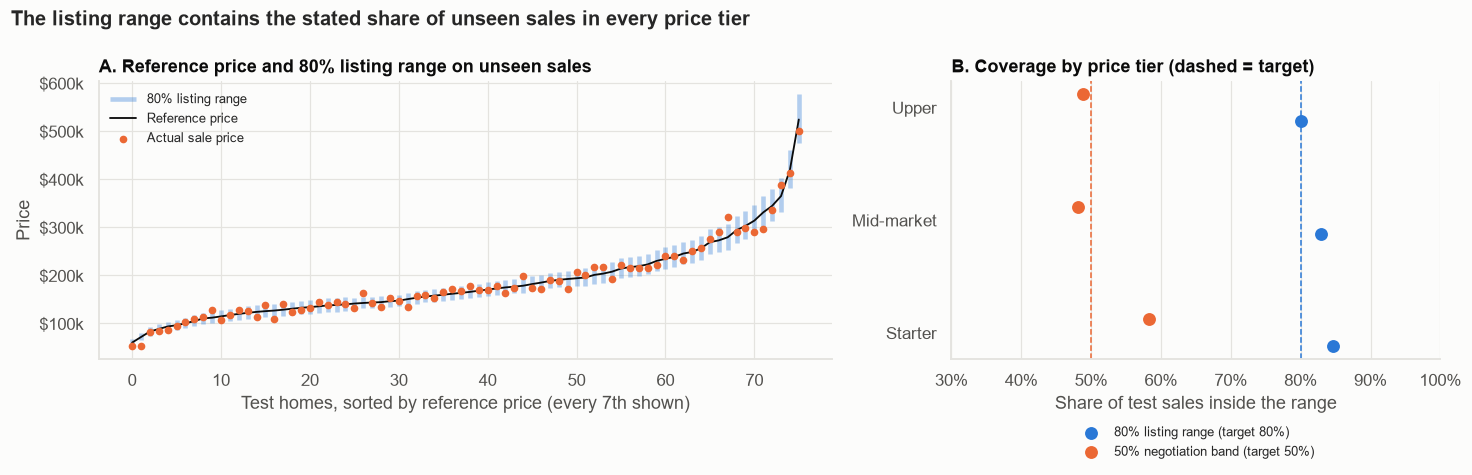

In [59]:
lo80, hi80 = price_range(final_test_log, "80% listing range")
order = np.argsort(final_test_log)
step = max(1, len(order) // 70)
shown = order[::step]
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
x = np.arange(len(shown))
ax.vlines(x, lo80[shown], hi80[shown], color=COLORS["blue"], alpha=0.35, lw=3, label="80% listing range")
ax.plot(x, np.exp(final_test_log[shown]), color=COLORS["text"], lw=1.2, label="Reference price")
ax.scatter(x, p_test_usd[shown], s=16, color=COLORS["orange"], zorder=3, label="Actual sale price")
ax.yaxis.set_major_formatter(USD)
ax.set_xlabel(f"Test homes, sorted by reference price (every {step}th shown)")
ax.set_ylabel("Price")
ax.set_title("A. Reference price and 80% listing range on unseen sales")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
ax = axes[1]
cov = range_table.reset_index()
cov = cov[cov["tier"] != "All"]
for (level, g), color, dy in zip(cov.groupby("range", sort=False), [COLORS["blue"], COLORS["orange"]], [-0.12, 0.12]):
    yy = np.arange(len(TIER_NAMES)) + dy
    ax.scatter(100 * g["coverage"], yy, s=55, color=color, label=f"{level} (target {100 * RANGE_LEVELS[level]:.0f}%)", zorder=3)
    ax.axvline(100 * RANGE_LEVELS[level], color=color, lw=1, ls="--")
ax.set_yticks(np.arange(len(TIER_NAMES)), labels=TIER_NAMES)
ax.set_xlim(30, 100)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel("Share of test sales inside the range")
ax.set_title("B. Coverage by price tier (dashed = target)")
ax.legend(frameon=False, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=1)
ax.grid(axis="y", visible=False)
fig.suptitle("The listing range contains the stated share of unseen sales in every price tier", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
plt.tight_layout()
save_fig(fig, "03_listing_ranges")
plt.show()

**Reading.**
- **The 80% listing range meets its target** overall and in every price tier (table and panel B), slightly conservatively for starter homes.
- **The 50% negotiation band is on target** overall. It is a little wide for starter homes, where more sales than intended fall inside it.
- **Widths.** The ranges are of similar size *in percent* across tiers, so in dollars they are wider for upper-tier homes (table).

**For brokers.** The 80% range is a defensible listing range. The 50% band is where about half of comparable homes close: a natural zone for the negotiation.

<a id="s3-5"></a>

### 3.5 Valuation card for brokers

`valuation_card()` turns the model into what a broker uses: for a home's characteristics, it prints the reference price, the 50% negotiation band and the 80% listing range, rounded to the nearest $1,000. The examples below are three test homes chosen by a fixed rule, **the home whose reference price is closest to the median of its price tier**, so they represent typical homes of each segment. Their actual sale prices are shown for comparison.

In [60]:
def valuation_card(homes):
    """Reference price, 50% negotiation band and 80% listing range for homes given as rows of model inputs."""
    pred_log = final_predict_log(homes)
    lo50, hi50 = price_range(pred_log, "50% negotiation band")
    lo80, hi80 = price_range(pred_log, "80% listing range")
    r = lambda v: np.round(v, -3).astype(int)
    return pd.DataFrame({
        "Neighborhood": homes["Neighborhood"].to_numpy(),
        "Living area (sqft)": homes["Gr Liv Area"].astype(int).to_numpy(),
        "Overall quality (1-10)": homes["Overall Qual"].astype(int).to_numpy(),
        "Year built": homes["Year Built"].astype(int).to_numpy(),
        "Price tier": tier_of(pred_log),
        "80% range low": r(lo80), "50% band low": r(lo50), "Reference price": r(np.exp(pred_log)),
        "50% band high": r(hi50), "80% range high": r(hi80),
    }, index=homes.index)


test_reference = pd.Series(np.exp(final_test_log), index=test_df.index)
example_ids = [(test_reference[test_tier == t] - test_reference[test_tier == t].median()).abs().idxmin() for t in TIER_NAMES]
cards = valuation_card(test_df.loc[example_ids])
cards["Actual sale price"] = test_df.loc[example_ids, "SalePrice"].astype(int)
cards.T

,408,2254,2479
Neighborhood,Sawyer,Somerst,Somerst
Living area (sqft),1040,1458,1958
Overall quality (1-10),5,6,7
Year built,1963,1999,2005
Price tier,Starter,Mid-market,Upper
80% range low,109000,152000,226000
50% band low,115000,159000,237000
Reference price,121000,165000,249000
50% band high,128000,172000,261000
80% range high,134000,180000,274000


<a id="s3-6"></a>

### 3.6 Key results

In [61]:
ft = test_table.loc["Final model"]
r80, r50 = range_table.loc[("80% listing range", "All")], range_table.loc[("50% negotiation band", "All")]
print("Key results - Section 3")
print(f"  Tuned models, best single by cross-validation: {best_single} {best_params[best_single]}")
print(f"  Blend vs best single (cross-validated): gain {blend_gain:.4f} RMSE(log), SE {blend_gain_se:.4f} -> "
      + ("blend used" if USE_BLEND else "single model used") + "; final weights "
      + ", ".join(f"{n} {w:.2f}" for n, w in FINAL_WEIGHTS.items()))
print(f"  Test set ({len(test_df)} sales): MAE ${ft['MAE ($)']:,.0f} (95% {ft['MAE 95% low']:,.0f}-{ft['MAE 95% high']:,.0f}), "
      f"median error ${ft['MedAE ($)']:,.0f}, MAPE {ft['MAPE (%)']:.2f}%")
print(f"  Versus {best_single} on the same test sales: MAE {paired_diff:+,.0f} $ (95% {diff_lo:+,.0f} to {diff_hi:+,.0f})")
print(f"  Baselines on the test set: simple MAPE {test_table.loc['Simple baseline', 'MAPE (%)']:.2f}%, "
      f"naive MAPE {test_table.loc['Naive baseline', 'MAPE (%)']:.2f}%")
print(f"  Time-based check (2006-2009 -> 2010): MAPE {time_check['MAPE (%)']:.2f}%")
print(f"  80% listing range: test coverage {r80['coverage']:.1%}, typical half-width ±{r80['median half-width (%)']:.1f}% "
      f"(${r80['median width ($)']:,.0f} wide) | 50% band: coverage {r50['coverage']:.1%}, ±{r50['median half-width (%)']:.1f}%")

Key results - Section 3
  Tuned models, best single by cross-validation: Ridge {'alpha': 10}
  Blend vs best single (cross-validated): gain 0.0028 RMSE(log), SE 0.0006 -> blend used; final weights Ridge 0.61, HistGradientBoosting 0.10, LightGBM 0.30
  Test set (526 sales): MAE $10,767 (95% 9,740-11,887), median error $7,301, MAPE 6.11%
  Versus Ridge on the same test sales: MAE -819 $ (95% -1,221 to -460)
  Baselines on the test set: simple MAPE 12.19%, naive MAPE 30.75%
  Time-based check (2006-2009 -> 2010): MAPE 6.99%
  80% listing range: test coverage 82.5%, typical half-width ±10.1% ($28,767 wide) | 50% band: coverage 51.7%, ±5.0%


<a id="s3-decisions"></a>

### Decisions and rationale — Section 3

| Decision | Alternatives considered | Evidence and reason |
|---|---|---|
| Every candidate model is tuned by 5-fold cross-validation on the training set (grids in 3.1). | Fixed, hand-set settings (previous version) | Every setting now has evidence. The gap between the best and the worst setting shows the choice matters. |
| A blend is used only if it beats the best single model by more than one standard error (rule fixed in advance). Its weights are learned from out-of-fold predictions (non-negative, summing to 1), and the mixes are explored and shown. | Hand-set weights (0.35 / 0.45 / 0.20); equal weights; a single model | The blend passes the rule in cross-validation, and the paired test on the test set confirms the gain. The weights are data-driven, and the error is flat around them (3.2). |
| The test set is used once, at the end, with paired bootstrap intervals. | Choose models by their test results | Keeps the test score an unbiased estimate of performance on new sales. |
| The reference price is the typical (median) price, without smearing. | The average price, with Duan's smearing | Simpler to explain, and the smearing factor is practically 1 (3.3). Team decision. |
| Listing range and negotiation band: conformal calibration around the final model, per predicted price tier. | Quantile LightGBM models (CQR); one calibration for all homes | Always centered on the reference price, and on target in every tier (3.4). Team decision. |
| A valuation card, with example homes chosen by a stated rule (closest to the median of each price tier). | Examples picked by rank position | The examples stay representative when results change. |
| Timings are printed separately and labeled as machine-dependent. | Timings inside the accuracy table | Section 0 decision: they are the only outputs that cannot reproduce. |
| For the boosted trees, only tree size and leaf size are tuned. The learning rate and the number of trees stay fixed. | A larger search | Limitation, to keep the run time reasonable. |

<a id="s4"></a>

## 4. Q2 — Price drivers

> **In brief.** *Question (Q2):* which characteristics move prices most, split by what owners can change? *Answer:* the building's size and age carry most of the information, followed by the overall quality and condition ratings. Owner-modifiable features add little that other characteristics do not already tell. Location matters, but far less than raw neighborhood prices suggest. *Numbers:* [Key results](#s4-5). *Decisions:* [end of section](#s4-decisions).

**Client question.** *Which characteristics of a property have the largest impact on its sale price? Ideally, split between characteristics that the owner can modify and those that are structural or location-based.*

**Approach.**
- **4.1** Every model variable is assigned to one group, by a written rule.
- **4.2** How much each group matters, measured in two complementary ways with the final model of Section 3.
- **4.3** Which individual characteristics matter most.
- **4.4** How much location alone is worth: the same house in different neighborhoods.

These are **associations** learned from past sales. They show what prices reward, not what would happen if a characteristic were changed. That question is Q3.

<a id="s4-1"></a>

### 4.1 Groups of characteristics

| Group | Rule |
|---|---|
| Location and lot | Where the home is and the land it stands on. The owner cannot change them. |
| Structure and size | The building itself: floor areas, rooms and bathrooms, age, type and style, foundation, roof style, masonry veneer, garage capacity, basement height (`Bsmt Qual`, per the dictionary) and walkout exposure. Changing them means enlarging or rebuilding. |
| Owner-modifiable | Can be changed by renovation, repair or a small outdoor addition without enlarging the house: kitchen and exterior quality, exterior covering, heating, central air, electrical, fireplace, basement and garage finishing and condition, decks and porches, fence, driveway, functional repairs, time since the last remodel. |
| Overall ratings (mixed) | `Overall Qual` and `Overall Cond` summarize both how the house was built and how it has been kept up. They are partly modifiable, so they are kept apart. |
| Sale circumstances | Describe the sale, not the home: sale type, new construction. |

The table below assigns each of the model's variables. The code checks that every variable is assigned exactly once.

In [62]:
DRIVER_GROUPS = {
    "Location and lot": ["Neighborhood", "MS Zoning", "Condition 1", "Lot Config", "Land Contour", "Lot Shape",
                         "Lot Area", "Alley"],
    "Structure and size": ["Gr Liv Area", "1st Flr SF", "2nd Flr SF", "total_sf", "Total Bsmt SF", "TotRms AbvGrd",
                           "Bedroom AbvGr", "Full Bath", "Half Bath", "Bsmt Full Bath", "total_baths", "Year Built",
                           "Bldg Type", "House Style", "MS SubClass", "Foundation", "Roof Style", "Mas Vnr Type",
                           "Mas Vnr Area", "Garage Cars", "Garage Area", "Garage Type", "Bsmt Qual", "Bsmt Exposure"],
    "Owner-modifiable": ["Kitchen Qual", "Exter Qual", "Exterior 1st", "Exterior 2nd", "Heating QC", "Central Air",
                         "Electrical", "Fireplaces", "Fireplace Qu", "BsmtFin Type 1", "BsmtFin SF 1", "Bsmt Unf SF",
                         "Bsmt Cond", "Garage Finish", "Garage Qual", "Garage Cond", "Wood Deck SF", "Open Porch SF",
                         "Enclosed Porch", "porch_sf", "Fence", "Paved Drive", "Functional", "years_since_remod"],
    "Overall ratings (mixed)": ["Overall Qual", "Overall Cond"],
    "Sale circumstances": ["Sale Type", "is_new_home"],
}
GROUP_OF = {v: g for g, vs in DRIVER_GROUPS.items() for v in vs}
assert len(GROUP_OF) == sum(len(v) for v in DRIVER_GROUPS.values()), "a variable is assigned twice"
assert set(GROUP_OF) == set(FEATURE_COLS), f"unassigned: {set(FEATURE_COLS) - set(GROUP_OF)}; extra: {set(GROUP_OF) - set(FEATURE_COLS)}"
GROUP_COLORS = dict(zip(DRIVER_GROUPS, [COLORS["blue"], COLORS["gray"], COLORS["orange"], COLORS["aqua"], "#c3c2b7"]))

taxonomy = pd.DataFrame({
    "group": [GROUP_OF[v] for v in FEATURE_COLS],
    "meaning": [VAR_DESCRIPTIONS[v] if v in VAR_DESCRIPTIONS else ENGINEERED[v]["meaning"] for v in FEATURE_COLS],
}, index=pd.Index(FEATURE_COLS, name="variable")).sort_values(["group", "variable"])
print(taxonomy["group"].value_counts().to_dict())
with pd.option_context("display.max_colwidth", None, "display.max_rows", 100):
    display(taxonomy)

{'Owner-modifiable': 24, 'Structure and size': 24, 'Location and lot': 8, 'Overall ratings (mixed)': 2, 'Sale circumstances': 2}


,group,meaning
variable,,
Alley,Location and lot,Type of alley access to property; NaN = no alley access
Condition 1,Location and lot,Proximity to various conditions (primary)
Land Contour,Location and lot,Flatness of the property
Lot Area,Location and lot,Lot size in square feet (numeric).
Lot Config,Location and lot,Lot configuration
Lot Shape,Location and lot,General shape of property
MS Zoning,Location and lot,General zoning classification of the sale
Neighborhood,Location and lot,Physical location within city limits.
Overall Cond,Overall ratings (mixed),Rates the overall condition of the house.; Integer from 1 (Very Poor) to 10 (Very Excellent).


<a id="s4-2"></a>

### 4.2 How much does each group matter?

Groups of characteristics overlap: bigger houses also tend to have better finishes. So one number per group can mislead, and we use two complementary measures:
- **Information the model loses (test set).** All of a group's variables are shuffled together across the test homes, breaking their link to price, and we measure how much the error grows (20 repetitions). This counts everything the group tells the model, including what it shares with other groups.
- **Unique contribution (cross-validation, training set).** The final model is refitted *without* the group, and we measure how much the cross-validated error grows. This counts only what no other group can replace.

Both are in the same unit: the increase in RMSE of log price, roughly a percentage-point increase in typical error.

In [63]:
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.inspection import permutation_importance


class FinalModel(BaseEstimator, RegressorMixin):
    """Wraps the final model of Section 3 (already fitted) for scikit-learn's inspection tools."""

    def fit(self, X, y=None):
        return self

    def predict(self, X):
        return final_predict_log(X)


X_test_f = test_df[FEATURE_COLS]
base_test_rmse = root_mean_squared_error(y_test_log, final_predict_log(X_test_f))


def shuffled_group_loss(cols, task, n_repeats=20):
    """Increase in test RMSE(log) when the group's columns are shuffled together (same order for all of them)."""
    rng, losses = rng_for(task), []
    for _ in range(n_repeats):
        order = rng.permutation(len(X_test_f))
        shuffled = X_test_f.copy()
        for c in cols:
            shuffled[c] = X_test_f[c].to_numpy()[order]
        losses.append(root_mean_squared_error(y_test_log, final_predict_log(shuffled)) - base_test_rmse)
    return np.mean(losses), np.std(losses, ddof=1)


def oof_final_without(cols_out):
    """Out-of-fold log predictions of the final model refitted without some variables (same weights and settings)."""
    keep = [c for c in FEATURE_COLS if c not in cols_out]
    oof = np.zeros(len(train_df))
    for name, w in FINAL_WEIGHTS.items():
        reg = clone(CANDIDATE_MODELS[name][0](best_params[name]).named_steps["reg"])
        pipe = linear_pipe(reg, keep) if name in ("Ridge", "ElasticNet") else tree_pipe(reg, keep)
        oof += w * oof_log_predictions(pipe, keep)
    return oof


oof_final_all = oof_final_without([])
group_rows = []
for group, cols in DRIVER_GROUPS.items():
    loss, loss_sd = shuffled_group_loss(cols, f"4.2 shuffled group {group}")
    unique = fold_rmse(oof_final_without(cols)) - fold_rmse(oof_final_all)
    group_rows.append({"group": group, "variables": len(cols),
                       "information lost when shuffled (test)": loss, "shuffle SD": loss_sd,
                       "unique contribution (CV)": unique.mean(), "unique SE": unique.std(ddof=1) / np.sqrt(len(unique))})
group_importance = pd.DataFrame(group_rows).set_index("group")
group_importance["share of information (%)"] = (100 * group_importance["information lost when shuffled (test)"]
                                                / group_importance["information lost when shuffled (test)"].sum())
group_importance.round(4)

,variables,information lost when shuffled (test),shuffle SD,unique contribution (CV),unique SE,share of information (%)
group,,,,,,
Location and lot,8,0.0268,0.0018,0.0105,0.0014,7.1105
Structure and size,24,0.2514,0.0080,0.0396,0.0025,66.7068
Owner-modifiable,24,0.0454,0.0031,0.0061,0.0010,12.0320
Overall ratings (mixed),2,0.0537,0.0027,0.0132,0.0015,14.2407
Sale circumstances,2,-0.0003,0.0003,0.0002,0.0002,-0.0900


**Reading.**
- **Structure and size carry most of the information** the model uses (panel A in the figure below, table above). They also make the largest unique contribution: nothing else can stand in for how big and how old a house is.
- **The overall quality and condition ratings come second.** These are only two variables, summarizing both build quality and upkeep.
- **Owner-modifiable characteristics carry a meaningful share of information, but little that is unique.** Much of what they tell the model (a good kitchen, a finished basement) is already reflected in overall quality and size.
- **Location and lot carry a smaller share of information,** but a larger unique contribution than the owner-modifiable group: neighborhood differences that no house characteristic explains (4.4).
- **Sale circumstances add nothing** once the home itself is described.

<a id="s4-3"></a>

### 4.3 Which individual characteristics matter most?

Each variable is shuffled on its own on the test set (10 repetitions), and we measure how much the final model's error grows. Variables that share information split the credit. Total area and living area, for example, both describe size, so each looks smaller than "size" as a whole. The group view in 4.2 corrects for that.

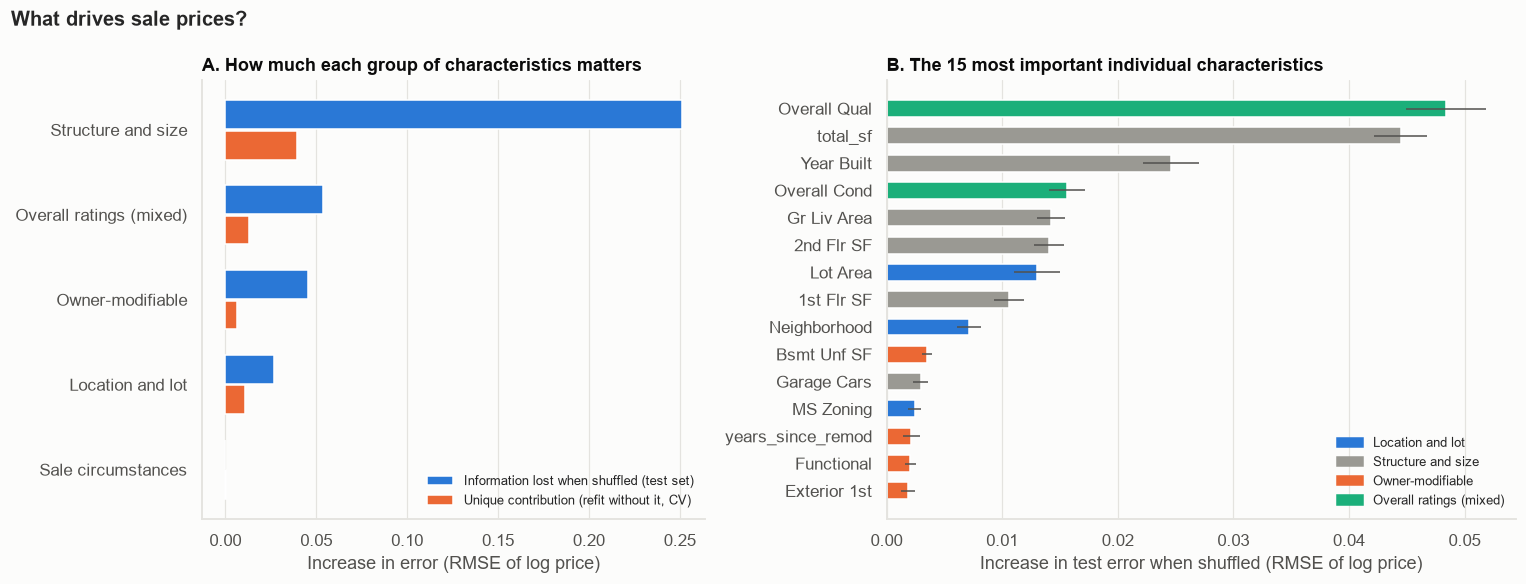

Most important owner-modifiable characteristics: Bsmt Unf SF, years_since_remod, Functional, Exterior 1st, Fireplaces, BsmtFin SF 1


In [64]:
TOP_N_DRIVERS = 15
perm = permutation_importance(FinalModel(), X_test_f, y_test_log, n_repeats=10, random_state=SEED,
                              scoring="neg_root_mean_squared_error")
driver_importance = pd.DataFrame({"importance": perm.importances_mean, "SD": perm.importances_std,
                                  "group": [GROUP_OF[v] for v in FEATURE_COLS]},
                                 index=pd.Index(FEATURE_COLS, name="variable")).sort_values("importance", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
gi = group_importance.sort_values("information lost when shuffled (test)")
y = np.arange(len(gi))
ax.barh(y + 0.18, gi["information lost when shuffled (test)"], height=0.34, color=COLORS["blue"],
        label="Information lost when shuffled (test set)")
ax.barh(y - 0.18, gi["unique contribution (CV)"], height=0.34, color=COLORS["orange"],
        label="Unique contribution (refit without it, CV)")
ax.set_yticks(y, labels=gi.index)
ax.set_xlabel("Increase in error (RMSE of log price)")
ax.set_title("A. How much each group of characteristics matters")
ax.legend(frameon=False, fontsize=8.5, loc="lower right")
ax.grid(axis="y", visible=False)
ax = axes[1]
top = driver_importance.head(TOP_N_DRIVERS).iloc[::-1]
ax.barh(top.index, top["importance"], xerr=top["SD"], color=[GROUP_COLORS[g] for g in top["group"]],
        height=0.62, error_kw={"ecolor": COLORS["text2"], "elinewidth": 1})
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for g, c in GROUP_COLORS.items() if g in set(top["group"])]
ax.legend(handles, [g for g in GROUP_COLORS if g in set(top["group"])], frameon=False, fontsize=8.5, loc="lower right")
ax.set_xlabel("Increase in test error when shuffled (RMSE of log price)")
ax.set_title(f"B. The {TOP_N_DRIVERS} most important individual characteristics")
ax.grid(axis="y", visible=False)
fig.suptitle("What drives sale prices?", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
save_fig(fig, "04_price_drivers")
plt.show()

print("Most important owner-modifiable characteristics:",
      ", ".join(driver_importance[driver_importance["group"] == "Owner-modifiable"].head(6).index))

**Reading.**
- **Overall quality and total floor area lead**, followed by age (`Year Built`), overall condition and the individual floor areas.
- **Location appears** through lot area and neighborhood.
- **The leading owner-modifiable variables** are unfinished basement area (which partly carries basement size), time since the last remodel, functional deductions (repairs), exterior covering and fireplaces (printed list). Each matters far less than size, quality or age.

<a id="s4-4"></a>

### 4.4 How much is location worth?

A regression of log price on the main characteristics of the house, plus one term per neighborhood, gives the **price difference for the same house in different neighborhoods**. The characteristics are living and basement area, lot size, overall quality and condition, age, bathrooms, garage capacity and new construction. The reference is NAmes, the neighborhood with the most sales. This regression has no penalty, so the neighborhood effects are not shrunk toward zero as they would be in a penalized model such as Ridge. Intervals use robust standard errors (HC1). Only neighborhoods with at least 15 sales are shown.

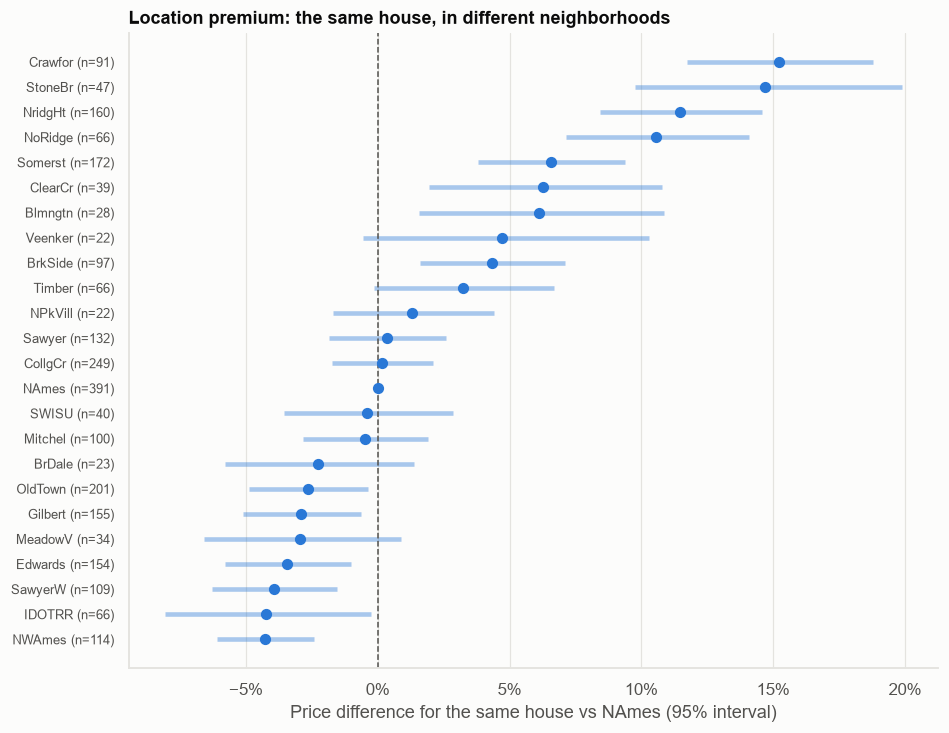

Regression R² = 0.927 on 2,599 sales
Same-house premium range: -4% to +15% vs NAmes | raw median prices of the same neighborhoods range 3.6x


In [65]:
import statsmodels.formula.api as smf

MIN_NEIGHBORHOOD_SALES = 15
REFERENCE_NEIGHBORHOOD = "NAmes"
loc_df = pd.DataFrame({
    "log_price": np.log(data_fe["SalePrice"]), "log_living": np.log(data_fe["Gr Liv Area"]),
    "bsmt_k": data_fe["Total Bsmt SF"] / 1000, "log_lot": np.log(data_fe["Lot Area"].astype(float)),
    "quality": data_fe["Overall Qual"], "condition": data_fe["Overall Cond"], "age": data_fe["house_age"],
    "baths": data_fe["total_baths"], "garage": data_fe["Garage Cars"], "new": data_fe["is_new_home"],
    "nbhd": data_fe["Neighborhood"]}).dropna()
loc_fit = smf.ols(f"log_price ~ C(nbhd, Treatment('{REFERENCE_NEIGHBORHOOD}')) + log_living + bsmt_k + log_lot + "
                  "quality + condition + age + baths + garage + new", loc_df).fit(cov_type="HC1")
terms = [t for t in loc_fit.params.index if t.startswith("C(nbhd")]
ci = loc_fit.conf_int().loc[terms]
location = pd.DataFrame({"premium (%)": 100 * np.expm1(loc_fit.params[terms]),
                         "95% low": 100 * np.expm1(ci[0]), "95% high": 100 * np.expm1(ci[1])})
location.index = [t.split("[T.")[1].rstrip("]") for t in terms]
location.loc[REFERENCE_NEIGHBORHOOD] = 0.0
sales_per_nbhd = loc_df["nbhd"].value_counts()
location["sales"] = sales_per_nbhd.reindex(location.index)
location = location[location["sales"] >= MIN_NEIGHBORHOOD_SALES].sort_values("premium (%)")
raw_median = data_fe.groupby("Neighborhood")["SalePrice"].median()

fig, ax = plt.subplots(figsize=(9.5, 7.5))
y = np.arange(len(location))
ax.hlines(y, location["95% low"], location["95% high"], color=COLORS["blue"], lw=3, alpha=0.4)
ax.scatter(location["premium (%)"], y, s=40, color=COLORS["blue"], zorder=3)
ax.axvline(0, color=COLORS["text2"], lw=1, ls="--")
ax.set_yticks(y, labels=[f"{n} (n={int(s)})" for n, s in zip(location.index, location["sales"])], fontsize=8.5)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel(f"Price difference for the same house vs {REFERENCE_NEIGHBORHOOD} (95% interval)")
ax.set_title("Location premium: the same house, in different neighborhoods")
ax.grid(axis="y", visible=False)
save_fig(fig, "04_location_premium")
plt.show()

shown = raw_median.reindex(location.index)
print(f"Regression R² = {loc_fit.rsquared:.3f} on {len(loc_df):,} sales")
print(f"Same-house premium range: {location['premium (%)'].min():+.0f}% to {location['premium (%)'].max():+.0f}% vs "
      f"{REFERENCE_NEIGHBORHOOD} | raw median prices of the same neighborhoods range "
      f"{shown.max() / shown.min():.1f}x")

**Reading.**
- **Location matters, but much less than raw prices suggest.** Raw median prices differ several-fold between these neighborhoods, but for the same house the difference shrinks to a much narrower range (both printed above). Most of the raw gap comes from the houses themselves: the expensive neighborhoods have newer, larger, better-built homes (see also Section 6).
- **A few neighborhoods carry a clear premium**, with intervals well above zero: Crawfor, StoneBr, NridgHt, NoRidge. Several carry a small discount, such as NWAmes, IDOTRR and Edwards.

**For brokers.** A neighborhood's name alone overstates what location is worth. Compare like with like.

<a id="s4-5"></a>

### 4.5 Key results

In [66]:
print("Key results - Section 4")
for g, r in group_importance.sort_values("information lost when shuffled (test)", ascending=False).iterrows():
    print(f"  {g} ({int(r['variables'])} variables): information share {r['share of information (%)']:.0f}%, "
          f"unique contribution {r['unique contribution (CV)']:+.4f} (SE {r['unique SE']:.4f})")
print("  Top 5 characteristics:", ", ".join(driver_importance.head(5).index))
print("  Top owner-modifiable:", ", ".join(driver_importance[driver_importance["group"] == "Owner-modifiable"].head(5).index))
print(f"  Location premium for the same house: {location['premium (%)'].min():+.0f}% to {location['premium (%)'].max():+.0f}% "
      f"vs {REFERENCE_NEIGHBORHOOD} ({len(location)} neighborhoods with >= {MIN_NEIGHBORHOOD_SALES} sales)")

Key results - Section 4
  Structure and size (24 variables): information share 67%, unique contribution +0.0396 (SE 0.0025)
  Overall ratings (mixed) (2 variables): information share 14%, unique contribution +0.0132 (SE 0.0015)
  Owner-modifiable (24 variables): information share 12%, unique contribution +0.0061 (SE 0.0010)
  Location and lot (8 variables): information share 7%, unique contribution +0.0105 (SE 0.0014)
  Sale circumstances (2 variables): information share -0%, unique contribution +0.0002 (SE 0.0002)
  Top 5 characteristics: Overall Qual, total_sf, Year Built, Overall Cond, Gr Liv Area
  Top owner-modifiable: Bsmt Unf SF, years_since_remod, Functional, Exterior 1st, Fireplaces
  Location premium for the same house: -4% to +15% vs NAmes (24 neighborhoods with >= 15 sales)


<a id="s4-decisions"></a>

### Decisions and rationale — Section 4

| Decision | Alternatives considered | Evidence and reason |
|---|---|---|
| Five groups with a written rule, each variable assigned exactly once (checked in code). `Bsmt Qual` (basement height) goes to structure. Overall ratings form their own group. | Three groups, with basement height and unfinished area counted as owner-modifiable (previous version) | The client asked for a modifiable vs structural/location split. A written rule makes the split defensible, and the dictionary defines `Bsmt Qual` as height. |
| Group importance is measured two ways: information lost when the group is shuffled (test set), and unique contribution when the model is refitted without it (cross-validation). | Shuffled share only (previous version) | Groups overlap. The two measures separate what a group tells the model from what only that group can tell it (4.2). |
| Individual importance by permutation on the test set, with its limitation stated. | Variable rankings without caveats | Correlated variables split the credit. The group view corrects for that. |
| Location premium from an unpenalized regression with a term per neighborhood and controls for the house. | Neighborhood coefficients from Ridge (previous version) | Ridge shrinks these effects toward zero, which understates location. The regression gives the same-house comparison with intervals (4.4). |
| Results are stated as associations; whether a change pays off is left to Q3. | Present importance as the effect of changing a characteristic | Importance does not show what a renovation would do to the price. |

<a id="s5"></a>

## 5. Q3 — Improvement return on investment

> **In brief.** *Question (Q3):* which improvements are a profitable investment? *Answer:* few improvements pay for themselves at resale, and low-cost fixes of clear deficiencies come closest. Each improvement's break-even cost, the most it can cost and still pay back, is the figure to use with owners. *Numbers:* [Key results](#s5-1). *Decisions:* [end of section](#s5-decisions).

**Client question.** *Among the characteristics that the owner can modify, which ones are a profitable investment? Which improvements are worth making relative to their cost?*

**Approach (agreed in the original plan).**
- **What-if simulation.** For every Normal resale that could receive an improvement, the final model of Section 3 prices the home twice: as it is, and with only that improvement changed. The difference is the **price uplift** the market data associates with the improvement.
- **Main result: the break-even cost.** An improvement pays for itself at resale only if it costs less than its uplift. The dataset has no renovation costs, so this result needs no external data.
- **Uncertainty.** The model is refitted 30 times on resampled training data, giving a range for each uplift.
- **Cost comparison (illustrative).** The uplifts are compared with cost ranges. These ranges are **unsourced assumptions** inherited from the first version of this notebook. They are collected in one table (`COST_ASSUMPTIONS`) so that Clearview can replace them with its contractors' quotes, and every verdict that depends on them says so.

**Scope.** Only Normal resales, because new homes include builder finishes, not owner choices. Bathroom additions are left out: adding a bathroom without adding floor area is not a realistic change, and the model cannot separate it from size.

**Caution.** The uplift is an association learned from past sales, holding the other characteristics fixed. It is not a controlled experiment. Homes with a feature can differ from homes without it in ways the data does not record.

In [67]:
# Illustrative cost assumptions (USD, low-high). UNSOURCED: replace with Clearview's contractor quotes.
COST_ASSUMPTIONS = {
    "Install central air": (3_500, 6_000),
    "Kitchen: typical -> good": (8_000, 18_000),
    "Kitchen: typical -> good, plus overall quality +1 (upper bound)": (10_000, 20_000),
    "Exterior material: typical -> good": (6_000, 14_000),
    "Heating: typical -> excellent": (3_500, 6_500),
    "Add a fireplace": (3_500, 7_500),
    "Finish 500 sqft of basement": (12_000, 22_000),
    "Add a 200 sqft wood deck": (4_500, 9_000),
    "Finish the garage interior": (2_000, 4_500),
    "Pave the driveway": (3_000, 6_000),
    "Add a privacy fence": (3_000, 6_500),
}
SCENARIOS = {   # name: (which homes are eligible, how the improvement changes them)
    "Install central air": (lambda d: d["Central Air"] == "N", lambda d: d.assign(**{"Central Air": "Y"})),
    "Kitchen: typical -> good": (lambda d: d["Kitchen Qual"] == "TA", lambda d: d.assign(**{"Kitchen Qual": "Gd"})),
    "Kitchen: typical -> good, plus overall quality +1 (upper bound)": (
        lambda d: (d["Kitchen Qual"] == "TA") & d["Overall Qual"].between(4, 7),
        lambda d: d.assign(**{"Kitchen Qual": "Gd", "Overall Qual": d["Overall Qual"] + 1, "years_since_remod": 0})),
    "Exterior material: typical -> good": (lambda d: d["Exter Qual"] == "TA", lambda d: d.assign(**{"Exter Qual": "Gd"})),
    "Heating: typical -> excellent": (lambda d: d["Heating QC"] == "TA", lambda d: d.assign(**{"Heating QC": "Ex"})),
    "Add a fireplace": (lambda d: d["Fireplaces"] == 0, lambda d: d.assign(**{"Fireplaces": 1, "Fireplace Qu": "Gd"})),
    "Finish 500 sqft of basement": (
        lambda d: (d["BsmtFin Type 1"] == "Unf") & (d["Bsmt Unf SF"] >= 500),
        lambda d: d.assign(**{"BsmtFin Type 1": "GLQ", "BsmtFin SF 1": d["BsmtFin SF 1"] + 500,
                              "Bsmt Unf SF": d["Bsmt Unf SF"] - 500})),
    "Add a 200 sqft wood deck": (lambda d: d["Wood Deck SF"] == 0,
                                 lambda d: d.assign(**{"Wood Deck SF": 200, "porch_sf": d["porch_sf"] + 200})),
    "Finish the garage interior": (lambda d: d["Garage Finish"] == "Unf", lambda d: d.assign(**{"Garage Finish": "Fin"})),
    "Pave the driveway": (lambda d: d["Paved Drive"] == "N", lambda d: d.assign(**{"Paved Drive": "Y"})),
    "Add a privacy fence": (lambda d: d["Fence"] == "Absent", lambda d: d.assign(**{"Fence": "GdPrv"})),
}
assert set(SCENARIOS) == set(COST_ASSUMPTIONS)
changed = set()
for elig, mod in SCENARIOS.values():
    eligible_homes = data_fe[elig(data_fe)]
    improved = mod(eligible_homes.copy())
    changed |= {c for c in improved.columns if not improved[c].equals(eligible_homes[c])}
print("Variables changed by the scenarios:", sorted(changed))
print("  of which not used by the model (their change has no effect):", sorted(changed - set(FEATURE_COLS)) or "none")
variables_table({c: "Changed by an improvement scenario" for c in sorted(changed)})

Variables changed by the scenarios: ['Bsmt Unf SF', 'BsmtFin SF 1', 'BsmtFin Type 1', 'Central Air', 'Exter Qual', 'Fence', 'Fireplace Qu', 'Fireplaces', 'Garage Finish', 'Heating QC', 'Kitchen Qual', 'Overall Qual', 'Paved Drive', 'Wood Deck SF', 'porch_sf', 'years_since_remod']
  of which not used by the model (their change has no effect): none


,Source,Meaning,Codes / formula,Role in this section
Variable,,,,
Bsmt Unf SF,Data dictionary,Unfinished square feet of basement area (numeric).; dictionary note: NaN = no basement,numeric,Changed by an improvement scenario
BsmtFin SF 1,Data dictionary,Type 1 finished square feet (numeric).; dictionary note: NaN = no basement,numeric,Changed by an improvement scenario
BsmtFin Type 1,Data dictionary,Rating of basement finished area (primary); NaN = no basement,ALQ = Average Living Quarters; BLQ = Below Average Living Quarters; GLQ = Good Living Quarters; LwQ = Low Quality; Rec = Average Rec Room; Unf = Unfinished,Changed by an improvement scenario
Central Air,Data dictionary,Central air conditioning,N = No; Y = Yes,Changed by an improvement scenario
Exter Qual,Data dictionary,Quality of the material on the exterior,Ex = Excellent; Fa = Fair; Gd = Good; TA = Average / Typical,Changed by an improvement scenario
Fence,Data dictionary,Fence quality; NaN = no fence,GdPrv = Good Privacy; GdWo = Good Wood; MnPrv = Minimum Privacy; MnWw = Minimum Wood/Wire,Changed by an improvement scenario
Fireplace Qu,Data dictionary,Fireplace quality; NaN = no fireplace,Ex = Excellent; Fa = Fair; Gd = Good; Po = Poor; TA = Average / Typical,Changed by an improvement scenario
Fireplaces,Data dictionary,Number of fireplaces (integer).,numeric,Changed by an improvement scenario
Garage Finish,Data dictionary,Interior finish of the garage; NaN = no garage,Fin = Finished; RFn = Rough Finished; Unf = Unfinished,Changed by an improvement scenario


In [68]:
N_REFITS = 30
normal_sales = data_fe[data_fe["Sale Condition"] == "Normal"]
before_after = {name: (normal_sales[elig(normal_sales)], mod(normal_sales[elig(normal_sales)].copy()))
                for name, (elig, mod) in SCENARIOS.items()}


def uplift_usd(predict_log, before, after):
    """Predicted price change per home (USD) when only the improvement changes."""
    return np.exp(predict_log(after)) - np.exp(predict_log(before))


# Point estimate with the final model, and a Ridge-only check (model agreement)
point = {n: uplift_usd(final_predict_log, b, a) for n, (b, a) in before_after.items()}
ridge_check = {n: np.median(uplift_usd(lambda X: final_models["Ridge"].predict(X[FEATURE_COLS]), b, a))
               for n, (b, a) in before_after.items()}

# Uncertainty: refit the final model on resampled training data
rng = rng_for("5 refits")
refit_medians = {n: [] for n in SCENARIOS}
for _ in range(N_REFITS):
    rows = rng.choice(len(train_df), len(train_df), replace=True)
    Xb, yb = train_df.iloc[rows][FEATURE_COLS], y_train_log[rows]
    models_b = {n: CANDIDATE_MODELS[n][0](best_params[n]).fit(Xb, yb) for n in FINAL_WEIGHTS}
    predict_b = lambda X: sum(w * models_b[n].predict(X[FEATURE_COLS]) for n, w in FINAL_WEIGHTS.items())
    for n, (b, a) in before_after.items():
        refit_medians[n].append(np.median(uplift_usd(predict_b, b, a)))

roi_rows = []
for n, (b, a) in before_after.items():
    up = point[n]
    lo, hi = np.percentile(refit_medians[n], [2.5, 97.5])
    c_lo, c_hi = COST_ASSUMPTIONS[n]
    verdict = ("pays for itself" if lo >= c_hi else "does not pay back at resale" if hi < c_lo
               else "depends on the actual cost")
    roi_rows.append({"improvement": n, "eligible homes": len(b),
                     "uplift = break-even cost ($)": np.median(up), "range low ($)": lo, "range high ($)": hi,
                     "uplift (% of price)": 100 * np.median(up / np.exp(final_predict_log(b))),
                     "Ridge-only check ($)": ridge_check[n],
                     "assumed cost low ($)": c_lo, "assumed cost high ($)": c_hi,
                     "share of mid cost recovered (%)": 100 * np.median(up) / ((c_lo + c_hi) / 2),
                     "verdict vs assumed cost": verdict})
roi = pd.DataFrame(roi_rows).set_index("improvement").sort_values("uplift = break-even cost ($)", ascending=False)

# Does the uplift differ by price tier (Section 3.4)? Median uplift in % of the home's price
tier_rows = []
for n, (b, a) in before_after.items():
    pct = 100 * point[n] / np.exp(final_predict_log(b))
    tiers = tier_of(final_predict_log(b))
    tier_rows.append({"improvement": n, **{t: np.median(pct[tiers == t]) if (tiers == t).sum() >= 20 else np.nan
                                           for t in TIER_NAMES}})
uplift_by_tier = pd.DataFrame(tier_rows).set_index("improvement").loc[roi.index]
with pd.option_context("display.max_colwidth", None):
    display(roi.round(0))
print("Median uplift in % of the home's price, by predicted price tier (blank: fewer than 20 eligible homes):")
uplift_by_tier.round(1)

,eligible homes,uplift = break-even cost ($),range low ($),range high ($),uplift (% of price),Ridge-only check ($),assumed cost low ($),assumed cost high ($),share of mid cost recovered (%),verdict vs assumed cost
improvement,,,,,,,,,,
"Kitchen: typical -> good, plus overall quality +1 (upper bound)",1245,13025.0,11577.0,14757.0,10.0,12850.0,10000,20000,87.0,depends on the actual cost
Finish 500 sqft of basement,595,7360.0,6309.0,9397.0,5.0,7467.0,12000,22000,43.0,does not pay back at resale
Install central air,152,5120.0,3086.0,7540.0,5.0,4839.0,3500,6000,108.0,depends on the actual cost
Add a fireplace,1152,3616.0,2402.0,4353.0,3.0,3921.0,3500,7500,66.0,depends on the actual cost
Exterior material: typical -> good,1548,3076.0,1633.0,4129.0,2.0,3150.0,6000,14000,31.0,does not pay back at resale
Kitchen: typical -> good,1283,2319.0,1329.0,3271.0,2.0,2400.0,8000,18000,18.0,does not pay back at resale
Heating: typical -> excellent,721,2182.0,1524.0,3407.0,2.0,2528.0,3500,6500,44.0,does not pay back at resale
Pave the driveway,178,1962.0,975.0,3653.0,2.0,2756.0,3000,6000,44.0,depends on the actual cost
Add a 200 sqft wood deck,1245,1523.0,722.0,2300.0,1.0,986.0,4500,9000,23.0,does not pay back at resale


Median uplift in % of the home's price, by predicted price tier (blank: fewer than 20 eligible homes):


,Starter,Mid-market,Upper
improvement,,,
"Kitchen: typical -> good, plus overall quality +1 (upper bound)",9.7,9.3,10.9
Finish 500 sqft of basement,5.4,4.5,4.3
Install central air,5.5,NaN,NaN
Add a fireplace,2.6,2.7,2.4
Exterior material: typical -> good,2.4,2.2,2.6
Kitchen: typical -> good,1.9,1.7,2.7
Heating: typical -> excellent,1.7,1.4,1.3
Pave the driveway,1.8,NaN,NaN
Add a 200 sqft wood deck,1.4,0.9,0.6


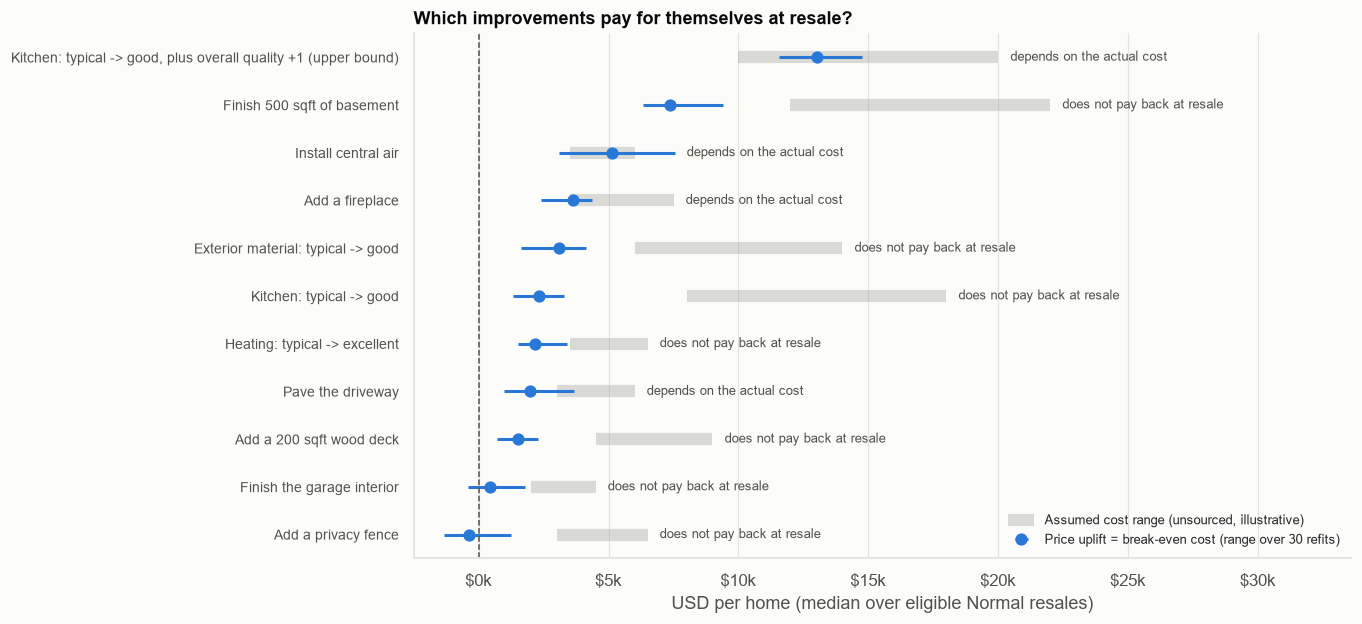

In [69]:
plot_r = roi.iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 6.2))
y = np.arange(len(plot_r))
ax.hlines(y, plot_r["assumed cost low ($)"], plot_r["assumed cost high ($)"], color=COLORS["gray"], lw=8, alpha=0.35,
          label="Assumed cost range (unsourced, illustrative)")
ax.errorbar(plot_r["uplift = break-even cost ($)"], y,
            xerr=[plot_r["uplift = break-even cost ($)"] - plot_r["range low ($)"],
                  plot_r["range high ($)"] - plot_r["uplift = break-even cost ($)"]],
            fmt="o", ms=7, color=COLORS["blue"], elinewidth=2, capsize=0, label="Price uplift = break-even cost (range over 30 refits)")
for yi, (_, r) in zip(y, plot_r.iterrows()):
    ax.annotate(r["verdict vs assumed cost"], (max(r["range high ($)"], r["assumed cost high ($)"]), yi), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=8.5, color=COLORS["text2"])
ax.axvline(0, color=COLORS["text2"], lw=1, ls="--")
ax.set_yticks(y, labels=plot_r.index, fontsize=9)
ax.xaxis.set_major_formatter(USD)
ax.set_xlim(right=ax.get_xlim()[1] * 1.45)
ax.set_xlabel("USD per home (median over eligible Normal resales)")
ax.set_title("Which improvements pay for themselves at resale?")
ax.legend(frameon=False, fontsize=8.5, loc="lower right")
ax.grid(axis="y", visible=False)
save_fig(fig, "05_improvement_break_even")
plt.show()

**Reading.**
- **Under the assumed costs, no improvement clearly pays for itself at resale.** Even the most favorable cases break even only if they can be done at the low end of the cost range.
- **Closest to break-even:** installing central air where it is missing, adding a fireplace, and paving a gravel driveway. Their uplift range overlaps the assumed cost range. Missing central air and gravel driveways occur almost only in starter homes (tier table).
- **Kitchens depend on what the renovation changes.** Raising the kitchen rating alone goes with a small uplift, far below the assumed cost. The large uplift appears only if the renovation also raises the home's *overall* quality rating by a full point. The data cannot confirm that assumption, so that row is an upper bound.
- **Clearly not paying back at the assumed costs:**
  - finishing the basement (a sizeable uplift, but a higher assumed cost);
  - exterior and heating upgrades;
  - a deck;
  - finishing the garage;
  - a fence, which shows no detectable uplift.
- **The conclusions do not hinge on the blend.** The Ridge-only check gives similar uplifts for the larger improvements (table).
- **Uplifts are a similar share of the price across tiers** (tier table), so in dollars they are larger for pricier homes.

**For brokers.** At these costs, renovations are rarely recovered in full at resale. Low-cost fixes of clear deficiencies, such as missing central air or a gravel driveway, come closest. Do not promise owners that a renovation will pay for itself. Before quoting returns to clients, replace the cost assumptions with real contractor quotes; the break-even column remains valid whatever the costs turn out to be.

<a id="s5-1"></a>

### 5.1 Key results

In [70]:
print("Key results - Section 5 (uplift = break-even cost; verdicts depend on UNSOURCED cost assumptions)")
for n, r in roi.iterrows():
    print(f"  {n}: ${r['uplift = break-even cost ($)']:,.0f} (range ${r['range low ($)']:,.0f} to "
          f"${r['range high ($)']:,.0f}; {r['uplift (% of price)']:.1f}% of price) -> {r['verdict vs assumed cost']}")

Key results - Section 5 (uplift = break-even cost; verdicts depend on UNSOURCED cost assumptions)
  Kitchen: typical -> good, plus overall quality +1 (upper bound): $13,025 (range $11,577 to $14,757; 9.7% of price) -> depends on the actual cost
  Finish 500 sqft of basement: $7,360 (range $6,309 to $9,397; 4.7% of price) -> does not pay back at resale
  Install central air: $5,120 (range $3,086 to $7,540; 5.5% of price) -> depends on the actual cost
  Add a fireplace: $3,616 (range $2,402 to $4,353; 2.6% of price) -> depends on the actual cost
  Exterior material: typical -> good: $3,076 (range $1,633 to $4,129; 2.3% of price) -> does not pay back at resale
  Kitchen: typical -> good: $2,319 (range $1,329 to $3,271; 1.9% of price) -> does not pay back at resale
  Heating: typical -> excellent: $2,182 (range $1,524 to $3,407; 1.6% of price) -> does not pay back at resale
  Pave the driveway: $1,962 (range $975 to $3,653; 1.8% of price) -> depends on the actual cost
  Add a 200 sqft wood

<a id="s5-decisions"></a>

### Decisions and rationale — Section 5

| Decision | Alternatives considered | Evidence and reason |
|---|---|---|
| The main result is the **break-even cost** (the price uplift), which needs no external data. | Recovery percentages based on cost assumptions (previous version) | Agreed in the original plan. The dataset has no costs, and the break-even stays valid whatever the costs are. |
| Cost ranges are kept as **unsourced, illustrative assumptions** in one editable table, and the verdicts state that they depend on them. | Present the ranges as benchmarks (previous version) | No source was given for these figures. Clearview's contractor quotes should replace them. |
| Uncertainty comes from 30 refits of the final model on resampled training data, and verdicts require the whole range to clear or miss the cost range. | A single point estimate per improvement | A verdict should not rest on one model fit. |
| The "+1 overall quality" kitchen scenario is labeled an **upper bound**, next to the kitchen-only scenario. | Treat the bundle as the expected effect (previous version) | Whether a light renovation raises the overall rating by a full point is an assumption the data cannot check, and it drives most of the bundle's uplift. |
| Bathroom additions without extra floor area are removed. | Keep them | Not a realistic change, and the model cannot separate it from size. |
| Normal resales only, with a Ridge-only check and a breakdown by price tier. | All sales; a single model | New homes include builder finishes, not owner choices. The check and the breakdown show the conclusions are robust. |

<a id="s6"></a>

## 6. Q4 — Market segmentation

> **In brief.** *Question (Q4):* are there market segments that behave differently? *Answer:* yes. The market splits into two halves, older and smaller vs newer and larger homes, located in largely different neighborhoods. Quality is worth more in the newer half, and one price model serves both. *Numbers:* [Key results](#s6-5). *Decisions:* [end of section](#s6-decisions).

**Client question.** *Is there a clear pattern or market segmentation worth knowing about? For example, segments of properties that behave differently from the rest.*

**Approach.**
- **6.1** Group homes by their **physical characteristics only**: size, lot, age, quality, condition, bathrooms, garage. Price, location and new-home status are *not* used. Including them would build the answer into the groups, so we use them afterwards to describe the segments. The number of segments follows a rule fixed in advance.
- **6.2** Describe the segments: who is in each, at what prices, in which neighborhoods.
- **6.3** Test whether the segments **behave differently**: do size, quality and age move prices by different amounts in each segment?
- **6.4** Test whether the price model of Section 3 works equally well in each segment, and whether separate models per segment would do better.

The segmentation uses all 2,629 sales in the analysis sample. It never sees prices, so no test-set information can leak into it.

In [71]:
define_variable(
    "market_segment", "Market segment of a home, from k-means clustering of its physical characteristics",
    "k-means on the standardized clustering inputs below (living and lot area on a log scale); "
    "number of segments chosen by the rule in 6.1",
    "Section 6: answers Q4. The segments are then compared on price, price drivers and model accuracy.")

SEGMENT_FEATURES = ["Gr Liv Area", "Total Bsmt SF", "Lot Area", "house_age", "Overall Qual", "Overall Cond",
                    "total_baths", "Garage Cars"]
LOG_SEGMENT_FEATURES = ["Gr Liv Area", "Lot Area"]   # skewed sizes; basement area stays on its natural scale (6.1)
variables_table({c: "Clustering input" for c in SEGMENT_FEATURES}
                | {"SalePrice": "Compares the segments afterwards (not a clustering input)",
                   "Neighborhood": "Describes the segments afterwards (not a clustering input)",
                   "is_new_home": "Describes the segments afterwards (not a clustering input)",
                   "market_segment": None})

,Source,Meaning,Codes / formula,Role in this section
Variable,,,,
Gr Liv Area,Data dictionary,Above-grade (ground) living area square feet (numeric).,numeric,Clustering input
Total Bsmt SF,Data dictionary,Total square feet of basement area (numeric).; dictionary note: NaN = no basement,numeric,Clustering input
Lot Area,Data dictionary,Lot size in square feet (numeric).,numeric,Clustering input
house_age,Computed,Age of the house when it was sold (years),Yr Sold - Year Built,Clustering input
Overall Qual,Data dictionary,Rates the overall material and finish of the house.; Integer from 1 (Very Poor) to 10 (Very Excellent).,numeric,Clustering input
Overall Cond,Data dictionary,Rates the overall condition of the house.; Integer from 1 (Very Poor) to 10 (Very Excellent).,numeric,Clustering input
total_baths,Computed,"All bathrooms, half baths counted as one half",Full Bath + 0.5 Half Bath + Bsmt Full Bath + 0.5 Bsmt Half Bath,Clustering input
Garage Cars,Data dictionary,Size of garage in car capacity (integer).; dictionary note: NaN = no garage,numeric,Clustering input
SalePrice,Data dictionary,Sale price of the property in US dollars (numeric).,numeric,Compares the segments afterwards (not a clustering input)


<a id="s6-1"></a>

### 6.1 How many segments?

**Method.** K-means splits homes into *k* groups of similar characteristics. The inputs are standardized, so that every characteristic counts equally. Living area and lot area are put on a log scale because a few very large homes would otherwise dominate. Basement area stays on its natural scale: on a log scale, the homes without a basement (area 0) sit far from all others and form an artificial "group" defined by a single measurement, not a market segment.

**Rule for k, fixed in advance.** For k = 2 to 6:
- **Separation:** the silhouette score, from −1 to 1. It measures how much closer homes are to their own segment than to the next one. Above about 0.5 the segments are clearly distinct; between 0.25 and 0.5 the structure is real but the segments overlap.
- **Stability:** the data is resampled 20 times and k-means rerun each time. The adjusted Rand index (ARI) measures how well the new grouping agrees with the original (1 = identical).
- **Usefulness:** the smallest segment must hold at least 5% of sales.

Among the stable (mean ARI ≥ 0.80) and useful values of k, the one with the highest silhouette is chosen.

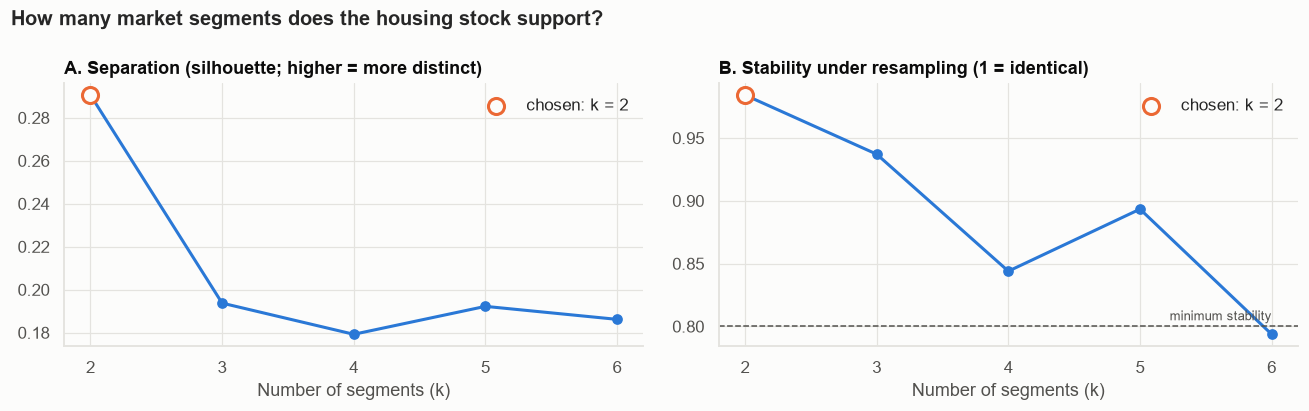

Chosen number of segments: 2


,silhouette,stability (mean ARI),stability (lowest ARI),smallest segment (share of sales)
k,,,,
2,0.291,0.984,0.962,0.497
3,0.194,0.937,0.845,0.187
4,0.179,0.844,0.581,0.188
5,0.192,0.893,0.556,0.086
6,0.186,0.794,0.597,0.079


In [72]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score

K_RANGE = range(2, 7)
N_STABILITY_RESAMPLES = 20
MIN_STABILITY, MIN_SEGMENT_SHARE = 0.80, 0.05

seg_inputs = data_fe[SEGMENT_FEATURES].copy()
seg_inputs = seg_inputs.fillna(seg_inputs.median())
for c in LOG_SEGMENT_FEATURES:
    seg_inputs[c] = np.log1p(seg_inputs[c])
Z_seg = StandardScaler().fit_transform(seg_inputs)

k_rows, labels_by_k = [], {}
for k in K_RANGE:
    labels = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(Z_seg)
    labels_by_k[k] = labels
    rng = rng_for(f"6.1 stability k={k}")
    agreement = []
    for _ in range(N_STABILITY_RESAMPLES):
        rows = rng.choice(len(Z_seg), len(Z_seg), replace=True)
        refit = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z_seg[rows])
        agreement.append(adjusted_rand_score(labels, refit.predict(Z_seg)))
    k_rows.append({"k": k, "silhouette": silhouette_score(Z_seg, labels),
                   "stability (mean ARI)": np.mean(agreement), "stability (lowest ARI)": np.min(agreement),
                   "smallest segment (share of sales)": np.bincount(labels).min() / len(labels)})
k_table = pd.DataFrame(k_rows).set_index("k")
eligible = k_table[(k_table["stability (mean ARI)"] >= MIN_STABILITY)
                   & (k_table["smallest segment (share of sales)"] >= MIN_SEGMENT_SHARE)]
K_SEGMENTS = int(eligible["silhouette"].idxmax())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col, threshold, title in [
        (axes[0], "silhouette", None, "A. Separation (silhouette; higher = more distinct)"),
        (axes[1], "stability (mean ARI)", MIN_STABILITY, "B. Stability under resampling (1 = identical)")]:
    ax.plot(k_table.index, k_table[col], marker="o", lw=2, color=COLORS["blue"])
    ax.scatter([K_SEGMENTS], [k_table.loc[K_SEGMENTS, col]], s=110, facecolor=COLORS["surface"],
               edgecolor=COLORS["orange"], linewidth=2, zorder=4, label=f"chosen: k = {K_SEGMENTS}")
    if threshold is not None:
        ax.axhline(threshold, color=COLORS["text2"], lw=1, ls="--")
        ax.annotate("minimum stability", (K_RANGE[-1], threshold), xytext=(0, 4), textcoords="offset points",
                    ha="right", fontsize=8.5, color=COLORS["text2"])
    ax.set_xticks(list(K_RANGE))
    ax.set_xlabel("Number of segments (k)")
    ax.set_title(title)
    ax.legend(frameon=False, loc="upper right")
fig.suptitle("How many market segments does the housing stock support?", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
save_fig(fig, "06_segment_count")
plt.show()
print(f"Chosen number of segments: {K_SEGMENTS}")
k_table.round(3)

**Reading.** The rule picks **two segments**. This split is almost perfectly stable under resampling and the most separated of all. The separation is moderate (silhouette between 0.25 and 0.5): homes form a continuum from older, smaller, plainer houses to newer, larger, higher-quality ones, and the two segments are its two halves rather than sharply distinct groups. Three segments are also stable but clearly less separated (table).

<a id="s6-2"></a>

### 6.2 Who is in each segment?

The segments are named from their profile, ordered by median price. The name is assigned in code only if the profile supports it: the cheaper segment must also be older *and* smaller. Otherwise neutral names (Segment 1, 2, ...) are used.

In [73]:
raw_labels = labels_by_k[K_SEGMENTS]
by_label = pd.DataFrame({"label": raw_labels, "price": data_fe["SalePrice"].to_numpy(),
                         "year": data_fe["Year Built"].to_numpy(), "area": data_fe["Gr Liv Area"].to_numpy()})
med = by_label.groupby("label").median().sort_values("price")
names = [f"Segment {i + 1}" for i in range(K_SEGMENTS)]
if K_SEGMENTS == 2 and med["year"].is_monotonic_increasing and med["area"].is_monotonic_increasing:
    names = ["Older, smaller homes", "Newer, larger homes"]
SEGMENT_NAMES = dict(zip(med.index, names))
SEGMENTS = names
data_fe["market_segment"] = pd.Series(raw_labels, index=data_fe.index).map(SEGMENT_NAMES)

g = data_fe.groupby("market_segment")
profile = pd.DataFrame({
    "sales": g.size(),
    "share of sales (%)": 100 * g.size() / len(data_fe),
    "median price ($)": g["SalePrice"].median(),
    "median price per sqft ($)": g.apply(lambda d: (d["SalePrice"] / d["Gr Liv Area"]).median(), include_groups=False),
    "median living area (sqft)": g["Gr Liv Area"].median(),
    "median basement area (sqft)": g["Total Bsmt SF"].median(),
    "median lot area (sqft)": g["Lot Area"].median(),
    "median year built": g["Year Built"].median(),
    "mean overall quality (1-10)": g["Overall Qual"].mean(),
    "mean overall condition (1-10)": g["Overall Cond"].mean(),
    "mean bathrooms": g["total_baths"].mean(),
    "median garage (cars)": g["Garage Cars"].median(),
    "new homes (%)": 100 * g["is_new_home"].mean(),
}).loc[SEGMENTS].T
display(profile.round(1))

TOP_NEIGHBORHOODS = 6
mix = pd.crosstab(data_fe["Neighborhood"], data_fe["market_segment"])[SEGMENTS]
top = {s: (mix[s].sort_values(ascending=False).head(TOP_NEIGHBORHOODS) / mix[s].sum() * 100).round(0)
       for s in SEGMENTS}
print("Largest neighborhoods in each segment (% of the segment's sales):")
for s in SEGMENTS:
    print(f"  {s}: " + ", ".join(f"{n} {v:.0f}%" for n, v in top[s].items()))
mostly = (mix.div(mix.sum(axis=1), axis=0) >= 0.9) & (mix.sum(axis=1).to_numpy()[:, None] >= 20)
print("Neighborhoods (20+ sales) with at least 90% of their sales in one segment: "
      + "; ".join(f"{s}: {', '.join(mostly.index[mostly[s]])}" for s in SEGMENTS if mostly[s].any()))

market_segment,"Older, smaller homes","Newer, larger homes"
sales,1307,1322
share of sales (%),49.71472,50.28528
median price ($),132500.0,214000.0
median price per sqft ($),111.851332,129.388949
median living area (sqft),1145.0,1674.5
median basement area (sqft),864.0,1273.5
median lot area (sqft),8546.0,10381.0
median year built,1956.0,2001.0
mean overall quality (1-10),5.196634,7.096067
mean overall condition (1-10),6.005356,5.186082


Largest neighborhoods in each segment (% of the segment's sales):
  Older, smaller homes: NAmes 25%, OldTown 15%, Edwards 10%, Sawyer 9%, BrkSide 7%, IDOTRR 5%
  Newer, larger homes: CollgCr 14%, Somerst 13%, NridgHt 12%, Gilbert 11%, NWAmes 7%, SawyerW 6%
Neighborhoods (20+ sales) with at least 90% of their sales in one segment: Older, smaller homes: BrDale, BrkSide, IDOTRR, MeadowV, OldTown, SWISU; Newer, larger homes: Blmngtn, Gilbert, NoRidge, NridgHt, Somerst, StoneBr, Timber, Veenker


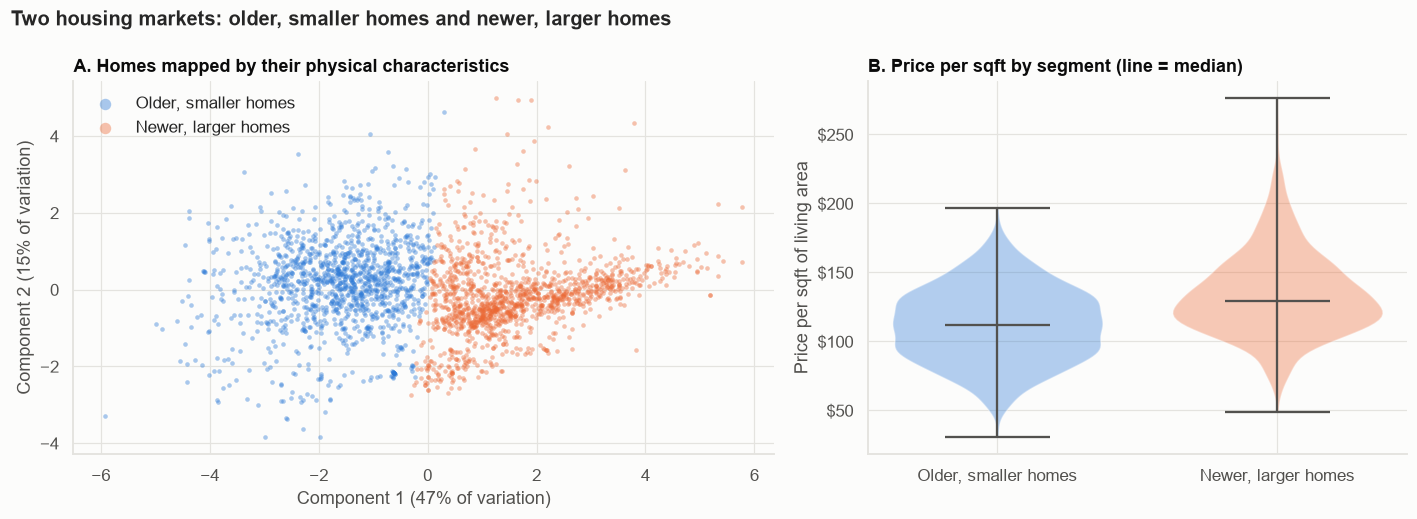

In [74]:
pca = PCA(n_components=2, random_state=SEED)
pcs = pca.fit_transform(Z_seg)
seg_colors = dict(zip(SEGMENTS, [COLORS["blue"], COLORS["orange"], COLORS["aqua"]] + [COLORS["gray"]] * 5))
ppsf_all = data_fe["SalePrice"] / data_fe["Gr Liv Area"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
for s in SEGMENTS:
    m = (data_fe["market_segment"] == s).to_numpy()
    ax.scatter(pcs[m, 0], pcs[m, 1], s=9, alpha=0.4, color=seg_colors[s], linewidths=0, label=s)
ax.set_xlabel(f"Component 1 ({pca.explained_variance_ratio_[0]:.0%} of variation)")
ax.set_ylabel(f"Component 2 ({pca.explained_variance_ratio_[1]:.0%} of variation)")
ax.set_title("A. Homes mapped by their physical characteristics")
ax.legend(frameon=False, markerscale=2.5, loc="best")
ax = axes[1]
parts = ax.violinplot([ppsf_all[data_fe["market_segment"] == s] for s in SEGMENTS], showmedians=True, widths=0.75)
for body, s in zip(parts["bodies"], SEGMENTS):
    body.set_facecolor(seg_colors[s])
    body.set_alpha(0.35)
for key in ["cmedians", "cmins", "cmaxes", "cbars"]:
    parts[key].set_color(COLORS["text2"])
ax.set_xticks(range(1, len(SEGMENTS) + 1), labels=SEGMENTS)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("${x:,.0f}"))
ax.set_ylabel("Price per sqft of living area")
ax.set_title("B. Price per sqft by segment (line = median)")
fig.suptitle("Two housing markets: older, smaller homes and newer, larger homes" if K_SEGMENTS == 2
             else "Market segments by physical characteristics", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
save_fig(fig, "06_segment_profile")
plt.show()

**Reading.**
- **Two halves of the market, of similar size.**
  - *Older, smaller homes:* built around mid-century, with plainer finishes (lower overall quality) but rated in better condition, and with smaller lots and garages.
  - *Newer, larger homes:* recent, higher quality, with more bathrooms and garage space (table).
- **Newer homes cost more per square foot, not only in total** (panel B): the price difference is not explained by size alone.
- **Location follows the housing stock.** Most neighborhoods sell almost exclusively one type of home (printed list), so the segments are also a geographic pattern, even though location was not used to build them.
- **New construction is not a segment of its own.** Nearly all new homes fall within the newer, larger segment (new-home share in the table).

<a id="s6-3"></a>

### 6.3 Do the segments behave differently?

**Question.** Do the same characteristics move prices by the same amount in both segments? For example, is one more point of overall quality worth more in newer homes than in older ones?

**Method.** In each segment, a regression of log price on the main physical drivers, with a separate price level for each neighborhood, so that location does not blur the comparison. The coefficients are converted into the price change a broker would quote:
- +10% living area;
- +1 point of overall quality or overall condition (1–10 scales);
- 10 more years of age;
- one more bathroom;
- one more garage space.

The intervals use robust standard errors (HC1). A joint F-test then checks whether the drivers' effects differ between segments overall, comparing a model where every effect may differ by segment with one where they are shared. These are associations, not proof that changing a characteristic would change the price. That question belongs to Q3.

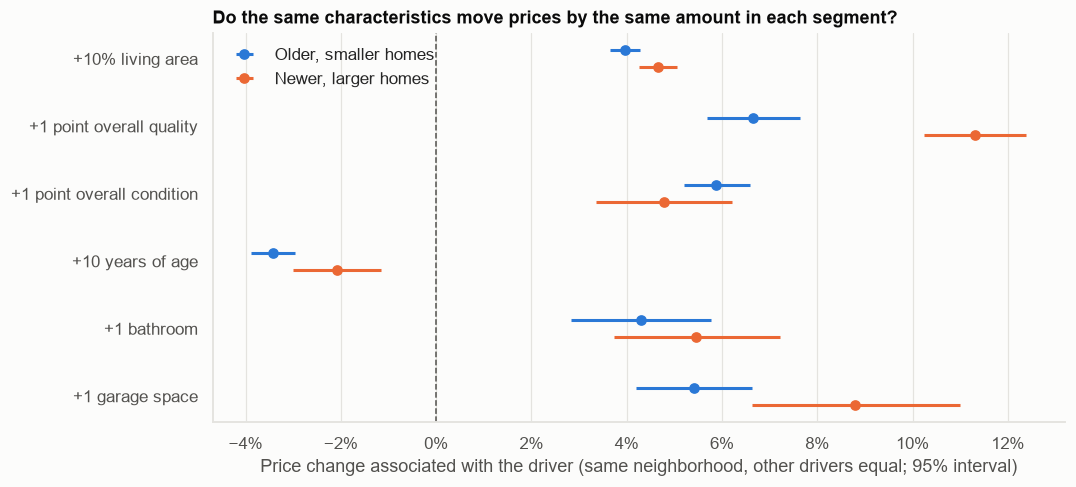

Joint test that all driver effects are equal across segments: F = 19.7 on 6 restrictions, p = 1.2e-22


segment,"Older, smaller homes","Newer, larger homes"
driver,,
+10% living area,4.0,4.7
+1 point overall quality,6.6,11.3
+1 point overall condition,5.9,4.8
+10 years of age,-3.4,-2.1
+1 bathroom,4.3,5.5
+1 garage space,5.4,8.8


In [75]:
import statsmodels.formula.api as smf

DRIVERS = {   # coefficient name: (label, function turning the log-price coefficient into a % price change)
    "log_living": ("+10% living area", lambda b: 100 * (1.1 ** b - 1)),
    "quality": ("+1 point overall quality", lambda b: 100 * np.expm1(b)),
    "condition": ("+1 point overall condition", lambda b: 100 * np.expm1(b)),
    "age": ("+10 years of age", lambda b: 100 * np.expm1(10 * b)),
    "baths": ("+1 bathroom", lambda b: 100 * np.expm1(b)),
    "garage": ("+1 garage space", lambda b: 100 * np.expm1(b)),
}
reg_df = pd.DataFrame({
    "log_price": np.log(data_fe["SalePrice"]), "log_living": np.log(data_fe["Gr Liv Area"]),
    "quality": data_fe["Overall Qual"], "condition": data_fe["Overall Cond"], "age": data_fe["house_age"],
    "baths": data_fe["total_baths"], "garage": data_fe["Garage Cars"], "nbhd": data_fe["Neighborhood"],
    "seg": data_fe["market_segment"].map({s: f"S{i}" for i, s in enumerate(SEGMENTS)}),
}).dropna()
reg_df["seg_nbhd"] = reg_df["seg"] + "_" + reg_df["nbhd"]   # neighborhood levels within each segment (only existing pairs)
rhs = " + ".join(DRIVERS)

effect_rows = []
for i, s in enumerate(SEGMENTS):
    fit = smf.ols(f"log_price ~ {rhs} + C(nbhd)", reg_df[reg_df["seg"] == f"S{i}"]).fit(cov_type="HC1")
    ci = fit.conf_int()
    for var, (label, to_pct) in DRIVERS.items():
        effect_rows.append({"segment": s, "driver": label, "effect (%)": to_pct(fit.params[var]),
                            "95% low": to_pct(ci.loc[var, 0]), "95% high": to_pct(ci.loc[var, 1])})
effects = pd.DataFrame(effect_rows)

shared = smf.ols(f"log_price ~ C(seg_nbhd) + {rhs}", reg_df).fit()                    # same driver effects
separate = smf.ols("log_price ~ C(seg_nbhd) + " + " + ".join(f"C(seg):{v}" for v in DRIVERS), reg_df).fit()
f_stat, f_p, f_df = separate.compare_f_test(shared)

fig, ax = plt.subplots(figsize=(10, 4.6))
labels = [v[0] for v in DRIVERS.values()]
for j, s in enumerate(SEGMENTS):
    e = effects[effects["segment"] == s].set_index("driver").loc[labels]
    y = np.arange(len(labels)) + (j - (len(SEGMENTS) - 1) / 2) * 0.25
    ax.errorbar(e["effect (%)"], y, xerr=[e["effect (%)"] - e["95% low"], e["95% high"] - e["effect (%)"]],
                fmt="o", ms=6, color=seg_colors[s], elinewidth=2, capsize=0, label=s)
ax.axvline(0, color=COLORS["text2"], lw=1, ls="--")
ax.set_yticks(np.arange(len(labels)), labels=labels)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel("Price change associated with the driver (same neighborhood, other drivers equal; 95% interval)")
ax.set_title("Do the same characteristics move prices by the same amount in each segment?")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", visible=False)
save_fig(fig, "06_segment_drivers")
plt.show()

print(f"Joint test that all driver effects are equal across segments: F = {f_stat:.1f} on {int(f_df)} restrictions, "
      f"p = {f_p:.1e}")
effects.pivot(index="driver", columns="segment", values="effect (%)").loc[labels, SEGMENTS].round(1)

**Reading.**
- **Yes, the segments behave differently.** The joint test printed above clearly rejects that the drivers have the same effects in both segments.
- **Quality is worth much more in newer homes.** One more point of overall quality goes with a markedly larger price difference in the newer segment, and the two intervals do not overlap. Garage space points the same way, with wider uncertainty.
- **Age weighs somewhat more on older homes.**
- **Size, condition and bathrooms have similar effects in both segments** (overlapping intervals).

**For brokers.** In newer homes, finish quality separates prices most strongly. In older homes, age carries more weight. Whether *improving* a characteristic pays off is a different question, answered in Q3.

<a id="s6-4"></a>

### 6.4 Does one price model serve both segments?

If the segments behave differently, a single price model might serve one of them worse, and separate models might do better. Two checks:
1. **Accuracy of the Section 3 model by segment:** honest out-of-fold errors on the training set, plus errors and listing-range coverage on the test set.
2. **One model per segment vs one global model:** a Ridge model with the tuned setting from 3.1, cross-validated on the training set, either fitted once on all homes or fitted separately inside each segment.

In [76]:
seg_train = data_fe.loc[train_df.index, "market_segment"].to_numpy()
seg_test = data_fe.loc[test_df.index, "market_segment"].to_numpy()
lo80_t, hi80_t = price_range(final_test_log, "80% listing range")
in80 = (p_test_usd >= lo80_t) & (p_test_usd <= hi80_t)

acc_rows = []
for s in SEGMENTS:
    mt, ms = seg_train == s, seg_test == s
    acc_rows.append({"segment": s,
                     "train sales": int(mt.sum()),
                     "CV MAPE, final model (%)": mape(p_train_usd[mt], np.exp(final_oof_log[mt])),
                     "CV median bias (%)": 100 * np.median(np.exp(final_oof_log[mt]) / p_train_usd[mt] - 1),
                     "test sales": int(ms.sum()),
                     "test MAPE, final model (%)": mape(p_test_usd[ms], np.exp(final_test_log[ms])),
                     "test 80% range coverage": in80[ms].mean()})
accuracy_by_segment = pd.DataFrame(acc_rows).set_index("segment")

# One Ridge per segment vs one global Ridge (same folds, same tuned penalty)
ridge_setting = best_params["Ridge"]
oof_per_segment = np.zeros(len(train_df))
for tr, va in kf.split(train_df):
    for s in SEGMENTS:
        tr_s, va_s = tr[seg_train[tr] == s], va[seg_train[va] == s]
        model = linear_pipe(Ridge(**ridge_setting)).fit(train_df.iloc[tr_s][FEATURE_COLS], y_train_log[tr_s])
        oof_per_segment[va_s] = model.predict(train_df.iloc[va_s][FEATURE_COLS])
cmp_rows = []
for s in ["All"] + SEGMENTS:
    m = np.ones(len(train_df), bool) if s == "All" else seg_train == s
    cmp_rows.append({"segment": s,
                     "one global Ridge: CV MAPE (%)": mape(p_train_usd[m], np.exp(oof_logs["Ridge"][m])),
                     "one Ridge per segment: CV MAPE (%)": mape(p_train_usd[m], np.exp(oof_per_segment[m]))})
global_vs_segment = pd.DataFrame(cmp_rows).set_index("segment")
gain_per_segment = fold_rmse(oof_logs["Ridge"]) - fold_rmse(oof_per_segment)   # positive = per-segment better
print(f"Per-segment models vs global model, CV RMSE(log) gain per fold: {gain_per_segment.mean():+.4f} "
      f"(SE {gain_per_segment.std(ddof=1) / np.sqrt(len(gain_per_segment)):.4f}; positive = per-segment better)")
display(accuracy_by_segment.round({"CV MAPE, final model (%)": 2, "CV median bias (%)": 2,
                                   "test MAPE, final model (%)": 2, "test 80% range coverage": 3}))
global_vs_segment.round(2)

Per-segment models vs global model, CV RMSE(log) gain per fold: -0.0009 (SE 0.0004; positive = per-segment better)


,train sales,"CV MAPE, final model (%)",CV median bias (%),test sales,"test MAPE, final model (%)",test 80% range coverage
segment,,,,,,
"Older, smaller homes",1039,6.96,-0.12,268,6.30,0.821
"Newer, larger homes",1064,5.75,0.17,258,5.92,0.829


,one global Ridge: CV MAPE (%),one Ridge per segment: CV MAPE (%)
segment,,
All,6.63,6.68
"Older, smaller homes",7.22,7.34
"Newer, larger homes",6.05,6.04


**Reading.**
- **The Section 3 model serves both segments.** Accuracy is similar, there is no systematic bias in either segment (median bias near zero), and the listing range keeps its coverage in both (table). Older, smaller homes are a little harder to price.
- **Separate models per segment do not help.** One Ridge per segment is slightly *less* accurate than one global model (the gain printed above is negative). The global model already captures the segment differences through the characteristics themselves, and splitting the data halves what each model can learn from.

**Decision.** Keep one price model. The segments are an insight for brokers, not a reason to split the model.

<a id="s6-5"></a>

### 6.5 Key results

In [77]:
print("Key results - Section 6")
print(f"  Segments: {K_SEGMENTS} (rule: stable, smallest segment >= {MIN_SEGMENT_SHARE:.0%}, best silhouette); "
      f"silhouette {k_table.loc[K_SEGMENTS, 'silhouette']:.2f}, stability {k_table.loc[K_SEGMENTS, 'stability (mean ARI)']:.2f}")
for s in SEGMENTS:
    p = profile[s]
    print(f"  {s}: {p['share of sales (%)']:.0f}% of sales, median ${p['median price ($)']:,.0f} "
          f"(${p['median price per sqft ($)']:,.0f}/sqft), built {p['median year built']:.0f}, "
          f"quality {p['mean overall quality (1-10)']:.1f}, new homes {p['new homes (%)']:.0f}%")
print(f"  Driver effects differ between segments: joint F-test p = {f_p:.1e}")
for label in [v[0] for v in DRIVERS.values()]:
    e = effects[effects["driver"] == label].set_index("segment")["effect (%)"]
    print(f"    {label}: " + " | ".join(f"{s} {e[s]:+.1f}%" for s in SEGMENTS))
print("  Final model by segment (test MAPE): " + " | ".join(
    f"{s} {accuracy_by_segment.loc[s, 'test MAPE, final model (%)']:.2f}%" for s in SEGMENTS))
print(f"  One Ridge per segment vs one global Ridge: CV RMSE(log) gain {gain_per_segment.mean():+.4f} "
      f"(SE {gain_per_segment.std(ddof=1) / np.sqrt(len(gain_per_segment)):.4f})")

Key results - Section 6
  Segments: 2 (rule: stable, smallest segment >= 5%, best silhouette); silhouette 0.29, stability 0.98
  Older, smaller homes: 50% of sales, median $132,500 ($112/sqft), built 1956, quality 5.2, new homes 1%
  Newer, larger homes: 50% of sales, median $214,000 ($129/sqft), built 2001, quality 7.1, new homes 17%
  Driver effects differ between segments: joint F-test p = 1.2e-22
    +10% living area: Older, smaller homes +4.0% | Newer, larger homes +4.7%
    +1 point overall quality: Older, smaller homes +6.6% | Newer, larger homes +11.3%
    +1 point overall condition: Older, smaller homes +5.9% | Newer, larger homes +4.8%
    +10 years of age: Older, smaller homes -3.4% | Newer, larger homes -2.1%
    +1 bathroom: Older, smaller homes +4.3% | Newer, larger homes +5.5%
    +1 garage space: Older, smaller homes +5.4% | Newer, larger homes +8.8%
  Final model by segment (test MAPE): Older, smaller homes 6.30% | Newer, larger homes 5.92%
  One Ridge per segment vs o

<a id="s6-decisions"></a>

### Decisions and rationale — Section 6

| Decision | Alternatives considered | Evidence and reason |
|---|---|---|
| Segments are built from physical characteristics only. Price, location and new-home status are used afterwards, to describe them. | Include new-home status among the clustering inputs (previous version) | Otherwise the answer is built into the segments: in the earlier version, the "new construction" segment consisted of new homes by construction. |
| The number of segments follows a rule fixed in advance: stable (mean ARI ≥ 0.80), smallest segment ≥ 5% of sales, then the highest silhouette. | Highest silhouette alone | The chosen split is stable and useful. Its separation is reported honestly as moderate (6.1). |
| Basement area stays on its natural scale; living and lot area use a log scale. | A log scale for every area | On a log scale, the homes without a basement formed an artificial segment defined by one measurement. |
| "Behave differently" is tested directly: driver effects per segment with neighborhood controls and a joint F-test; model accuracy by segment; per-segment vs global model (6.3–6.4). | Compare the dollar gains of Q3 improvement scenarios by segment (previous version) | Dollar gains mostly reflect price levels, since the same percentage effect is worth more dollars on a pricier house. Percentage effects compare like with like. |
| One global price model. | One model per segment | Per-segment models are not more accurate (6.4). |
| Segment names are assigned in code, only when the profile supports them. | Hand-typed names | A name cannot contradict the data if the results change. |

<a id="s7"></a>

## 7. Conclusions, limitations and next steps

> **In brief.** *Purpose:* the answers in plain language, the limitations and the next steps. The summary is printed from the results of Sections 3–6.

The summary below is printed from the results of Sections 3–6, so it always matches the current run. The answers in plain language follow.

In [78]:
ft = test_table.loc["Final model"]
r80 = range_table.loc[("80% listing range", "All")]
print("Q1 - listing price range")
print(f"  Reference price error on unseen sales: median ${ft['MedAE ($)']:,.0f}, average ${ft['MAE ($)']:,.0f} "
      f"({ft['MAPE (%)']:.1f}% of price); 80% listing range ±{r80['median half-width (%)']:.0f}%, "
      f"contains {r80['coverage']:.0%} of unseen sales")
print("Q2 - price drivers (share of information the model uses)")
print("  " + " | ".join(f"{g} {r['share of information (%)']:.0f}%" for g, r in
                        group_importance.sort_values("share of information (%)", ascending=False).iterrows()))
print(f"  Same house, different neighborhood: {location['premium (%)'].min():+.0f}% to {location['premium (%)'].max():+.0f}%")
print("Q3 - improvements (break-even cost)")
for n, r in roi.iterrows():
    print(f"  {n}: ${r['uplift = break-even cost ($)']:,.0f} -> {r['verdict vs assumed cost']}")
print("Q4 - segments")
for s in SEGMENTS:
    p = profile[s]
    print(f"  {s}: {p['share of sales (%)']:.0f}% of sales, median ${p['median price ($)']:,.0f}, built {p['median year built']:.0f}")
q = effects.set_index(["driver", "segment"])["effect (%)"]
print("  +1 point overall quality: " + " | ".join(f"{s} {q[('+1 point overall quality', s)]:+.1f}%" for s in SEGMENTS))

Q1 - listing price range
  Reference price error on unseen sales: median $7,301, average $10,767 (6.1% of price); 80% listing range ±10%, contains 83% of unseen sales
Q2 - price drivers (share of information the model uses)
  Structure and size 67% | Overall ratings (mixed) 14% | Owner-modifiable 12% | Location and lot 7% | Sale circumstances -0%
  Same house, different neighborhood: -4% to +15%
Q3 - improvements (break-even cost)
  Kitchen: typical -> good, plus overall quality +1 (upper bound): $13,025 -> depends on the actual cost
  Finish 500 sqft of basement: $7,360 -> does not pay back at resale
  Install central air: $5,120 -> depends on the actual cost
  Add a fireplace: $3,616 -> depends on the actual cost
  Exterior material: typical -> good: $3,076 -> does not pay back at resale
  Kitchen: typical -> good: $2,319 -> does not pay back at resale
  Heating: typical -> excellent: $2,182 -> does not pay back at resale
  Pave the driveway: $1,962 -> depends on the actual cost
  Ad

<a id="s7-answers"></a>

### Answers to the client's questions

**Q1. A reasonable listing range.** For any home, the model gives a reference price and two ranges. The 80% listing range contains the sale price of about 8 in 10 comparable homes. The 50% negotiation band is where about half of them close. On sales the model had never seen, the ranges held their stated share in every price tier. The model also held up when trained on older sales and used on newer ones (Section 3). `valuation_card()` produces the ranges for any home.

**Q2. What drives the price.** The building itself, its size and age, carries most of the information, followed by the overall quality and condition ratings. Owner-modifiable characteristics matter, but much of what they tell overlaps with overall quality and size. Location is worth less than raw neighborhood prices suggest: for the same house, the neighborhood shifts the price within a much narrower range than the raw medians differ (Section 4).

**Q3. Which improvements pay off.** Under the assumed costs, no improvement clearly pays for itself at resale. The closest are low-cost fixes of clear deficiencies (central air, a fireplace, a paved driveway). Kitchen upgrades pay off only if they lift the home's overall quality, which the data cannot confirm. For each improvement the break-even cost is the figure to use: it is worth doing as an investment only if it costs less (Section 5).

**Q4. Market segments.** The market splits into two halves: older, smaller homes and newer, larger homes. They are located in largely different neighborhoods, and quality is worth considerably more in the newer segment. One price model serves both segments equally well (Section 6).

<a id="s7-limitations"></a>

### Limitations
- **Data origin.** The client describes the data as Cedar Falls, Iowa. The records match a public housing dataset from Ames, Iowa, so the conclusions describe the market in these records.
- **Period.** Sales from 2006–2010. Price levels have changed since, so the model needs recalibrating on recent sales before use. Relative effects are more likely to carry over, but that has to be verified.
- **Scope.** Open-market sales (Normal and new homes) with living area up to 4,000 sqft. The model is not meant for foreclosures, family sales or very large homes.
- **Associations, not experiments.** Q2 and Q3 describe what past prices reward with other recorded characteristics held fixed. Interior condition, photos and other unrecorded details are missing.
- **Costs.** The renovation cost ranges in Q3 are unsourced assumptions, so the verdicts must be redone with real quotes. The break-even figures do not depend on them.
- **Segments.** The two segments overlap; they are halves of a continuum, not sharply distinct groups.
- **Recording quirks.** About half of the houses built before 1950 record a remodel year of exactly 1950. Overall quality and condition are subjective ratings.
- **Modeling.** For the boosted trees, the learning rate and the number of trees were not tuned. Settings were chosen and scored on the same cross-validation folds; the test set gives the unbiased check.

<a id="s7-next"></a>

### Next steps
1. Recalibrate the model on Clearview's recent transactions, and track its accuracy on new sales over time.
2. Offer `valuation_card()` to brokers as an internal tool, showing the reference price, the listing range and the negotiation band.
3. Collect contractor quotes, and the sale prices of homes before and after renovation, to measure the return on improvements directly.
4. Record listing prices and time on market, to study how listing within or outside the range affects the sale.